## How to run this notebook
Place `anonymized_data.csv` next to the notebook and choose Run All. If the data is somewhere else, write its full path in `DATA_FILE`. The first run needs internet to install any missing libraries. Results are saved next to the data.

In [153]:
import sys, subprocess, importlib.util
from importlib.metadata import version
packages = {'pandas':'pandas>=2.2,<3','numpy':'numpy','scipy':'scipy','matplotlib':'matplotlib','seaborn':'seaborn','sklearn':'scikit-learn>=1.3','joblib':'joblib','IPython':'ipython','statsmodels':'statsmodels','tabulate':'tabulate'}
missing = [v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if importlib.util.find_spec('pandas') and int(version('pandas').split('.')[0]) < 2:
    missing.append('pandas>=2.2,<3')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    print('Dependencies installed. Restart kernel if requested, then Run All.')
for _opt in ['lifelines']:   # optional: enables the Cox model in the survival section
    if importlib.util.find_spec(_opt) is None:
        try: subprocess.check_call([sys.executable, '-m', 'pip', 'install', _opt])
        except Exception: print('Optional package not installed:', _opt)
from pathlib import Path
# Leave blank when the CSV is in the notebook working folder.
# Otherwise paste its full path between the quotes below.
DATA_FILE = r''
SOURCE = Path(DATA_FILE).expanduser().resolve() if DATA_FILE else Path.cwd() / 'anonymized_data.csv'
if not SOURCE.is_file():
    raise FileNotFoundError(f'Data not found: {SOURCE}. Set DATA_FILE above to your CSV full path and Run All.')
PROJECT = SOURCE.parent
print('Data:', SOURCE)
print('Python:', sys.executable)


Data: C:\Users\nagat\OneDrive\Desktop\final _project\anonymized_data.csv
Python: C:\Users\nagat\anaconda3\python.exe


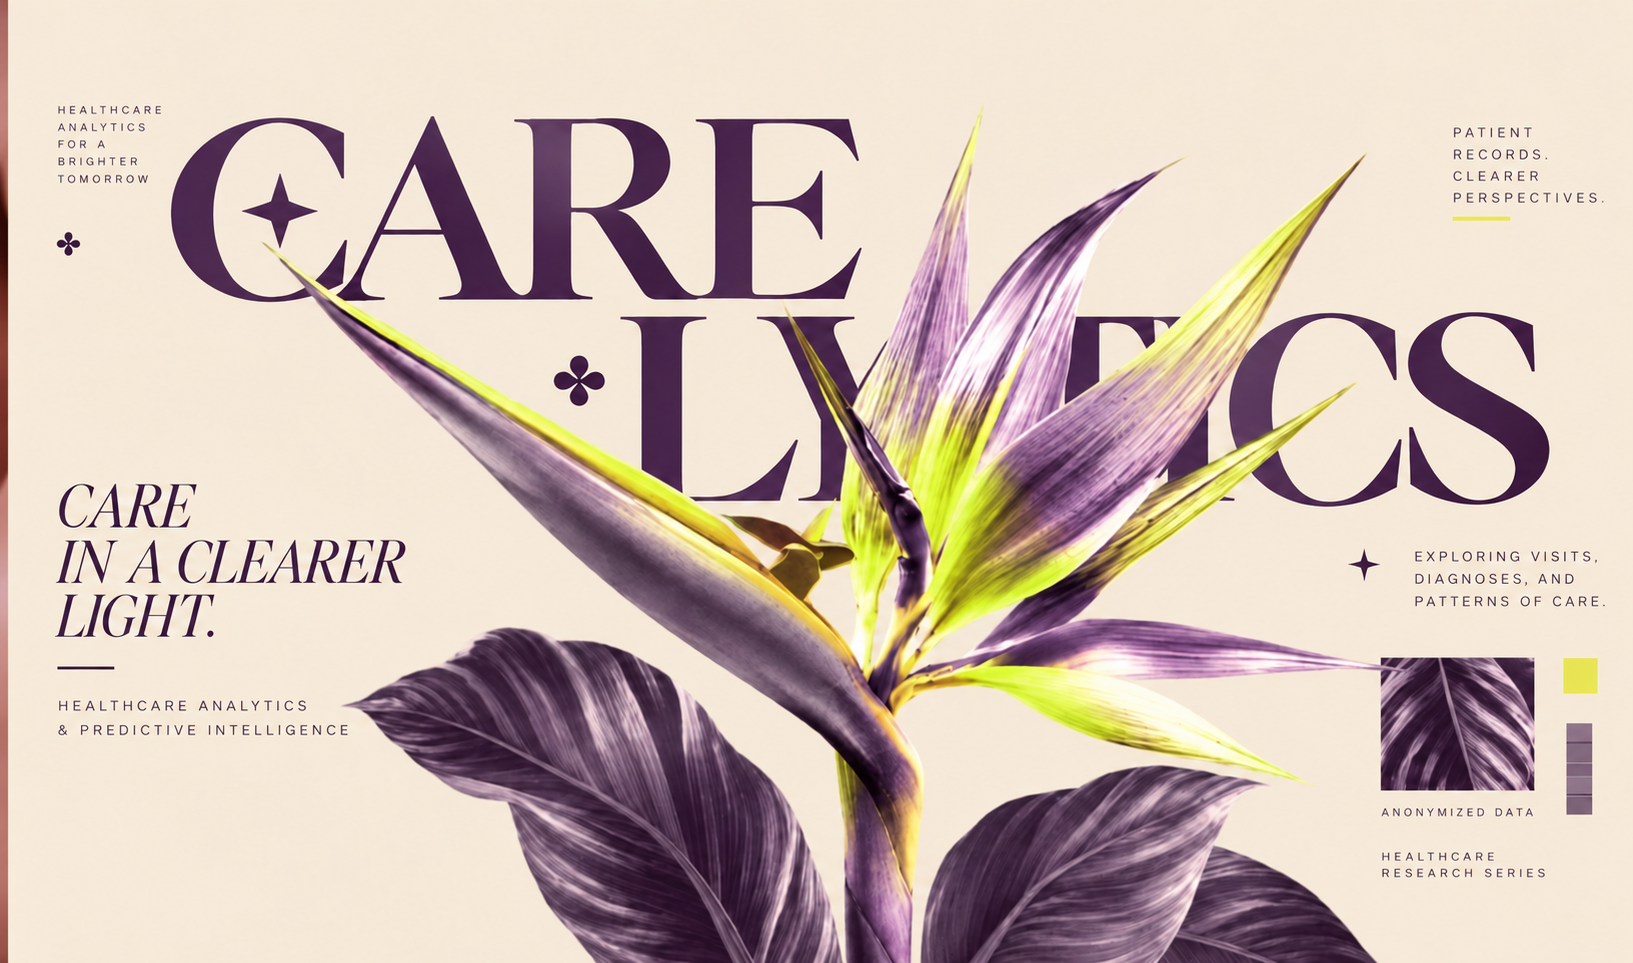

<div id="carelytics-title" style="border-radius:14px;overflow:hidden;margin:12px 0;box-shadow:0 4px 18px rgba(35,12,42,0.22);font-family:'Segoe UI',Arial,sans-serif;">
<div style="background:#FAF3EA;padding:28px 36px;display:flex;align-items:center;gap:28px;">
<div style="flex:0 0 150px;width:150px;height:150px;">
<img src="./carelytics-emblem.png.jpg" width="150" height="150" alt="Carelytics medical emblem" style="display:block;width:150px!important;height:150px!important;object-fit:cover;border-radius:16px;box-shadow:0 4px 14px rgba(43,16,53,0.18);"/>
</div>
<div style="flex:1;">
<div style="font-size:11px;font-weight:700;letter-spacing:3px;color:#788A00;text-transform:uppercase;">MEDICAL DATA ANALYSIS PROJECT</div>
<h1 style="font-size:40px;line-height:1.1;font-weight:700;color:#2B1035;margin:6px 0 8px;letter-spacing:0.5px;">Carelytics</h1>
<div style="font-size:14px;line-height:1.45;color:#53385C;max-width:680px;">Healthcare Analytics &amp; Predictive Intelligence &mdash; turning anonymized patient records into clear, evidence-based insight</div>
<div style="margin-top:16px;border-top:1.5px solid rgba(43,16,53,0.12);padding-top:14px;">
<div style="font-size:10px;font-weight:700;letter-spacing:2px;color:#788A00;margin-bottom:8px;">PROJECT TEAM</div>
<div style="display:flex;flex-wrap:wrap;gap:8px;">
<span style="background:#2B1035;color:#FAF3EA;font-size:12px;font-weight:600;padding:5px 12px;border-radius:6px;">Nagat Osama</span>
<span style="background:#2B1035;color:#FAF3EA;font-size:12px;font-weight:600;padding:5px 12px;border-radius:6px;">Hadeer Ashraf</span>
<span style="background:#2B1035;color:#FAF3EA;font-size:12px;font-weight:600;padding:5px 12px;border-radius:6px;">Magy Remon</span>
<span style="background:#2B1035;color:#FAF3EA;font-size:12px;font-weight:600;padding:5px 12px;border-radius:6px;">Ebrahim Attef</span>
<span style="background:#2B1035;color:#FAF3EA;font-size:12px;font-weight:600;padding:5px 12px;border-radius:6px;">Thomas Michel</span>
</div>
<div style="margin-top:12px;font-size:13px;color:#53385C;">
<span style="font-size:10px;font-weight:700;letter-spacing:2px;color:#788A00;margin-right:8px;">PROJECT SUPERVISOR</span>
<b style="color:#2B1035;font-size:14px;">Prof. Amal Mahmoud</b>
</div>
</div>
</div>
</div>
<div style="background:#2B1035;padding:10px 36px;font-size:10.5px;letter-spacing:1.5px;color:#E8DCD1;font-weight:500;">
ANONYMIZED HEALTHCARE DATA &nbsp;&middot;&nbsp; DATA QUALITY &nbsp;&middot;&nbsp; DESCRIPTIVE ANALYTICS &nbsp;&middot;&nbsp; PREDICTIVE MODELING &nbsp;&middot;&nbsp; INTERACTIVE REPORTING
</div>
</div>

<nav aria-label="Study sections" style="padding:22px;background:#f2e6d7;color:#4a2548;border-radius:6px"><h2 style="font:26px Georgia;margin:0 0 16px">Explore the study</h2><table role="presentation" style="width:100%;border:0;border-collapse:collapse"><tbody><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-1" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">01</span>Source data</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-3" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">02</span>Duplicates &amp; headers</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-5" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">03</span>Dates &amp; demographics</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-7" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">04</span>Amounts &amp; stays</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-9" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">05</span>Diagnosis codes</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-11" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">06</span>Visit history</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-13" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">07</span>Quality report</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-glance" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">08</span>Dataset at a glance</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-section-33" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">09</span>Patient profile</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-section-37" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">10</span>Trends over time</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-seasonality" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">11</span>Seasonality &amp; weekdays</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-section-44" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">12</span>Diagnosis patterns</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-cost" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">13</span>Cost &amp; spending</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-utilization" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">14</span>Utilization &amp; retention</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-section-53" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">15</span>Relationships</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-section-55" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">16</span>Statistical analysis</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-section-56" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">17</span>Research questions</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#clean-interpretation" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">18</span>Interpretation &amp; limits</a></td></tr><tr><td colspan="2" style="padding:4px"><a href="#modeling-overview" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">19 · Predictive modeling — observed 30-day return</a></td></tr><tr><td style="padding:4px"><a href="#additional-modeling-3" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">20 · Claim amount forecasting</a></td><td style="padding:4px"><a href="#additional-modeling-5" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">21 · Diagnosis-group prediction</a></td></tr><tr><td colspan="2" style="padding:4px"><a href="#modeling-scorecard" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">22 · Model scorecard</a></td></tr><tr><td style="padding:4px;width:50%"><a href="#ext-segmentation" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">23 · Patient segmentation</a></td><td style="padding:4px;width:50%"><a href="#ext-highcost" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">24 · High-cost patient detection</a></td></tr><tr><td style="padding:4px;width:50%"><a href="#ext-anomaly" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">25 · Anomaly detection</a></td><td style="padding:4px;width:50%"><a href="#ext-twostage" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">26 · Two-stage cost model</a></td></tr><tr><td style="padding:4px;width:50%"><a href="#ext-survival" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">27 · Survival: time to next visit</a></td><td style="padding:4px;width:50%"><a href="#ext-comorbidity" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">28 · Comorbidity network</a></td></tr><tr><td style="padding:4px;width:50%"><a href="#ext-sequence" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">29 · Next-diagnosis sequences</a></td><td style="padding:4px;width:50%"><a href="#ext-forecast" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">30 · Volume &amp; cost forecasting</a></td></tr><tr><td colspan="2" style="padding:4px"><a href="#ext-summary" style="display:block;padding:12px;background:#4a2548;color:#fff8ef;border-radius:5px;text-decoration:none;font:14px Arial">31 · Extended ML summary</a></td></tr><tr><td colspan="2" style="padding:4px"><a href="#carelytics-dashboard" style="display:block;padding:12px;background:#d9ef57;color:#4a2548;border-radius:5px;text-decoration:none;font:14px Arial">32 · Dashboard</a></td></tr><tr><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-conclusions" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">33</span>Conclusions &amp; next steps</a></td><td style="width:50%;padding:4px;vertical-align:top"><a href="#carelytics-appendix" style="display:block;padding:10px 12px;background:#faf5ed;border:1px solid #dac9cf;border-radius:5px;color:#4a2548;text-decoration:none;font:14px/1.5 Arial"><span style="color:#896b86;margin-right:10px">34</span>Appendix</a></td></tr></tbody></table></nav>

In [154]:
import re as _cl_re
import html as _cl_html
import math as _cl_math
from IPython.display import HTML as _cl_HTML, display as _cl_display

_CL_CSS = '''
<style id="carelytics-theme">
:root {--cl-paper:#f5eddf;--cl-plum:#4a2548;--cl-line:#dac9cf;--cl-lime:#d9ef57;}
body.jp-Notebook, .jp-NotebookPanel-notebook, .jp-Notebook, #notebook {background:#eee3d6!important;}
.jp-Notebook .jp-Cell {margin:14px 0!important;}
.jp-Notebook .jp-MarkdownOutput, .jp-Notebook .jp-OutputArea-output, #notebook-container {color:#382d38;}
.jp-Notebook .jp-MarkdownOutput {font-family:Arial,sans-serif;line-height:1.85;background:#faf5ed;padding:18px 26px;border-radius:5px;}
.jp-Notebook .jp-MarkdownOutput h1,.jp-Notebook .jp-MarkdownOutput h2,.jp-Notebook .jp-MarkdownOutput h3 {font-family:Georgia,serif;color:#4a2548;font-weight:400;}
.jp-Notebook .jp-MarkdownOutput p,.jp-Notebook .jp-MarkdownOutput li {color:#51434d;line-height:1.85;}
.jp-Notebook .jp-MarkdownOutput a {color:#73426e;}
.jp-Notebook .jp-MarkdownOutput img {max-width:100%;height:auto;}
.jp-Notebook .jp-InputArea-editor {background:#f8f3ed!important;border:1px solid #d9c8cf!important;border-left:3px solid #8c6688!important;border-radius:5px;}
.jp-Notebook .jp-InputPrompt,.jp-Notebook .jp-OutputPrompt {color:#886881!important;}
.jp-Notebook .jp-OutputArea-output pre {color:#463449;background:#f9f3eb;padding:14px;line-height:1.65;border-left:2px solid #c0a4bb;}
.jp-Notebook .jp-OutputArea-output {line-height:1.7;}
.jp-Notebook table.dataframe {border:0!important;border-collapse:separate!important;border-spacing:2px!important;font-family:Arial,sans-serif!important;font-size:12px!important;}
.jp-Notebook table.dataframe thead th {background:#4a2548!important;color:#fff8ef!important;padding:11px!important;border:0!important;white-space:normal!important;}
.jp-Notebook table.dataframe tbody th {background:#eee3e6!important;color:#4a2548!important;padding:10px!important;border:0!important;}
.jp-Notebook table.dataframe td {padding:10px!important;border:0!important;font-variant-numeric:tabular-nums;}
.jp-Notebook table.dataframe tbody tr:hover td {outline:1px solid #b191ab;outline-offset:-1px;}
.jp-Notebook table.dataframe caption {caption-side:bottom;text-align:left;color:#725b6e;font:11px Arial,sans-serif;padding:12px 3px;}
.jp-Notebook .jp-RenderedHTMLCommon hr {border-color:#d6c2cf;}
@media print {.jp-Notebook {background:white!important;}table.dataframe td,table.dataframe th {print-color-adjust:exact;-webkit-print-color-adjust:exact;}}

/* Full-width cover, with its original proportions and no crop. */
.jp-Notebook .jp-Cell:has(img[alt^="Carelytics"]) .jp-InputPrompt {display:none!important;}
.jp-Notebook .jp-MarkdownOutput:has(img[alt^="Carelytics"]) {padding:0!important;margin:0!important;background:transparent!important;border-radius:0!important;overflow:hidden;}
.jp-Notebook .jp-MarkdownOutput:has(img[alt^="Carelytics"]) p {margin:0!important;padding:0!important;max-width:none!important;}
.jp-Notebook img[alt^="Carelytics"] {display:block!important;width:100%!important;max-width:none!important;height:auto!important;margin:0!important;border-radius:0!important;}
#notebook-container .text_cell:has(img[alt^="Carelytics"]) .prompt {display:none!important;}
#notebook-container .text_cell_render:has(img[alt^="Carelytics"]) {padding:0!important;}
#notebook-container img[alt^="Carelytics"] {display:block;width:100%!important;height:auto!important;max-width:none!important;}

.jp-Notebook .jp-MarkdownOutput {font-size:14px;line-height:1.75;}
.jp-Notebook .jp-OutputArea-output {overflow-x:auto;max-width:100%;}
.jp-Notebook .jp-OutputArea-output img {max-width:100%;height:auto;}
.jp-Notebook .jp-RenderedHTMLCommon table {max-width:100%;}
.jp-Notebook a:focus-visible {outline:3px solid #75446e;outline-offset:3px;}
@media(max-width:700px){.jp-Notebook .jp-MarkdownOutput {padding:14px!important;} .cl-nav-grid {grid-template-columns:1fr!important;}}
</style>'''

def _cl_heat_table(markup):
    def paint(table_match):
        table=table_match.group(0)
        table=_cl_re.sub(r'\sdata-carelytics-heat="[^"]*"','',table)
        table=_cl_re.sub(r'<caption[^>]*>.*?</caption>','',table,flags=_cl_re.S)
        header=_cl_re.search(r'<thead.*?</thead>',table,_cl_re.S)
        headers=[]
        if header:
            header_rows=_cl_re.findall(r'<tr[^>]*>(.*?)</tr>',header.group(),_cl_re.S)
            if header_rows:
                headers=[_cl_html.unescape(_cl_re.sub('<[^>]+>','',x)).strip().lower() for x in _cl_re.findall(r'<th[^>]*>(.*?)</th>',header_rows[-1],_cl_re.S)]
        body=_cl_re.search(r'<tbody[^>]*>(.*?)</tbody>',table,_cl_re.S)
        if not body: return table
        rows=_cl_re.findall(r'<tr[^>]*>.*?</tr>',body.group(1),_cl_re.S)
        def number(content):
            text=_cl_html.unescape(_cl_re.sub('<[^>]+>','',content)).strip().replace(',','')
            if not _cl_re.fullmatch(r'[-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?%?',text): return None
            try:
                val=float(text.rstrip('%'))
                return val if abs(val)!=float('inf') else None
            except ValueError: return None
        limits={}
        for row in rows:
            cells=_cl_re.findall(r'<(td|th)\b[^>]*>(.*?)</\1>',row,_cl_re.S)
            for col,(tag,content) in enumerate(cells):
                label=headers[col] if col<len(headers) else ''
                if tag!='td' or any(x in label for x in ['patient_id','source_row_id','date','year','month','load_order','visit_number']): continue
                value=number(content)
                if value is not None: limits.setdefault(col,[]).append(value)
        limits={k:sorted(set(v)) for k,v in limits.items()}
        logarithmic={k for k,v in limits.items() if len(v)>1 and v[-1]-v[0]>100 and (v[-1]-v[0])/max(abs(v[len(v)//2]-v[0]),1)>20}
        def paint_row(match):
            row=match.group(0);col=-1
            def cell(match):
                nonlocal col
                col+=1
                tag,attrs,content=match.groups()
                if tag=='th': return match.group(0)
                value=number(content)
                background='#f4ece3';foreground='#493b47'
                if col in limits and value is not None:
                    ordered=limits[col];low,high=ordered[0],ordered[-1]
                    if high==low:
                        t=0.0
                    elif col in logarithmic:
                        t=_cl_math.log1p(value-low)/_cl_math.log1p(high-low)
                    else:
                        t=(value-low)/(high-low)
                    # Continuous sequential colors encode numeric magnitude, not rank.
                    stops=[(250,245,250),(231,214,236),(202,173,213),(165,125,181),(123,80,144),(83,44,106),(48,19,67)]
                    pos=t*(len(stops)-1);idx=min(int(pos),len(stops)-2);fraction=pos-idx
                    rgb=tuple(round(a+(b-a)*fraction) for a,b in zip(stops[idx],stops[idx+1]))
                    background='#%02x%02x%02x'%rgb
                    luminance=sum(w*(v/255/12.92 if v/255<=.04045 else ((v/255+.055)/1.055)**2.4) for w,v in zip((.2126,.7152,.0722),rgb))
                    dark_lum=sum(w*(v/255/12.92 if v/255<=.04045 else ((v/255+.055)/1.055)**2.4) for w,v in zip((.2126,.7152,.0722),(8,4,10)))
                    foreground='#ffffff' if 1.05/(luminance+.05)>=(luminance+.05)/(dark_lum+.05) else '#08040a'
                attrs=_cl_re.sub(r'\sstyle="[^"]*"','',attrs)
                return f'<td{attrs} style="background:{background};color:{foreground};padding:10px;border:0;font-variant-numeric:tabular-nums;">{content}</td>'
            return _cl_re.sub(r'<(td|th)\b([^>]*)>(.*?)</\1>',cell,row,flags=_cl_re.S)
        painted=_cl_re.sub(r'<tr[^>]*>.*?</tr>',paint_row,body.group(1),flags=_cl_re.S)
        table=table[:body.start(1)]+painted+table[body.end(1):]
        table=table.replace('<table','<table data-carelytics-heat="true"',1)
        table=_cl_re.sub(r'<th\b([^>]*)>',lambda m:'<th'+_cl_re.sub(r'\sstyle="[^"]*"','',m.group(1))+' style="background:#4a2548;color:#fff8ef;padding:11px;border:0;">',table)
        log_names=', '.join(_cl_html.escape(headers[k] if k<len(headers) else str(k)) for k in sorted(logarithmic))
        note=' Log1p magnitude scale for skewed columns: '+log_names+'.' if log_names else ' Linear magnitude scale.'
        legend='<span style="display:inline-block;width:110px;height:9px;margin-right:8px;background:linear-gradient(90deg,#faf5fa,#e7d6ec,#caadd5,#a57db5,#7b5090,#532c6a,#301343);" aria-hidden="true"></span>'
        return table.replace('</table>','<caption style="caption-side:bottom;text-align:left;color:#614764;font:11px/1.7 Arial,sans-serif;padding:12px 3px;">'+legend+'Lower to higher actual values within each displayed column.'+note+' IDs/dates are unscaled; equal values have equal shades.</caption></table>')

    return _cl_re.sub(r'<table\b.*?</table>',paint,markup,flags=_cl_re.S)

import pandas as _cl_pd
if not hasattr(_cl_pd.DataFrame,'_carelytics_original_repr_html'):
    _cl_pd.DataFrame._carelytics_original_repr_html=_cl_pd.DataFrame._repr_html_
def _cl_repr(self):
    markup=_cl_pd.DataFrame._carelytics_original_repr_html(self)
    return _cl_heat_table(markup) if markup else markup
_cl_pd.DataFrame._repr_html_=_cl_repr
_cl_display(_cl_HTML(_CL_CSS))


In [155]:
# Carelytics visual system: one palette, one chart theme and reusable HTML blocks for every section below.
import html as _h
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display

CL = dict(plum='#4a2548', mauve='#75446e', orchid='#8f6a9e', dusk='#896b86', sand='#f2e6d7', paper='#faf5ed',
          line='#dac9cf', lime='#d9ef57', ink='#382d38', muted='#725b6e', teal='#4f7f86', amber='#c0894f', rose='#b5546c')
CL_CYCLE = [CL['mauve'], CL['teal'], CL['amber'], CL['orchid'], CL['rose'], CL['dusk']]
CL_SEQ = LinearSegmentedColormap.from_list('carelytics_seq', ['#faf5fa', '#e7d6ec', '#caadd5', '#a57db5', '#7b5090', '#532c6a', '#301343'])
CL_DIV = LinearSegmentedColormap.from_list('carelytics_div', [CL['teal'], '#f5eddf', CL['mauve']])
CL_RC = {'figure.facecolor': CL['paper'], 'axes.facecolor': CL['paper'], 'savefig.facecolor': CL['paper'],
         'axes.edgecolor': CL['dusk'], 'axes.labelcolor': CL['plum'], 'axes.titlecolor': CL['plum'],
         'axes.titleweight': 'normal', 'axes.titlesize': 13, 'axes.titlepad': 12, 'axes.labelsize': 10.5,
         'axes.grid': True, 'grid.color': '#e6d9dd', 'grid.linewidth': .8, 'axes.axisbelow': True,
         'axes.spines.top': False, 'axes.spines.right': False, 'xtick.color': CL['muted'], 'ytick.color': CL['muted'],
         'text.color': CL['plum'], 'legend.frameon': False, 'figure.dpi': 110, 'font.family': 'sans-serif',
         'font.sans-serif': ['Arial', 'DejaVu Sans'], 'axes.prop_cycle': mpl.cycler(color=CL_CYCLE)}
plt.rcParams.update(CL_RC)

AGE_BINS = [0, 18, 35, 50, 65, 111]
AGE_LABELS = ['0-17', '18-34', '35-49', '50-64', '65+']

def nice(x):
    """ICD_CHAPTER_NAME -> Icd Chapter Name"""
    return str(x).replace('_', ' ').title()

def strong(x):
    return '<b>%s</b>' % _h.escape(str(x))

def cl_kpis(items):
    """Row of headline tiles. items = [(label, value, note), ...]"""
    tiles = ''.join(
        '<div style="background:%s;border:1px solid %s;border-top:3px solid %s;border-radius:5px;padding:16px 18px;">'
        '<div style="font:10px Arial;letter-spacing:2px;text-transform:uppercase;color:%s">%s</div>'
        '<div style="font:28px/1.25 Georgia,serif;color:%s;margin:6px 0 2px">%s</div>'
        '<div style="font:12px/1.5 Arial;color:%s">%s</div></div>'
        % (CL['sand'], CL['line'], CL['lime'], CL['dusk'], _h.escape(str(l)), CL['plum'], _h.escape(str(v)), CL['muted'], _h.escape(str(n)))
        for l, v, n in items)
    display(HTML('<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(190px,1fr));gap:10px;margin:8px 0">%s</div>' % tiles))

def cl_takeaways(title, items, caveat=None):
    """Styled findings card. Items may contain <b> tags; wrap data values with strong()."""
    li = ''.join('<li style="margin:6px 0">%s</li>' % x for x in items)
    cv = ('<p style="margin:10px 0 0;font:12px/1.6 Arial;color:%s">%s</p>' % (CL['muted'], _h.escape(caveat))) if caveat else ''
    display(HTML('<div style="padding:18px 22px;background:%s;border-left:3px solid %s;color:%s;font:14px/1.75 Arial">'
                 '<strong>%s</strong><ul style="margin:8px 0 0 18px;padding:0;color:#51434d">%s</ul>%s</div>'
                 % (CL['paper'], CL['mauve'], CL['plum'], _h.escape(title), li, cv)))

def cl_table(frame, caption=None):
    """Plain themed table (no heat shading) for text-heavy tables such as dictionaries."""
    head = ''.join('<th style="background:%s;color:#fff8ef;padding:10px;text-align:left;font:12px Arial;border:0">%s</th>'
                   % (CL['plum'], _h.escape(str(c))) for c in frame.columns)
    rows = []
    for i, (_, row) in enumerate(frame.iterrows()):
        bg = CL['paper'] if i % 2 == 0 else '#f4ece3'
        cells = ''.join('<td style="background:%s;color:#493b47;padding:9px 10px;font:12px/1.5 Arial;border:0;vertical-align:top">%s</td>'
                        % (bg, _h.escape(str(v))) for v in row)
        rows.append('<tr>%s</tr>' % cells)
    cap = ('<caption style="caption-side:bottom;text-align:left;color:%s;font:11px Arial;padding:10px 3px">%s</caption>'
           % (CL['muted'], _h.escape(caption))) if caption else ''
    display(HTML('<div style="overflow-x:auto"><table style="border-collapse:separate;border-spacing:2px;width:100%%">%s'
                 '<thead><tr>%s</tr></thead><tbody>%s</tbody></table></div>' % (cap, head, ''.join(rows))))

def cl_note(text):
    display(HTML('<p style="font:12px/1.6 Arial;color:%s;margin:4px 2px 14px">%s</p>' % (CL['muted'], _h.escape(text))))


##### <div style="padding:18px 22px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.75 Arial"><strong>About this analysis</strong><p style="margin:8px 0">Every count in this notebook is computed live from your file; the first figures appear in <em>Dataset at a Glance</em>.</p><p style="margin:8px 0">Source data and excluded records are preserved separately. Findings describe the selected subset.</p><details><summary style="cursor:pointer;font-weight:bold">Data notes and limitations</summary><p>The analysis dataset (<code>cleaned_data.csv</code>) requires an identified patient, a reliable visit date, a valid age and gender, observed amounts and a mapped ICD chapter. Discharge date and stay length may be blank (stay length is almost always zero days and carries little information). <code>total_claim</code> is recorded as 0 for most of 2019&ndash;2022 although its components are positive, so it is rebuilt from the five components only where the source reports 0 or blank (flagged in <code>total_claim_rebuilt</code>). <code>disease_category</code> is the ICD chapter of the first listed code, so changes in how many codes are listed cannot create fake category shifts. <code>cleaned_records.csv</code> is a separate audit archive retaining incomplete records. Excluding incomplete records can bias findings; the <em>representativeness check</em> after the glance section compares kept and excluded rows. Clinical code validity and source coverage still require verification. Return outcomes mean later observed visit days, not inpatient readmission. Full-history counts are retrospective only.</p></details></div>


<div id="clean-1" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Load source without modifying it</h2></div>

In [156]:
from pathlib import Path
import json, re, hashlib
import pandas as pd
import numpy as np
# PROJECT and SOURCE are set in the setup cell.
OUT = PROJECT / 'cleaning_outputs'
OUT.mkdir(exist_ok=True)
raw = pd.read_csv(SOURCE, low_memory=False)
raw_missing = raw.isna().sum()
source_hash = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
print('Source records:', len(raw), '| Source columns:', len(raw.columns))
display(raw.head())

Source records: 538544 | Source columns: 39


,source_year,source_month,source_sheet,load_order,no,patient_id,visit_date,discharge_date,age,gender,...,target_disease_fine,target_disease_coarse,total_visits,visits_this_year,visit_number,days_since_last_visit,days_to_next_visit,revisit_30,revisit_90,revisit_180
0,2021,AUGUST,ClaimData,62,13.0,312725a82128217f,2021-08-01,2021-08-01 00:00:00,72.0,M,...,N34.1,GENITOURINARY_SYSTEM_DISORDERS,1.0,1.0,1.0,NaN,NaN,False,False,False
1,2020,November,ClaimData,59,868.0,f152bdaaf63a4104,2020-11-14,2020-11-14 00:00:00,60.0,F,...,M47.8,SPONDYLOSIS,1.0,1.0,1.0,NaN,NaN,False,False,False
2,2020,November,ClaimData,59,202.0,bd77ccca47ca8af7,2020-11-04,2020-11-04 00:00:00,60.0,F,...,I10,HYPERTENSION,1.0,1.0,1.0,NaN,NaN,False,False,False
3,2022,MAY,ClaimData,74,791.0,6bdc604f6d5d4d74,2022-05-17,2022-05-17 00:00:00,23.0,M,...,"M79.1,A02.0",ENTERITIS,1.0,1.0,1.0,NaN,NaN,False,False,False
4,2022,APRIL,ClaimData,71,613.0,e6c1177652a56955,2022-04-17,2022-04-17 00:00:00,32.0,M,...,"N39,M79.1",GENITOURINARY_SYSTEM_DISORDERS,1.0,1.0,1.0,NaN,NaN,False,False,False


<div id="clean-3" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Identify duplicate rows and embedded headers</h2></div>

In [157]:
# Remove only exact full-source-row repeats; retain an audit copy for review.
duplicate_mask = raw.duplicated(keep='first')
duplicate_rows = raw.loc[duplicate_mask].copy()
duplicate_rows.insert(0, 'source_row_id', duplicate_rows.index + 2)
work = raw.loc[~duplicate_mask].copy()
work.insert(0, 'source_row_id', work.index + 2)
header_votes = pd.Series(0, index=work.index)
for col, pattern in [('patient_id',r'PATIENT.?ID|MEMBER.?ID'),('age',r'AGE'),('gender',r'GENDER|SEX'),('total_claim',r'TOTAL(?:\s*\(.*\))?'),('drugs_amount',r'DRUGS(?:\s*\(.*\))?')]:
    header_votes += work[col].astype('string').str.strip().str.upper().str.fullmatch(pattern,na=False).astype(int)
embedded_headers = work.loc[header_votes.ge(2)].copy()
work = work.loc[header_votes.lt(2)].copy()
df_all = work.reset_index(drop=True)
print('Exact duplicate rows removed:', len(duplicate_rows))
print('Embedded headers removed (at least two header matches):', len(embedded_headers))

Exact duplicate rows removed: 179276
Embedded headers removed (at least two header matches): 32


<div id="clean-5" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Normalize text, dates and demographics; preserve originals</h2></div>

In [158]:
null_tokens = {'','NAN','NONE','NULL','N/A','NA','<NA>','UNKNOWN','NOT KNOWN','NOT AVAILABLE','-','--'}
text_cols = df_all.select_dtypes(include=['object','string']).columns.tolist()
for col in text_cols:
    df_all[col] = df_all[col].astype('string').str.strip().str.replace(r'\s+',' ',regex=True)
    df_all.loc[df_all[col].str.upper().isin(null_tokens),col] = pd.NA
for col in ['age','gender','visit_date','discharge_date','icd10','disease_category','target_disease_coarse','target_disease_fine','age_at_visit']:
    df_all[col+'_original'] = df_all[col]
for col in ['total_visits','visits_this_year','visit_number','days_since_last_visit','days_to_next_visit','revisit_30','revisit_90','revisit_180']:
    df_all[col+'_original'] = df_all[col]
for col in ['visit_date','discharge_date']:
    parsed = pd.to_datetime(df_all[col],format='mixed',errors='coerce')
    df_all[col+'_parse_failed'] = df_all[col].notna() & parsed.isna()
    df_all[col] = parsed.dt.normalize()
df_all['source_year'] = pd.to_numeric(df_all['source_year'],errors='coerce').astype('Int64')
month_lookup = {name.lower(): i for i,name in enumerate(['January','February','March','April','May','June','July','August','September','October','November','December'],1)}
month_lookup.update({k[:3]:v for k,v in list(month_lookup.items())})
month_lookup['sept']=9
month_num=df_all.source_month.str.lower().map(month_lookup)
df_all['source_month_unrecognized']=df_all.source_month.notna() & month_num.isna()
import calendar
df_all['source_month']=month_num.map(dict(enumerate(calendar.month_name))).astype('string')
# Month-only estimates are stored separately and never replace an unknown day.
df_all['visit_month_estimate']=pd.to_datetime(dict(year=df_all.source_year,month=month_num,day=1),errors='coerce')
df_all['visit_date_missing']=df_all.visit_date.isna()
df_all['visit_date_estimated']=False
df_all['source_date_conflict']=(df_all.visit_date.notna() & ((df_all.visit_date.dt.year.ne(df_all.source_year)) | (df_all.visit_date.dt.month.ne(month_num)))).fillna(False)
min_year=int(raw.source_year.min()); max_year=int(raw.source_year.max())
df_all['visit_date_outside_source_period']=df_all.visit_date.notna() & ~df_all.visit_date.dt.year.between(min_year,max_year)
df_all['date_reliable']=df_all.visit_date.notna() & ~df_all.source_date_conflict & ~df_all.visit_date_outside_source_period
df_all['gender']=df_all.gender.str.upper().replace({'FEMALE':'F','MALE':'M'})
df_all.loc[~df_all.gender.isin(['F','M']),'gender']='Unknown'
gender_counts=df_all.loc[df_all.gender.isin(['F','M']) & df_all.patient_id.notna()].groupby('patient_id').gender.nunique()
conflicts=gender_counts[gender_counts.gt(1)].index
df_all['gender_conflict']=df_all.patient_id.isin(conflicts)
df_all.loc[df_all.gender_conflict,'gender']='Unknown'
df_all['age']=pd.to_numeric(df_all.age,errors='coerce')
df_all['age_invalid']=df_all.age.notna() & ~df_all.age.between(0,110)
df_all.loc[df_all.age_invalid,'age']=np.nan
df_all['age_imputed']=False
# Only an earlier reliable observation may supply a missing/invalid age.
ordered=df_all.loc[df_all.patient_id.notna() & df_all.date_reliable].sort_values(['patient_id','visit_date','source_row_id']).copy()
valid=ordered.age.notna()
ordered['known_age']=ordered.age.where(valid).groupby(ordered.patient_id).ffill()
ordered['known_date']=ordered.visit_date.where(valid).groupby(ordered.patient_id).ffill()
elapsed=(ordered.visit_date-ordered.known_date).dt.days/365.2425
estimated=np.floor(ordered.known_age+elapsed)
fill=ordered.age.isna() & estimated.between(0,110) & elapsed.between(0,10)
df_all.loc[ordered.index[fill],'age']=estimated.loc[fill]
df_all.loc[ordered.index[fill],'age_imputed']=True
# Flag longitudinal age inconsistencies without silently rewriting plausible ages.
observed=ordered.loc[valid].copy()
prior_age=observed.groupby('patient_id').age.shift()
prior_date=observed.groupby('patient_id').visit_date.shift()
expected=prior_age+(observed.visit_date-prior_date).dt.days/365.2425
df_all['age_conflict']=False
df_all.loc[observed.index,'age_conflict']=(observed.age-expected).abs().gt(2).fillna(False)
df_all['age_at_visit']=df_all.age
df_all['age_group']=pd.cut(df_all.age,bins=[0,18,35,50,65,111],right=False,labels=['0-17','18-34','35-49','50-64','65+'])
print('Missing ages retained:', df_all.age.isna().sum(), '| Past-only imputations:',df_all.age_imputed.sum())
print('Patient gender conflicts:',len(conflicts))


Missing ages retained: 157642 | Past-only imputations: 27
Patient gender conflicts: 1614


<div id="clean-7" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Validate money and discharge dates without inventing values</h2></div>

In [159]:
money_cols=['drugs_amount','investigation_amount','outpatient_amount','inpatient_amount','service_amount','total_claim']
for col in money_cols:
    df_all[col+'_original']=df_all[col]
    text=df_all[col].astype('string').str.replace(',','',regex=False)
    text=text.str.replace(r'^\((.+)\)$',r'-\1',regex=True)
    values=pd.to_numeric(text,errors='coerce')
    df_all[col+'_nonfinite']=values.notna() & ~np.isfinite(values)
    values=values.mask(df_all[col+'_nonfinite'])
    df_all[col+'_parse_failed']=df_all[col].notna() & values.isna()
    df_all[col+'_negative']=values.lt(0).fillna(False)
    df_all[col]=values.mask(values.lt(0))
    q1,q3=df_all[col].quantile([.25,.75]);iqr=q3-q1
    df_all[col+'_outlier']=df_all[col].gt(q3+3*iqr).fillna(False) if iqr>0 else False
    # Large non-negative amounts remain available; no automatic winsorization.
component_cols=money_cols[:-1]
# The source records total_claim as 0 for most of 2019-2022 while its components are positive.
# Rebuild the total from the components ONLY where the reported total is 0/blank (never over a negative or a positive total).
comp_sum_any=df_all[component_cols].sum(axis=1,min_count=1)
rebuild=(df_all.total_claim.isna() | df_all.total_claim.eq(0)) & ~df_all.total_claim_negative & comp_sum_any.gt(0)
df_all['total_claim_rebuilt']=rebuild
df_all.loc[rebuild,'total_claim']=comp_sum_any[rebuild]
q1,q3=df_all.total_claim.quantile([.25,.75]);iqr=q3-q1
df_all['total_claim_outlier']=df_all.total_claim.gt(q3+3*iqr).fillna(False) if iqr>0 else False
CONSTANT_MONEY=[c for c in money_cols if df_all[c].dropna().nunique()<=1]
print('total_claim rebuilt from components:',int(rebuild.sum()),'rows | constant money columns (no information):',CONSTANT_MONEY)
df_all['components_complete']=df_all[component_cols].notna().all(axis=1)
df_all['claim_components_sum']=df_all[component_cols].sum(axis=1,min_count=len(component_cols))
df_all['claim_components_difference']=df_all.total_claim-df_all.claim_components_sum
df_all['claim_components_mismatch']=df_all.components_complete & df_all.total_claim.notna() & df_all.claim_components_difference.abs().gt(.01)
# This is a diagnostic, not an accounting identity verified by a data dictionary.
df_all['discharge_before_visit']=df_all.discharge_date.notna() & df_all.visit_date.notna() & df_all.discharge_date.lt(df_all.visit_date)
df_all['discharge_date_unreliable']=df_all.discharge_before_visit | ~df_all.date_reliable
df_all['length_of_stay']=(df_all.discharge_date-df_all.visit_date).dt.days.where(~df_all.discharge_date_unreliable)
df_all['discharge_date_imputed']=False
df_all['g_drg']=df_all.g_drg.str.upper()
display(df_all[money_cols+['length_of_stay']].describe())


total_claim rebuilt from components: 76969 rows | constant money columns (no information): ['investigation_amount']


,drugs_amount,investigation_amount,outpatient_amount,inpatient_amount,service_amount,total_claim,length_of_stay
count,238434.0,238436.0,238435.0,238436.0,238437.0,238426.0,102163.000000
mean,11.448122,0.0,8.117388,0.531715,11.341432,34.555975,0.019420
std,369.634266,0.0,378.372004,27.48549,287.752344,878.428532,0.302581
min,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
25%,0.0,0.0,0.0,0.0,0.0,10.2,0.000000
50%,0.3,0.0,0.0,0.0,10.2,14.64,0.000000
75%,6.4,0.0,10.08,0.0,12.24,21.44,0.000000
max,59127.524,0.0,67348.86,7240.34,32931.36,126034.484,13.000000


<div id="clean-9" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Normalize ICD structure and replace untrusted inherited categories</h2></div>

In [160]:
icd_pattern=re.compile(r'^[A-Z][0-9]{2}(?:\.[A-Z0-9]{1,4})?$')
def parse_codes(value):
    if pd.isna(value): return [],[]
    codes=list(dict.fromkeys(x.strip().upper() for x in re.split(r'[,;|]',str(value)) if x.strip()))
    return [x for x in codes if icd_pattern.fullmatch(x)], [x for x in codes if not icd_pattern.fullmatch(x)]
parsed=df_all.icd10.apply(parse_codes)
df_all['icd10_codes']=parsed.map(lambda x:','.join(x[0]) if x[0] else pd.NA).astype('string')
df_all['icd10_invalid_tokens']=parsed.map(lambda x:','.join(x[1]) if x[1] else pd.NA).astype('string')
df_all['icd10_format_issue']=df_all.icd10_invalid_tokens.notna()
df_all['icd10']=df_all.icd10_codes
df_all['diagnosis_clean']=df_all.diagnosis_text.astype('string').str.upper().str.strip()
# Syntax checks do not establish code existence or clinical correctness.
chapter_ranges=[('A00','B99','INFECTIOUS_PARASITIC'),('C00','D48','NEOPLASMS'),('D50','D89','BLOOD_IMMUNE'),('E00','E90','ENDOCRINE_METABOLIC'),('F00','F99','MENTAL_BEHAVIOURAL'),('G00','G99','NERVOUS_SYSTEM'),('H00','H59','EYE'),('H60','H95','EAR'),('I00','I99','CIRCULATORY'),('J00','J99','RESPIRATORY'),('K00','K93','DIGESTIVE'),('L00','L99','SKIN'),('M00','M99','MUSCULOSKELETAL'),('N00','N99','GENITOURINARY'),('O00','O99','PREGNANCY_CHILDBIRTH'),('P00','P96','PERINATAL'),('Q00','Q99','CONGENITAL'),('R00','R99','SYMPTOMS_SIGNS'),('S00','T98','INJURY_POISONING'),('V01','Y98','EXTERNAL_CAUSES'),('Z00','Z99','HEALTH_SERVICE_CONTACT'),('U00','U99','SPECIAL_PURPOSE')]
def chapter(code):
    base=code[:3]
    return next((label for low,high,label in chapter_ranges if low<=base<=high),'UNMAPPED')
chapter_lists=parsed.map(lambda x:list(dict.fromkeys(chapter(c) for c in x[0])))
df_all['icd10_chapters']=chapter_lists.map(lambda x:','.join(x) if x else pd.NA)
df_all['icd10_chapter']=chapter_lists.map(lambda x:x[0] if x else pd.NA)
# First listed code decides the category. Counting 'several chapters' as its own class would mix real disease with a
# change in how many codes the source lists per claim (0% of claims before 2021, about a third afterwards).
df_all['disease_category']=chapter_lists.map(lambda x:x[0] if x else 'UNKNOWN')
df_all['multi_chapter']=chapter_lists.map(lambda x:len(x)>1).astype(bool)
df_all['disease_categories_all']=df_all.icd10_chapters
df_all['target_disease_fine']=df_all.icd10_codes
df_all['target_disease_coarse']=df_all.disease_category
df_all['diagnosis_category_unverified']=True
df_all['diagnosis_category_level']='ICD chapter of the first listed code (syntax-based, not clinically validated)'
print('Malformed ICD rows:',df_all.icd10_format_issue.sum())
print('No clinical code imputation performed. Inherited fine disease labels preserved only as originals.')


Malformed ICD rows: 823
No clinical code imputation performed. Inherited fine disease labels preserved only as originals.


<div id="clean-11" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Recompute temporal features on distinct observed days and mark censoring</h2></div>

In [161]:
identified=df_all.patient_id.notna()
df_all['total_records']=df_all.patient_id.map(df_all.loc[identified].groupby('patient_id').size()).astype('Int64')
# Any missing/conflicting date makes that patient's sequence incomplete.
incomplete=df_all.loc[identified].groupby('patient_id').date_reliable.all()
complete_ids=incomplete[incomplete].index
df_all['temporal_history_complete']=df_all.patient_id.isin(complete_ids)
episodes=df_all.loc[identified & df_all.date_reliable,['patient_id','visit_date']].drop_duplicates().sort_values(['patient_id','visit_date']).reset_index(drop=True)
episodes['visit_number']=episodes.groupby('patient_id').cumcount()+1
episodes['total_visits']=episodes.groupby('patient_id').visit_date.transform('size')
episodes['year']=episodes.visit_date.dt.year
episodes['visits_this_year']=episodes.groupby(['patient_id','year']).visit_date.transform('size')
episodes['days_since_last_visit']=episodes.groupby('patient_id').visit_date.diff().dt.days
episodes['days_to_next_visit']=(episodes.groupby('patient_id').visit_date.shift(-1)-episodes.visit_date).dt.days
observation_end=episodes.visit_date.max()
episodes['followup_days_observed']=(observation_end-episodes.visit_date).dt.days
episodes['temporal_history_complete']=episodes.patient_id.isin(complete_ids)
for window in [30,90,180]:
    positive=episodes.days_to_next_visit.between(1,window)
    known=episodes.temporal_history_complete & (positive | episodes.followup_days_observed.ge(window))
    episodes[f'revisit_{window}']=positive.where(known).astype('boolean')
    episodes[f'revisit_{window}_eligible']=known
    # Labels concern a later observed visit day, not inpatient readmission.
features=['total_visits','visits_this_year','visit_number','days_since_last_visit','days_to_next_visit','followup_days_observed']+[f'revisit_{w}' for w in [30,90,180]]+[f'revisit_{w}_eligible' for w in [30,90,180]]
df_all=df_all.drop(columns=[c for c in features if c in df_all]).merge(episodes[['patient_id','visit_date']+features],how='left',on=['patient_id','visit_date'],validate='many_to_one')
for col in [f'revisit_{w}' for w in [30,90,180]]: df_all[col]=df_all[col].astype('boolean')
df_all['year']=df_all.visit_date.dt.year
df_all['month']=df_all.visit_date.dt.month
df_all['has_critical_missing']=df_all.patient_id.isna() | ~df_all.date_reliable
# EDA uses observed dated records; the full cleaned file retains undated/anonymous rows.
df=df_all.loc[df_all.patient_id.notna() & df_all.date_reliable].copy()
df=df.sort_values(['patient_id','visit_date','source_row_id']).reset_index(drop=True)
analysis_columns=['source_row_id','source_year','source_month','source_sheet','load_order','patient_id','visit_date','discharge_date','age','age_at_visit','age_group','gender','diagnosis_text','diagnosis_clean','icd10','icd10_codes','icd10_chapter','icd10_chapters','disease_category','disease_categories_all','target_disease_fine','target_disease_coarse']+money_cols+['total_claim_rebuilt','multi_chapter','length_of_stay','total_visits','visits_this_year','visit_number','year','month','age_imputed','age_conflict']
analysis_candidate=df.copy()
# Stay length is almost always 0 days and discharge date is blank for most rows, so they are NOT required fields.
REQUIRED_FIELDS=[c for c in analysis_columns if c not in ('discharge_date','length_of_stay')]
required_complete=df[REQUIRED_FIELDS].notna().all(axis=1)
demographics_valid=df.gender.isin(['F','M']) & ~df.age_conflict & ~df.gender_conflict
diagnosis_valid=~df.icd10_format_issue & ~df.disease_category.isin(['UNKNOWN','UNMAPPED']) & ~df.icd10_chapters.fillna('').str.contains('UNMAPPED',regex=False)
keep_ready=required_complete & demographics_valid & diagnosis_valid
exclusions=pd.DataFrame({'source_row_id':df.source_row_id,'incomplete_required_fields':~required_complete,'unresolved_demographics':~demographics_valid,'malformed_or_unknown_icd_category':~diagnosis_valid})
exclusions=exclusions.loc[~keep_ready].copy()
excluded_undated=df_all.loc[~(df_all.patient_id.notna() & df_all.date_reliable),['source_row_id']].copy()
excluded_undated['missing_patient_id']=df_all.loc[excluded_undated.index,'patient_id'].isna()
excluded_undated['unreliable_visit_date']=~df_all.loc[excluded_undated.index,'date_reliable']
exclusions=pd.concat([exclusions,excluded_undated],ignore_index=True)
_flags=[c for c in exclusions.columns if c!='source_row_id']
exclusions[_flags]=exclusions[_flags].astype('boolean').fillna(False).astype(bool)
assert len(exclusions)+int(keep_ready.sum())==len(df_all)
assert exclusions.source_row_id.is_unique
df=df.loc[keep_ready,analysis_columns].copy().reset_index(drop=True)
assert not df[REQUIRED_FIELDS].isna().any().any()
# First/last gaps and censored labels stay in the audit, not the complete dataset.
df.to_csv(OUT/'cleaned_data.csv',index=False)
exclusions.to_csv(OUT/'analysis_exclusions.csv',index=False)
# Candidate return table excludes future totals and next-visit intervals.
baseline=analysis_candidate.loc[~analysis_candidate.age_imputed & ~analysis_candidate.age_conflict & analysis_candidate.gender.isin(['F','M'])].sort_values('source_row_id').drop_duplicates(['patient_id','visit_date'])
prediction_columns=['patient_id','visit_date','age','gender','diagnosis_clean']+money_cols
prediction=baseline[prediction_columns].merge(episodes[['patient_id','visit_date','visit_number','revisit_30']],on=['patient_id','visit_date'],how='left',validate='one_to_one')
prediction['prior_observed_visit_days']=prediction.visit_number-1
prediction=prediction.drop(columns=['visit_number']).dropna().reset_index(drop=True)
assert not prediction.isna().any().any()
prediction.to_csv(OUT/'return_30_complete_cases.csv',index=False)
print('Final analysis dataset:',df.shape,'| Missing cells in required fields:',int(df[REQUIRED_FIELDS].isna().sum().sum()),'| blank discharge/stay cells (optional):',int(df[['discharge_date','length_of_stay']].isna().sum().sum()))
print('All retained records excluded from final analysis:',len(exclusions))
print('Analysis claim records:',len(df),'| Distinct patient-days:',len(episodes))
print('Observation endpoint:',str(observation_end.date()))
print('Return labels require complete observed date history; absence outside this source is unknown.')


Final analysis dataset: (78026, 38) | Missing cells in required fields: 0 | blank discharge/stay cells (optional): 3
All retained records excluded from final analysis: 281210
Analysis claim records: 78026 | Distinct patient-days: 175015
Observation endpoint: 2025-08-31
Return labels require complete observed date history; absence outside this source is unknown.


<div id="clean-13" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Validate invariants, export audit files, and report before/after</h2></div>

In [162]:
assert len(raw)==len(duplicate_rows)+len(embedded_headers)+len(df_all)
assert df_all.source_row_id.is_unique
assert df_all.age.dropna().between(0,110).all()
assert df_all.length_of_stay.dropna().ge(0).all()
assert df_all[money_cols].min().min()>=0
assert np.isfinite(df_all[money_cols].astype(float).to_numpy()[df_all[money_cols].notna().to_numpy()]).all()
assert not episodes.duplicated(['patient_id','visit_date']).any()
assert episodes.days_to_next_visit.dropna().gt(0).all()
assert episodes.days_since_last_visit.dropna().gt(0).all()
assert df_all.loc[df_all.visit_date_missing,'visit_date'].isna().all()
for window in [30,90,180]:
    lab=episodes[f'revisit_{window}']
    assert (lab.isna() | episodes.temporal_history_complete).all()
    assert (lab.ne(False).fillna(True) | episodes.followup_days_observed.ge(window)).all()
episode_feature_cols=['visit_number','total_visits','visits_this_year','days_since_last_visit','days_to_next_visit']+[f'revisit_{w}' for w in [30,90,180]]
display(episodes[episode_feature_cols].head(12))
common=[c for c in raw.columns if c in df_all]
quality_report=pd.DataFrame({'source_missing':raw[common].isna().sum(),'clean_missing':df_all[common].isna().sum(),'source_missing_pct':raw[common].isna().mean()*100,'clean_missing_pct':df_all[common].isna().mean()*100})
quality_report.index.name='column'
quality_report=quality_report.rename(columns={'clean_missing':'audit_missing','clean_missing_pct':'audit_missing_pct'})
quality_report['final_dataset_missing']=[int(df[c].isna().sum()) if c in df.columns else 'Excluded from final schema' for c in quality_report.index]
audit={
 'source_sha256':source_hash,'source_rows':len(raw),'exact_duplicate_rows_removed':len(duplicate_rows),'embedded_headers_removed':len(embedded_headers),'clean_rows':len(df_all),'analysis_claim_rows':len(df),'observed_patient_days':len(episodes),'identified_patients':int(df_all.patient_id.nunique()),'missing_patient_id_retained':int(df_all.patient_id.isna().sum()),'missing_visit_date_retained':int(df_all.visit_date.isna().sum()),'unreliable_visit_dates':int((~df_all.date_reliable).sum()),'source_date_conflicts':int(df_all.source_date_conflict.sum()),'age_imputed_from_past':int(df_all.age_imputed.sum()),'invalid_age_rows':int(df_all.age_invalid.sum()),'age_conflicts':int(df_all.age_conflict.sum()),'gender_conflict_patients':len(conflicts),'discharge_before_visit':int(df_all.discharge_before_visit.sum()),'icd_format_issue_rows':int(df_all.icd10_format_issue.sum()),'claim_component_mismatch_diagnostic':int(df_all.claim_components_mismatch.sum()),'observation_end':str(observation_end.date()),'invariants_passed':True,
 'negative_amount_counts':{c:int(df_all[c+'_negative'].sum()) for c in money_cols},
 'return_windows':{str(w):{'eligible':int(episodes[f'revisit_{w}'].notna().sum()),'positive':int(episodes[f'revisit_{w}'].eq(True).sum()),'unknown':int(episodes[f'revisit_{w}'].isna().sum())} for w in [30,90,180]}}
review_flags=['age_invalid','age_conflict','gender_conflict','source_date_conflict','discharge_before_visit','icd10_format_issue','claim_components_mismatch']+[c+'_negative' for c in money_cols]+[c+'_nonfinite' for c in money_cols]+[c+'_outlier' for c in money_cols]
audit.update({'analysis_ready_rows':len(df),'analysis_ready_columns':len(df.columns),'analysis_ready_missing_cells':int(df[REQUIRED_FIELDS].isna().sum().sum()),'total_claim_rebuilt_rows':int(df_all.total_claim_rebuilt.sum()),'analysis_candidate_rows':len(analysis_candidate),'analysis_excluded_rows':int((~keep_ready).sum()),'all_retained_records_excluded_from_analysis':len(exclusions),'complete_case_return_30_rows':len(prediction),'complete_case_return_30_missing_cells':int(prediction.isna().sum().sum())})
review_mask=df_all[review_flags].fillna(False).any(axis=1)
df_all.to_csv(OUT/'cleaned_records.csv',index=False)
episodes.to_csv(OUT/'observed_patient_days.csv',index=False)
duplicate_rows.to_csv(OUT/'removed_exact_duplicates.csv',index=False)
embedded_headers.to_csv(OUT/'removed_embedded_headers.csv',index=False)
df_all.loc[review_mask].to_csv(OUT/'records_for_review.csv',index=False)
quality_report.to_csv(OUT/'quality_before_after.csv')
(OUT/'cleaning_summary.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
(OUT/'cleaning_policy.md').write_text('''# Cleaning policy and limits
- Source CSV is unchanged; source_row_id is its physical data-row number (header = line 1). Exact duplicate rows are removed once and archived. They are assumed repeated records, not independently confirmed duplicate encounters. All other same-day claims remain.
- Missing patient IDs and ages are retained in cleaned_records.csv. EDA df is restricted to identified records with reliable observed dates. observed_patient_days.csv has one patient per distinct day and must be used for return rates.
- Blank/unknown text is standardized. Patient gender conflicts become Unknown with originals retained. Ages outside 0–110 become missing; this screening threshold is configurable and is not proof an age is incorrect. Missing ages can use earlier plausible observed ages, within ten years; imputed ages are flagged. Plausible conflicting ages are retained and flagged.
- Missing dates are NOT replaced. visit_month_estimate is a separate month-only estimate. Source year/month conflicts are conservatively excluded from temporal analysis. Source dates can represent billing periods, so exclusions require source-owner review.
- No missing discharge or DRG values are invented. Negative stays are excluded from length_of_stay and flagged. Nonnegative stays are retained; large values need source verification.
- Numeric money parsing preserves originals. Negative amounts are flagged and excluded from nonnegative cost analysis; they could be valid refunds. Positive outliers are flagged at Q3 + 3 IQR, not clipped. Component-total discrepancies are diagnostics only: no data dictionary confirms the accounting identity or currency.
- total_claim is recorded as 0 for most of 2019-2022 although its five components are positive. Where the reported total is 0 or blank and the components sum above zero, total_claim is rebuilt as that sum and flagged in total_claim_rebuilt. Elsewhere the reported total is kept.
- ICD checks validate syntax only, not membership in an official code release or clinical correspondence. No diagnosis-to-code imputation or clinical correction is performed. Inconsistent inherited disease labels are archived as originals and replaced by descriptive ICD chapter groupings. disease_category is the chapter of the FIRST listed ICD code (multi_chapter flags claims listing several chapters); text-only diagnoses stay UNKNOWN for category charts.
- Visit counts mean distinct observed patient-days; individual claim rows are not proven encounters. Same-day claims are collapsed only in the episode table. A patient with any missing/unreliable visit date is ineligible for return labels. Follow-up uses the latest reliable date in the source. Late negatives are censored, first-visit previous gaps and last-visit next gaps stay missing. These are observed return visits, not inpatient readmissions; other providers, lost follow-up and incomplete source coverage are unobserved.
- Original labels and full-history total counts are retrospective only. They must not be used as prediction features. Future modeling needs a separate time-split training pipeline and point-in-time feature construction.
- Interpretive review of flagged diagnoses, exact-duplicate assumptions, source coverage, monetary definitions, and original de-identification is still required from the source owner.
''',encoding='utf-8')
display(quality_report.round(2))
display(pd.Series({k:v for k,v in audit.items() if not isinstance(v,dict)},name='value').to_frame())
print('All cleaning invariants passed. Outputs:',OUT)


,visit_number,total_visits,visits_this_year,days_since_last_visit,days_to_next_visit,revisit_30,revisit_90,revisit_180
0,1,1,1,NaN,NaN,False,False,False
1,1,1,1,NaN,NaN,False,False,False
2,1,1,1,NaN,NaN,False,False,False
3,1,2,2,NaN,112.0,False,False,True
4,2,2,2,112.0,NaN,False,False,False
5,1,2,2,NaN,36.0,False,True,True
6,2,2,2,36.0,NaN,False,False,False
7,1,2,2,NaN,1.0,True,True,True
8,2,2,2,1.0,NaN,False,False,False
9,1,1,1,NaN,NaN,False,False,False


,source_missing,audit_missing,source_missing_pct,audit_missing_pct,final_dataset_missing
column,,,,,
source_year,0,0,0.00,0.00,0
source_month,0,0,0.00,0.00,0
source_sheet,0,0,0.00,0.00,0
load_order,0,0,0.00,0.00,0
no,175848,626,32.65,0.17,Excluded from final schema
patient_id,335855,156599,62.36,43.59,0
visit_date,348083,169347,64.63,47.14,0
discharge_date,424885,245577,78.90,68.36,0
age,336919,157642,62.56,43.88,0


,value
source_sha256,cd7745620a4a9e796d2b9bbd5a8827fac0959ccf08bdb2...
source_rows,538544
exact_duplicate_rows_removed,179276
embedded_headers_removed,32
clean_rows,359236
analysis_claim_rows,78026
observed_patient_days,175015
identified_patients,76237
missing_patient_id_retained,156599
missing_visit_date_retained,169347


All cleaning invariants passed. Outputs: C:\Users\nagat\OneDrive\Desktop\final _project\cleaning_outputs


<div id="carelytics-glance" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Dataset at a Glance</h2></div>

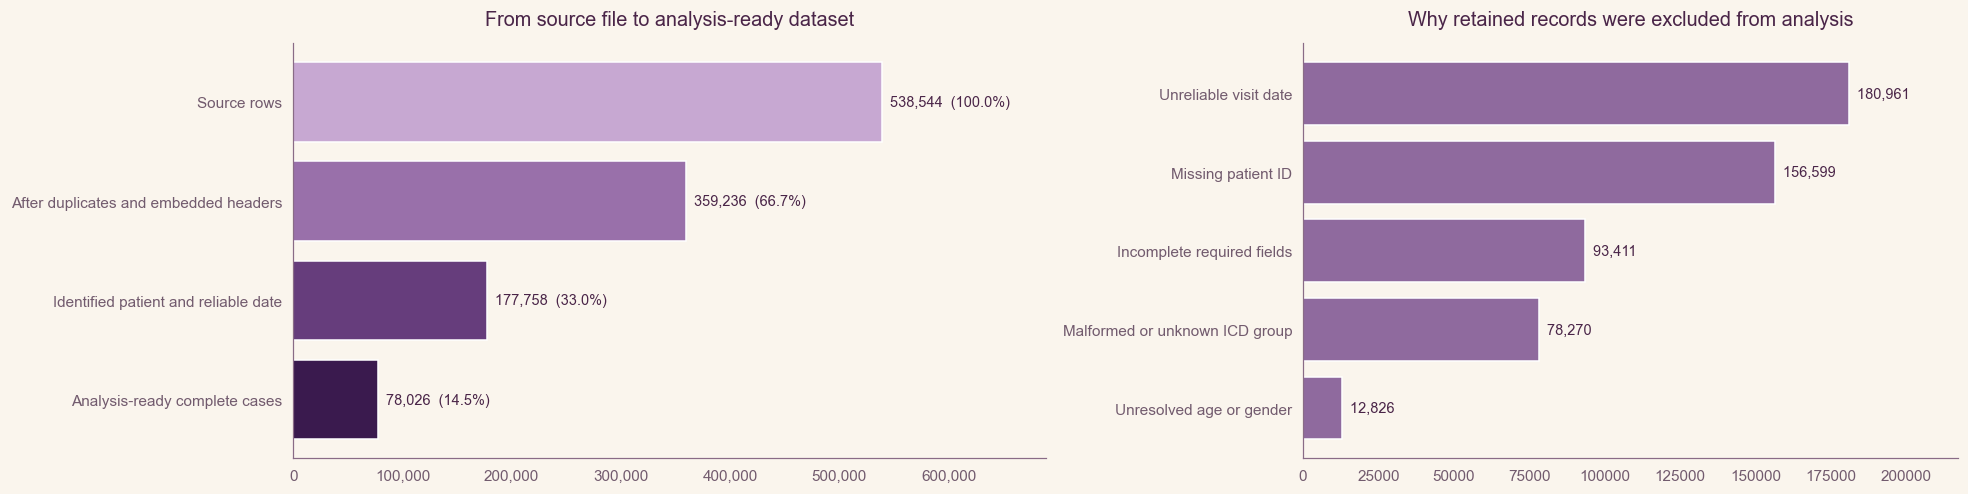

In [163]:
# Dataset at a glance: every number below is computed from the cleaned data.
src_rows, dup_rows, header_rows = len(raw), len(duplicate_rows), len(embedded_headers)
clean_rows, dated_rows, final_rows = len(df_all), len(analysis_candidate), len(df)
patient_days = len(df.drop_duplicates(['patient_id', 'visit_date']))
paid_claims = df.loc[df.total_claim.gt(0), 'total_claim']
cl_kpis([
    ('Claim records', f'{final_rows:,}', 'analysis-ready, complete cases'),
    ('Patients', f'{df.patient_id.nunique():,}', 'distinct identified patients'),
    ('Patient-days', f'{patient_days:,}', 'distinct observed visit days'),
    ('Period', f'{df.visit_date.min():%b %Y} – {df.visit_date.max():%b %Y}', 'first to last reliable visit date'),
    ('Total claimed', f'{df.total_claim.sum():,.0f}', 'source units (currency unverified)'),
    ('Median paid claim', f'{paid_claims.median():,.0f}', f'{paid_claims.size / final_rows:.0%} of records have a claim above zero'),
    ('Same-day visits', f'{df.length_of_stay.eq(0).sum() / max(df.length_of_stay.notna().sum(), 1):.0%}', 'of known stays last 0 days, so stay length carries little information'),
    ('Source rows kept', f'{final_rows / src_rows:.1%}', f'{final_rows:,} of {src_rows:,} source rows'),
])

stages = [('Source rows', src_rows),
          ('After duplicates and embedded headers', clean_rows),
          ('Identified patient and reliable date', dated_rows),
          ('Analysis-ready complete cases', final_rows)]
reasons = {'Missing patient ID': 'missing_patient_id', 'Unreliable visit date': 'unreliable_visit_date',
           'Incomplete required fields': 'incomplete_required_fields', 'Unresolved age or gender': 'unresolved_demographics',
           'Malformed or unknown ICD group': 'malformed_or_unknown_icd_category'}
reason_counts = pd.Series({k: int(exclusions[v].astype(bool).sum()) for k, v in reasons.items() if v in exclusions.columns}).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(18, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
colors = [CL_SEQ(x) for x in np.linspace(.35, .95, len(stages))]
ax[0].barh([s[0] for s in stages][::-1], [s[1] for s in stages][::-1], color=colors[::-1])
for y, (_, n) in enumerate(stages[::-1]):
    ax[0].text(n, y, f'  {n:,}  ({n / src_rows:.1%})', va='center', fontsize=9.5, color=CL['plum'])
ax[0].set_xlim(0, src_rows * 1.28); ax[0].set_title('From source file to analysis-ready dataset'); ax[0].grid(False)
ax[0].xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax[1].barh(reason_counts.index, reason_counts.values, color=CL['orchid'])
for y, n in enumerate(reason_counts.values):
    ax[1].text(n, y, f'  {n:,}', va='center', fontsize=9.5, color=CL['plum'])
ax[1].set_xlim(0, max(reason_counts.max(), 1) * 1.2); ax[1].set_title('Why retained records were excluded from analysis'); ax[1].grid(False)
plt.tight_layout(); plt.show()
cl_note('A record can have more than one exclusion reason, so the bars on the right can add up to more than the rows removed. Exclusions are documented in analysis_exclusions.csv.')

dropped = clean_rows - final_rows
if dropped > 0 and len(reason_counts):
    cl_takeaways('What the funnel tells us', [
        f'{strong(f"{dropped:,}")} cleaned records ({dropped / clean_rows:.1%}) were kept out of the analysis so that no date, diagnosis or amount had to be invented.',
        f'The most common exclusion reason is {strong(reason_counts.index[-1])} ({reason_counts.iloc[-1]:,} records).',
        f'Findings describe the {strong(f"{final_rows:,}")} usable records and should not be read as the whole population.'])


<div id="carelytics-representativeness" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / DATA QUALITY</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Representativeness and Data-Integrity Checks</h2></div>

Three checks that decide how far the findings can be trusted: (1) who the analysis kept versus excluded, (2) how the two analysis populations (claim records and observed patient-days) relate, and (3) whether the money and diagnosis fields behave consistently over the years.

,candidate_rows,kept_rows,kept_pct
year,,,
2015,9786,0,0.0
2016,21728,0,0.0
2017,26775,0,0.0
2018,17302,0,0.0
2019,18612,16513,88.7
2020,17504,14949,85.4
2021,15016,2770,18.4
2022,14263,9975,69.9
2023,6705,6267,93.5


kept,excluded,kept
rows,99732.0,78026.0
female_pct,58.4,63.5
median_age,45.0,49.0
age_known_pct,99.8,100.0
diagnosis_known_pct,22.1,100.0
paid_claim_pct,100.0,100.0
median_paid_claim,14.1,19.4


,records_or_days,patients,first_date,last_date
"Analysis dataset (complete claim records): profile, cost, diagnoses, extended ML",78026,35808,2019-04-01,2025-08-31
"Observed patient-days (every reliably dated visit): returns, survival, return model",175015,70515,2015-05-05,2025-08-31


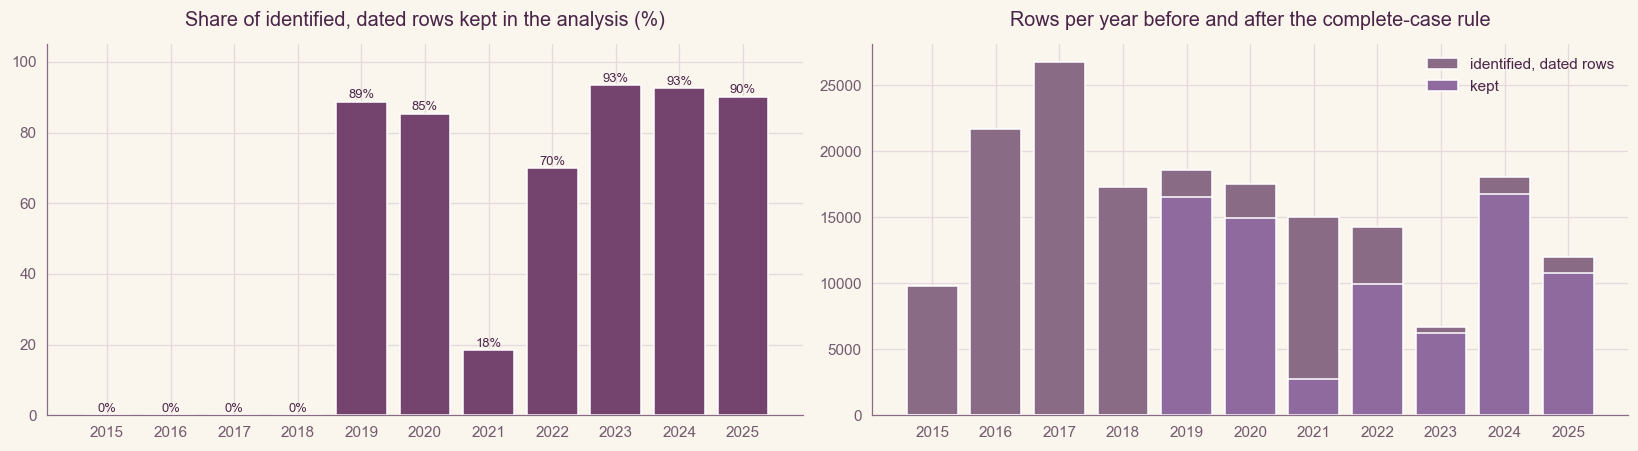

In [164]:
# 1) Who was kept? Compare retained rows with identified, reliably dated rows that were excluded.
cand = analysis_candidate.copy()
cand['kept'] = cand.source_row_id.isin(set(df.source_row_id))
cand['year'] = cand.visit_date.dt.year
kept_by_year = cand.groupby('year').agg(candidate_rows=('kept', 'size'), kept_rows=('kept', 'sum'))
kept_by_year['kept_pct'] = kept_by_year.kept_rows / kept_by_year.candidate_rows * 100

def _profile(g):
    paid_ = g.total_claim.gt(0)
    return pd.Series({'rows': len(g), 'female_pct': g.gender.eq('F').mean() * 100, 'median_age': g.age.median(),
                      'age_known_pct': g.age.notna().mean() * 100,
                      'diagnosis_known_pct': (~g.disease_category.isin(['UNKNOWN', 'UNMAPPED'])).mean() * 100,
                      'paid_claim_pct': paid_.mean() * 100, 'median_paid_claim': g.loc[paid_, 'total_claim'].median()})
profile_kept = cand.groupby('kept').apply(_profile, include_groups=False).T
profile_kept = profile_kept.rename(columns={True: 'kept', False: 'excluded'})
display(kept_by_year.round(1)); display(profile_kept.round(1))

# 2) Two populations are used in this notebook; show how they relate.
population = pd.DataFrame({
    'records_or_days': [len(df), len(episodes)],
    'patients': [df.patient_id.nunique(), episodes.patient_id.nunique()],
    'first_date': [df.visit_date.min().date(), episodes.visit_date.min().date()],
    'last_date': [df.visit_date.max().date(), episodes.visit_date.max().date()]},
    index=['Analysis dataset (complete claim records): profile, cost, diagnoses, extended ML',
           'Observed patient-days (every reliably dated visit): returns, survival, return model'])
display(population)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].bar(kept_by_year.index.astype(str), kept_by_year.kept_pct, color=CL['mauve'])
ax[0].set_title('Share of identified, dated rows kept in the analysis (%)'); ax[0].set_ylim(0, 105)
for x_, v_ in enumerate(kept_by_year.kept_pct): ax[0].text(x_, v_ + 1, f'{v_:.0f}%', ha='center', fontsize=8.5)
ax[1].bar(kept_by_year.index.astype(str), kept_by_year.candidate_rows, color=CL['dusk'], label='identified, dated rows')
ax[1].bar(kept_by_year.index.astype(str), kept_by_year.kept_rows, color=CL['orchid'], label='kept')
ax[1].set_title('Rows per year before and after the complete-case rule'); ax[1].legend()
plt.tight_layout(); plt.show()

kept_pct_all = cand.kept.mean() * 100
lo_y, hi_y = kept_by_year.kept_pct.idxmin(), kept_by_year.kept_pct.idxmax()
items = [f'{strong(f"{kept_pct_all:.1f}%")} of identified, reliably dated rows are in the analysis dataset; the share ranges from {strong(f"{kept_by_year.kept_pct.min():.0f}%")} ({lo_y}) to {strong(f"{kept_by_year.kept_pct.max():.0f}%")} ({hi_y}).']
if {'kept', 'excluded'} <= set(profile_kept.columns):
    pk, pe = profile_kept['kept'], profile_kept['excluded']
    items.append(f'Kept rows have a median age of {pk.median_age:.0f} versus {pe.median_age:.0f} for excluded rows, and {pk.diagnosis_known_pct:.0f}% versus {pe.diagnosis_known_pct:.0f}% with a known diagnosis chapter.')
items.append(f'The descriptive sections describe {strong(f"{df.patient_id.nunique():,}")} patients; the return, survival and return-model sections use {strong(f"{episodes.patient_id.nunique():,}")} patients because they need only a patient ID and a reliable date.')
cl_takeaways('Key takeaways: representativeness', items, caveat='Large differences between kept and excluded rows mean the descriptive findings should not be generalised to the whole source.')

,rows,reported_total_zero_pct,rebuilt_from_components_pct,final_total_zero_pct,mean_total_claim,unknown_diagnosis_pct,multi_chapter_pct
year,,,,,,,
2015,9786,0.0,0.0,0.0,18.1,100.0,0.0
2016,21728,0.0,0.0,0.0,35.8,100.0,0.0
2017,26775,0.0,0.0,0.0,21.2,100.0,0.0
2018,17302,0.0,0.0,0.0,19.9,100.0,0.0
2019,18612,100.0,100.0,0.0,20.2,0.0,0.0
2020,17504,100.0,100.0,0.0,19.5,0.0,0.0
2021,15016,89.5,89.5,0.0,19.1,0.2,3.7
2022,14263,82.6,82.6,0.0,23.0,1.0,27.1
2023,6705,37.2,37.2,0.0,24.7,3.3,31.1


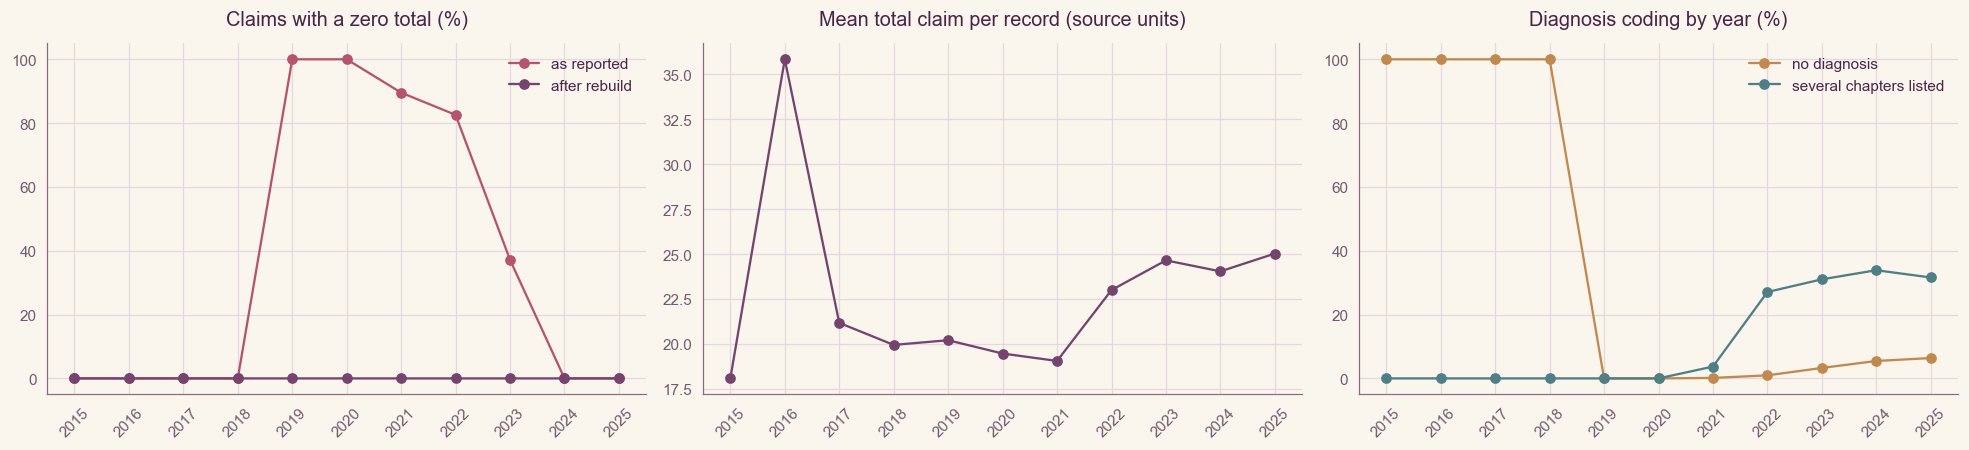

In [165]:
# 3) Integrity of total_claim and diagnosis coding over time.
x = df_all.loc[df_all.patient_id.notna() & df_all.date_reliable].copy()
x['year'] = x.visit_date.dt.year
orig_total = pd.to_numeric(x.total_claim_original.astype('string').str.replace(',', '', regex=False), errors='coerce')
x['reported_zero'] = orig_total.fillna(0).eq(0)
integrity = x.groupby('year').agg(rows=('total_claim', 'size'),
                                  reported_total_zero_pct=('reported_zero', lambda s: s.mean() * 100),
                                  rebuilt_from_components_pct=('total_claim_rebuilt', lambda s: s.mean() * 100),
                                  final_total_zero_pct=('total_claim', lambda s: s.eq(0).mean() * 100),
                                  mean_total_claim=('total_claim', 'mean'),
                                  unknown_diagnosis_pct=('disease_category', lambda s: s.eq('UNKNOWN').mean() * 100),
                                  multi_chapter_pct=('multi_chapter', lambda s: s.mean() * 100))
display(integrity.round(1))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].plot(integrity.index, integrity.reported_total_zero_pct, marker='o', color=CL['rose'], label='as reported')
ax[0].plot(integrity.index, integrity.final_total_zero_pct, marker='o', color=CL['mauve'], label='after rebuild')
ax[0].set_title('Claims with a zero total (%)'); ax[0].legend(); ax[0].set_xticks(integrity.index)
ax[1].plot(integrity.index, integrity.mean_total_claim, marker='o', color=CL['mauve']); ax[1].set_title('Mean total claim per record (source units)'); ax[1].set_xticks(integrity.index)
ax[2].plot(integrity.index, integrity.unknown_diagnosis_pct, marker='o', color=CL['amber'], label='no diagnosis')
ax[2].plot(integrity.index, integrity.multi_chapter_pct, marker='o', color=CL['teal'], label='several chapters listed')
ax[2].set_title('Diagnosis coding by year (%)'); ax[2].legend(); ax[2].set_xticks(integrity.index)
for a_ in ax: a_.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
worst = integrity.reported_total_zero_pct.idxmax()
cl_takeaways('Key takeaways: data integrity', [
    f'In {strong(worst)} the source reports a zero total for {strong(f"{integrity.reported_total_zero_pct.max():.0f}%")} of records; after rebuilding from components the zero share there is {strong(f"{integrity.final_total_zero_pct[worst]:.0f}%")}.',
    f'{strong(f"{int(x.total_claim_rebuilt.sum()):,}")} totals were rebuilt in this subset; a year-to-year step in the mean total after the rebuild would point to a real change in billing rules.',
    f'Claims listing several ICD chapters rise from {integrity.multi_chapter_pct.iloc[0]:.0f}% to {integrity.multi_chapter_pct.iloc[-1]:.0f}% over the period, which is a coding-practice change, so categories use the first listed code.'],
    caveat='Confirm with the data owner why totals were recorded as zero and whether total = sum of the five components.')

<div id="carelytics-section-33" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Patient Profile (Age and Gender)</h2></div>

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
plt.rcParams.update(CL_RC)   # keep the Carelytics chart theme

# 1) One row per patient (first recorded age and gender)
patients = (df.sort_values("visit_date")
              .groupby("patient_id")
              .agg(age=("age", "first"),
                   gender=("gender", "first"),
                   n_visits=("patient_id", "size"),
                   first_visit=("visit_date", "min"),
                   last_visit=("visit_date", "max"))
              .reset_index())
patients["age_group"] = pd.cut(patients["age"], bins=[0, 18, 35, 50, 65, 111], right=False,
                               labels=["0-17", "18-34", "35-49", "50-64", "65+"])

print("Unique patients:", len(patients))
print("Analysis claim records:", len(df))

# 2) Describe age (patient level)
print(patients["age"].describe())

# 3) Gender and age group counts (groupby / aggregate)
print(patients["gender"].value_counts())
print(patients["gender"].value_counts(normalize=True).round(3) * 100)
print(patients["age_group"].value_counts().sort_index())

Unique patients: 35808
Analysis claim records: 78026
count    35808.000000
mean        39.331043
std         22.848696
min          0.000000
25%         20.000000
50%         39.000000
75%         58.000000
max        110.000000
Name: age, dtype: float64
gender
F    21482
M    14326
Name: count, dtype: Int64
gender
F    60.0
M    40.0
Name: proportion, dtype: Float64
age_group
0-17     7915
18-34    8035
35-49    6924
50-64    7112
65+      5822
Name: count, dtype: int64


In [84]:
# 4) Aggregate by gender: patients, mean age, visits per patient
gender_summary = (patients.groupby("gender")
                  .agg(n_patients=("patient_id", "count"),
                       mean_age=("age", "mean"),
                       median_age=("age", "median"),
                       mean_visits=("n_visits", "mean"),
                       max_visits=("n_visits", "max")))
print(gender_summary.round(2))

        n_patients  mean_age  median_age  mean_visits  max_visits
gender                                                           
F            21482     42.30        43.0         2.31          34
M            14326     34.88        32.0         1.99          34


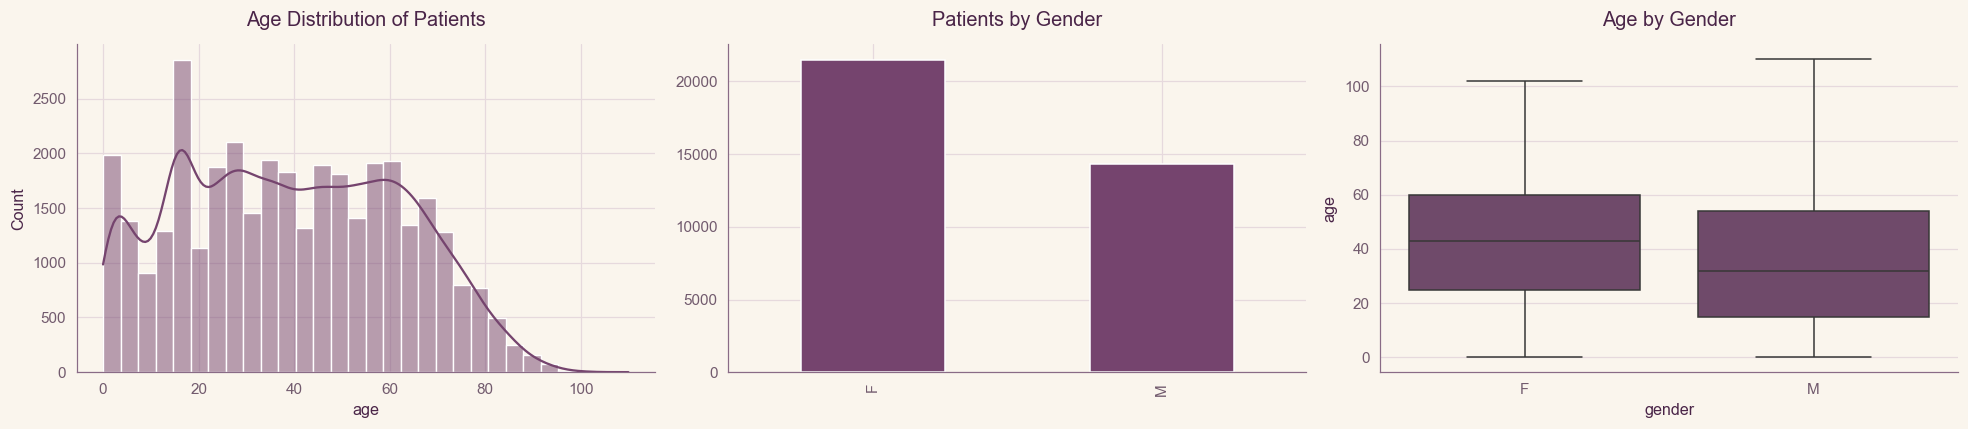

In [85]:
# 5) Plots
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(patients["age"].dropna(), bins=30, kde=True, ax=ax[0])
ax[0].set_title("Age Distribution of Patients")

patients["gender"].value_counts().plot(kind="bar", ax=ax[1], color=CL['mauve'])
ax[1].set_title("Patients by Gender")
ax[1].set_xlabel("")

sns.boxplot(data=patients, x="gender", y="age", ax=ax[2])
ax[2].set_title("Age by Gender")
plt.tight_layout()
plt.show()

In [86]:
# Plain-language reading of the patient profile above.
share_gender = patients.gender.value_counts(normalize=True)
age_med = patients.groupby('gender').age.median()
band = patients.age_group.value_counts(normalize=True)
female, male = share_gender.get('F', 0), share_gender.get('M', 0)
senior, child = band.get('65+', 0), band.get('0-17', 0)
single_share, heavy_share = (patients.n_visits == 1).mean(), (patients.n_visits >= 10).mean()
items = [
    f'The profile covers {strong(f"{len(patients):,}")} patients. Median age is {strong(f"{patients.age.median():.0f}")} years '
    f'(middle half: {patients.age.quantile(.25):.0f}–{patients.age.quantile(.75):.0f}).',
    f'{strong(f"{female:.1%}")} of patients are female and {strong(f"{male:.1%}")} are male.',
    f'Patients aged 65 and over make up {strong(f"{senior:.1%}")} of the group; children (0-17) make up {strong(f"{child:.1%}")}.',
    f'{strong(f"{single_share:.1%}")} of patients have a single claim record, while {strong(f"{heavy_share:.1%}")} have ten or more.']
if {'F', 'M'} <= set(age_med.index):
    items.insert(2, f'Median age is {age_med["F"]:.0f} for women and {age_med["M"]:.0f} for men.')
cl_takeaways('Key takeaways: patient profile', items, caveat='Counts are claim records per patient, not proven separate encounters. Age and gender come from the first usable record.')


<div id="carelytics-section-37" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Visit Trends Over Time</h2></div>

In [87]:
# Use visit-level data with valid dates only
d = df.dropna(subset=["visit_date"]).copy()
d["year"] = d["visit_date"].dt.year
d["month"] = d["visit_date"].dt.month
d["month_name"] = d["visit_date"].dt.month_name()

# 1) Visits per year + % change (upward / downward trend)
yearly = (d.groupby("year")
            .agg(visits=("patient_id", "size"),
                 unique_patients=("patient_id", "nunique"),
                 avg_claim=("total_claim", "mean"),
                 total_claim=("total_claim", "sum")))
yearly["visits_pct_change"] = (yearly["visits"].pct_change() * 100).round(1)
yearly["trend"] = np.where(yearly["visits_pct_change"] > 0, "Up",
                   np.where(yearly["visits_pct_change"] < 0, "Down", "-"))
print(yearly.round(1))
print("Busiest year:", yearly["visits"].idxmax(), "| Quietest year:", yearly["visits"].idxmin())

      visits  unique_patients  avg_claim  total_claim  visits_pct_change trend
year                                                                          
2019   16513             9060       20.1     331430.2                NaN     -
2020   14949             7742       19.4     290757.1               -9.5  Down
2021    2770             2345       18.1      50139.4              -81.5  Down
2022    9975             6625       24.6     245844.4              260.1    Up
2023    6267             4449       24.8     155321.4              -37.2  Down
2024   16751             9238       24.3     407185.4              167.3    Up
2025   10801             6332       25.4     274747.9              -35.5  Down
Busiest year: 2024 | Quietest year: 2021


In [88]:
# 2) Visits per calendar month (all years combined) -> the most month
month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
monthly = (d.groupby("month_name")["patient_id"].size()
             .reindex(month_order))
print(monthly)
print("Busiest month:", monthly.idxmax(), monthly.max())
print("Quietest month:", monthly.idxmin(), monthly.min())

month_name
January      5645
February     6817
March        3930
April        4843
May          8387
June         5868
July         7586
August       7090
September    5895
October      7850
November     7720
December     6395
Name: patient_id, dtype: int64
Busiest month: May 8387
Quietest month: March 3930


In [89]:
# 3) Busiest month inside each year
by_year_month = d.groupby(["year", "month"]).size().unstack(fill_value=0)
print(by_year_month.idxmax(axis=1).rename("busiest_month_number"))

year
2019    10
2020     1
2021     9
2022     5
2023    10
2024    10
2025     1
Name: busiest_month_number, dtype: int32


In [90]:
# 4) Monthly time series
ts = d.groupby(d["visit_date"].dt.to_period("M")).size()
ts.index = ts.index.to_timestamp()

In [91]:
print(ts.idxmax(), "-> Visits:", ts.max())

2022-05-01 00:00:00 -> Visits: 2861


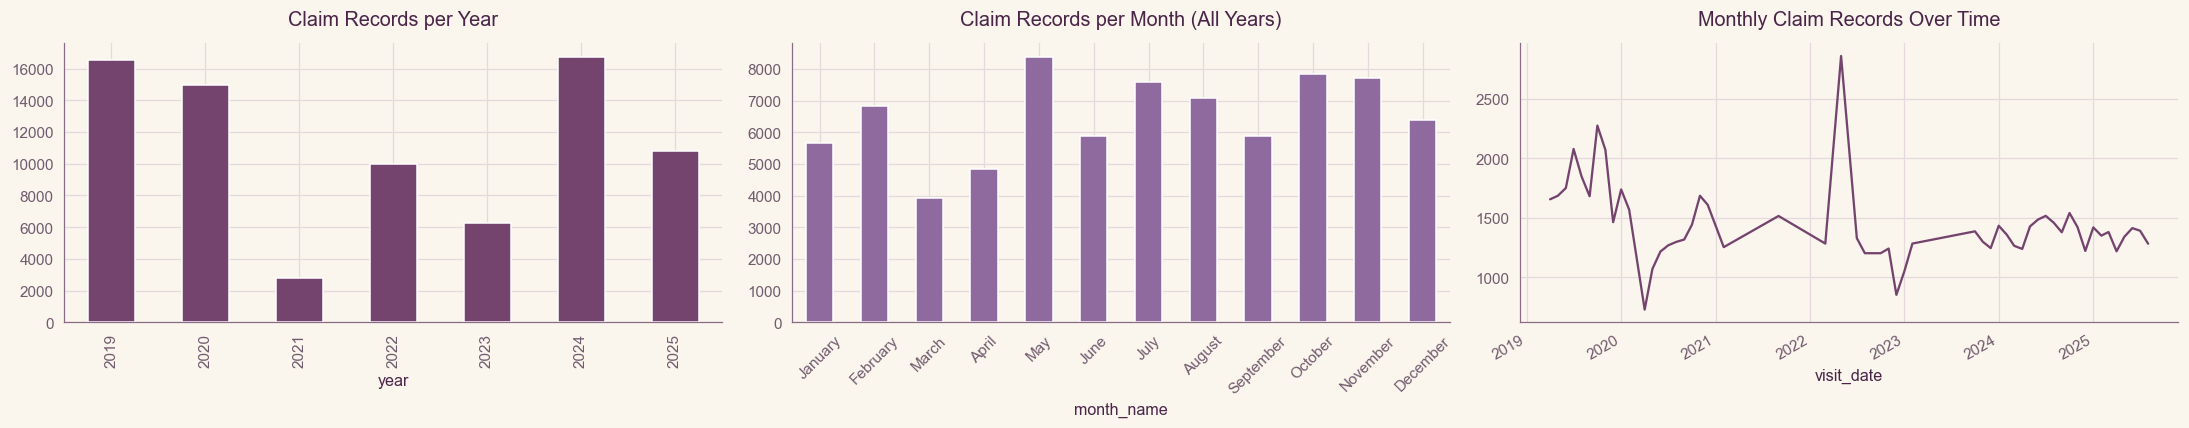

In [92]:
# 5) Plots
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
yearly["visits"].plot(kind="bar", ax=ax[0], color=CL['mauve'])
ax[0].set_title("Claim Records per Year")

monthly.plot(kind="bar", ax=ax[1], color=CL['orchid'])
ax[1].set_title("Claim Records per Month (All Years)")
ax[1].tick_params(axis="x", rotation=45)

ts.plot(ax=ax[2])
ax[2].set_title("Monthly Claim Records Over Time")
plt.tight_layout()
plt.show()

In [93]:
# Plain-language reading of the trend charts above.
y_hi, y_lo = yearly.visits.idxmax(), yearly.visits.idxmin()
chg = yearly.visits_pct_change.dropna()
m_hi, m_lo = monthly.idxmax(), monthly.idxmin()
last_year, first_year = d.visit_date.dt.year.max(), d.visit_date.dt.year.min()
last_months = d.loc[d.visit_date.dt.year == last_year, 'visit_date'].dt.month.nunique()
first_months = d.loc[d.visit_date.dt.year == first_year, 'visit_date'].dt.month.nunique()
items = [f'Records run from {strong(f"{d.visit_date.min():%b %Y}")} to {strong(f"{d.visit_date.max():%b %Y}")}. '
         f'The busiest year is {strong(y_hi)} ({yearly.visits[y_hi]:,} records) and the quietest is {strong(y_lo)} ({yearly.visits[y_lo]:,}).']
if len(chg):
    big = chg.abs().idxmax()
    items.append(f'The largest year-to-year move is {strong(f"{chg[big]:+.1f}%")} in {strong(big)}.')
items.append(f'Across all years combined, {strong(m_hi)} has the most records and {strong(m_lo)} the fewest '
             f'({monthly.max() / max(monthly.min(), 1):.1f}× difference).')
cl_takeaways('Key takeaways: visit trends', items,
             caveat=f'The first year ({first_year}) covers {first_months} months and the last year ({last_year}) covers {last_months} months, so edge years can look lower only because coverage is partial. '
                    'Source dates may be billing dates, and yearly changes can reflect source coverage rather than demand.')


<div id="carelytics-seasonality" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Seasonality and Weekday Patterns</h2></div>

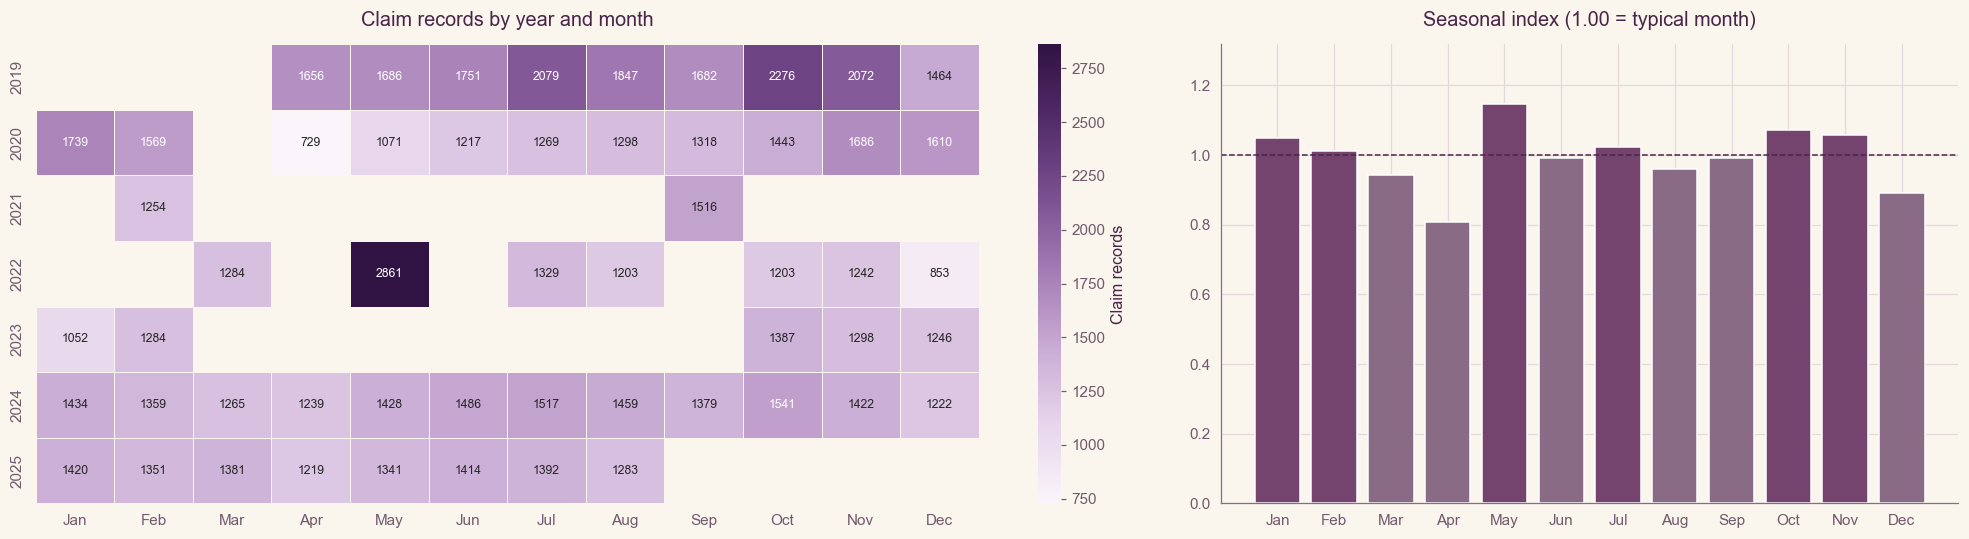

In [94]:
# Seasonality: year × month heatmap and a seasonal index (1.00 = a typical month of that year).
d = df.dropna(subset=['visit_date']).copy()
d['year'], d['month'], d['weekday'] = d.visit_date.dt.year, d.visit_date.dt.month, d.visit_date.dt.dayofweek
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
heat = d.groupby(['year', 'month']).size().unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0)
shown = heat.replace(0, np.nan)                       # empty cells = no records, not "zero demand"
season_index = shown.div(shown.mean(axis=1), axis=0).mean(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [1.6, 1]})
sns.heatmap(shown, cmap=CL_SEQ, annot=True, fmt='.0f', annot_kws={'size': 8}, linewidths=.6, linecolor=CL['paper'],
            cbar_kws={'label': 'Claim records'}, ax=ax[0])
ax[0].set_xticklabels(MONTHS, rotation=0); ax[0].set_xlabel(''); ax[0].set_ylabel('')
ax[0].set_title('Claim records by year and month'); ax[0].grid(False)
bar_colors = [CL['mauve'] if v >= 1 else CL['dusk'] for v in season_index.fillna(1)]
ax[1].bar(MONTHS, season_index.values, color=bar_colors)
ax[1].axhline(1, color=CL['plum'], lw=1, ls='--')
ax[1].set_ylim(0, max(1.3, np.nanmax(season_index.values) * 1.15)); ax[1].set_title('Seasonal index (1.00 = typical month)')
plt.tight_layout(); plt.show()
cl_note('Blank heatmap cells mean no records exist for that month. The index divides each month by the average month of the same year, then averages across years, so partial years do not distort it.')


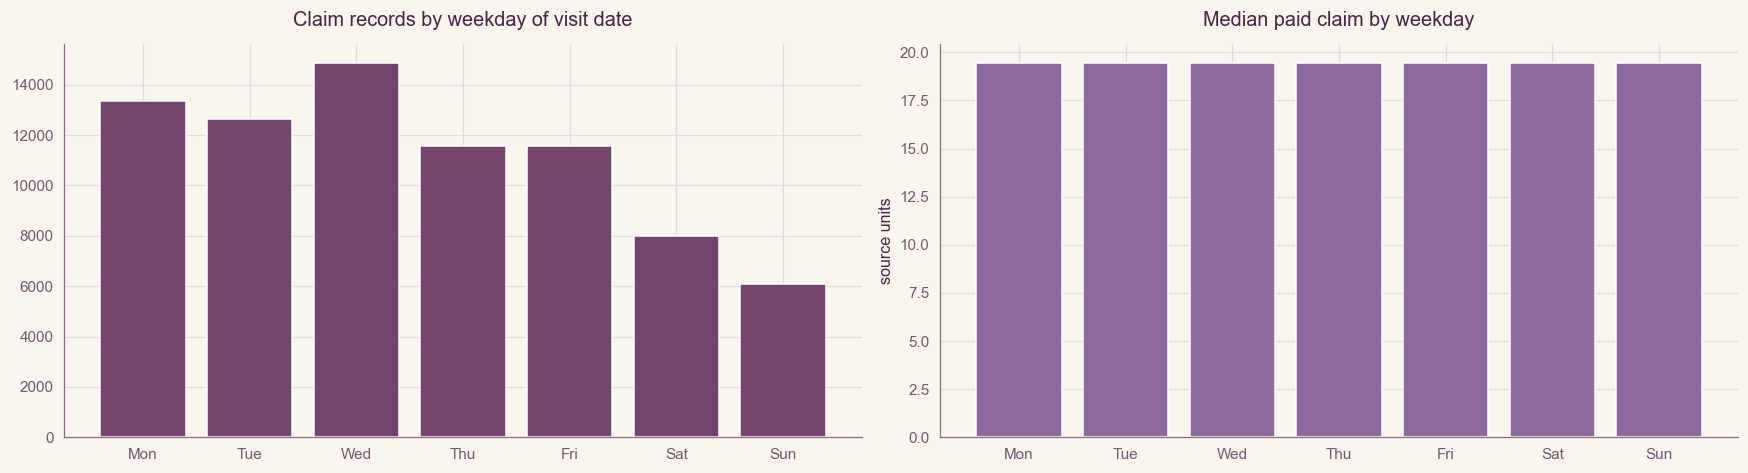

In [95]:
# Weekday profile and a short reading of the seasonal pattern.
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
wk = d.groupby('weekday').size().reindex(range(7), fill_value=0)
paid_d = d[d.total_claim.gt(0)]
wk_median = paid_d.groupby('weekday').total_claim.median().reindex(range(7))
fig, ax = plt.subplots(1, 2, figsize=(16, 4.4))
ax[0].bar(DAYS, wk.values, color=CL['mauve']); ax[0].set_title('Claim records by weekday of visit date')
ax[1].bar(DAYS, wk_median.values, color=CL['orchid']); ax[1].set_title('Median paid claim by weekday')
ax[1].set_ylabel('source units')
plt.tight_layout(); plt.show()

peak, trough = int(season_index.idxmax()), int(season_index.idxmin())
weekend = wk.loc[[5, 6]].sum() / max(wk.sum(), 1)
cl_takeaways('Key takeaways: seasonality and weekdays', [
    f'The seasonal index peaks in {strong(MONTHS[peak - 1])} ({season_index[peak]:.2f}) and is lowest in {strong(MONTHS[trough - 1])} ({season_index[trough]:.2f}).',
    f'{strong(DAYS[int(wk.idxmax())])} is the busiest weekday and {strong(DAYS[int(wk.idxmin())])} the quietest.',
    f'{strong(f"{weekend:.1%}")} of records carry a Saturday or Sunday visit date.'],
    caveat='If visit dates are billing or posting dates, weekday and month patterns describe administrative rhythm as much as clinical demand. Confirm the date definition with the data owner.')


<div id="carelytics-section-44" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Diagnoses Analysis</h2></div>

In [96]:
d = df.dropna(subset=["visit_date"]).copy()
d["year"] = d["visit_date"].dt.year

# 1) How much of the data has a known diagnosis category?
print("Share of UNKNOWN disease_category: "
      f"{(d['disease_category'] == 'UNKNOWN').mean():.1%}")

known = d[d["disease_category"] != "UNKNOWN"].copy()
print("Rows with known diagnosis:", len(known))

Share of UNKNOWN disease_category: 0.0%
Rows with known diagnosis: 78026


In [97]:
# 2) Top 10 diseases by number of visits
top_dis = known["disease_category"].value_counts().head(10)
print(top_dis)
print((top_dis / len(known) * 100).round(1))

disease_category
CIRCULATORY             20295
MUSCULOSKELETAL         11131
INFECTIOUS_PARASITIC    10653
RESPIRATORY              8299
ENDOCRINE_METABOLIC      6094
DIGESTIVE                5248
GENITOURINARY            4786
BLOOD_IMMUNE             2250
NERVOUS_SYSTEM           2028
SKIN                     1664
Name: count, dtype: int64
disease_category
CIRCULATORY             26.0
MUSCULOSKELETAL         14.3
INFECTIOUS_PARASITIC    13.7
RESPIRATORY             10.6
ENDOCRINE_METABOLIC      7.8
DIGESTIVE                6.7
GENITOURINARY            6.1
BLOOD_IMMUNE             2.9
NERVOUS_SYSTEM           2.6
SKIN                     2.1
Name: count, dtype: float64


In [98]:
# 3) groupby + aggregate per disease category
disease_summary = (known.groupby("disease_category")
                   .agg(visits=("patient_id", "size"),
                        unique_patients=("patient_id", "nunique"),
                        mean_age=("age", "mean"),
                        mean_claim=("total_claim", "mean"),
                        median_claim=("total_claim", "median"),
                        mean_los=("length_of_stay", "mean"))
                   .sort_values("visits", ascending=False))
disease_summary["visits_per_patient"] = (disease_summary["visits"]
                                         / disease_summary["unique_patients"])
print(disease_summary.head(10).round(2))

                      visits  unique_patients  mean_age  mean_claim  \
disease_category                                                      
CIRCULATORY            20295             9208     61.21       26.73   
MUSCULOSKELETAL        11131             8617     47.04       19.51   
INFECTIOUS_PARASITIC   10653             8887     32.92       19.87   
RESPIRATORY             8299             6725     28.47       21.22   
ENDOCRINE_METABOLIC     6094             3466     60.01       34.16   
DIGESTIVE               5248             4250     38.11        17.9   
GENITOURINARY           4786             3885     41.07       18.24   
BLOOD_IMMUNE            2250             2015     39.73       21.71   
NERVOUS_SYSTEM          2028             1810     48.01       19.07   
SKIN                    1664             1439     35.35       18.92   

                      median_claim  mean_los  visits_per_patient  
disease_category                                                  
CIRCULATORY  

In [99]:
# 4) Extremes: highest and lowest visit counts, most expensive disease (median)
print("Most common:", disease_summary["visits"].idxmax())
print("Least common:", disease_summary["visits"].idxmin())
print("Highest median claim:", disease_summary["median_claim"].idxmax())

Most common: CIRCULATORY
Least common: PERINATAL
Highest median claim: ENDOCRINE_METABOLIC


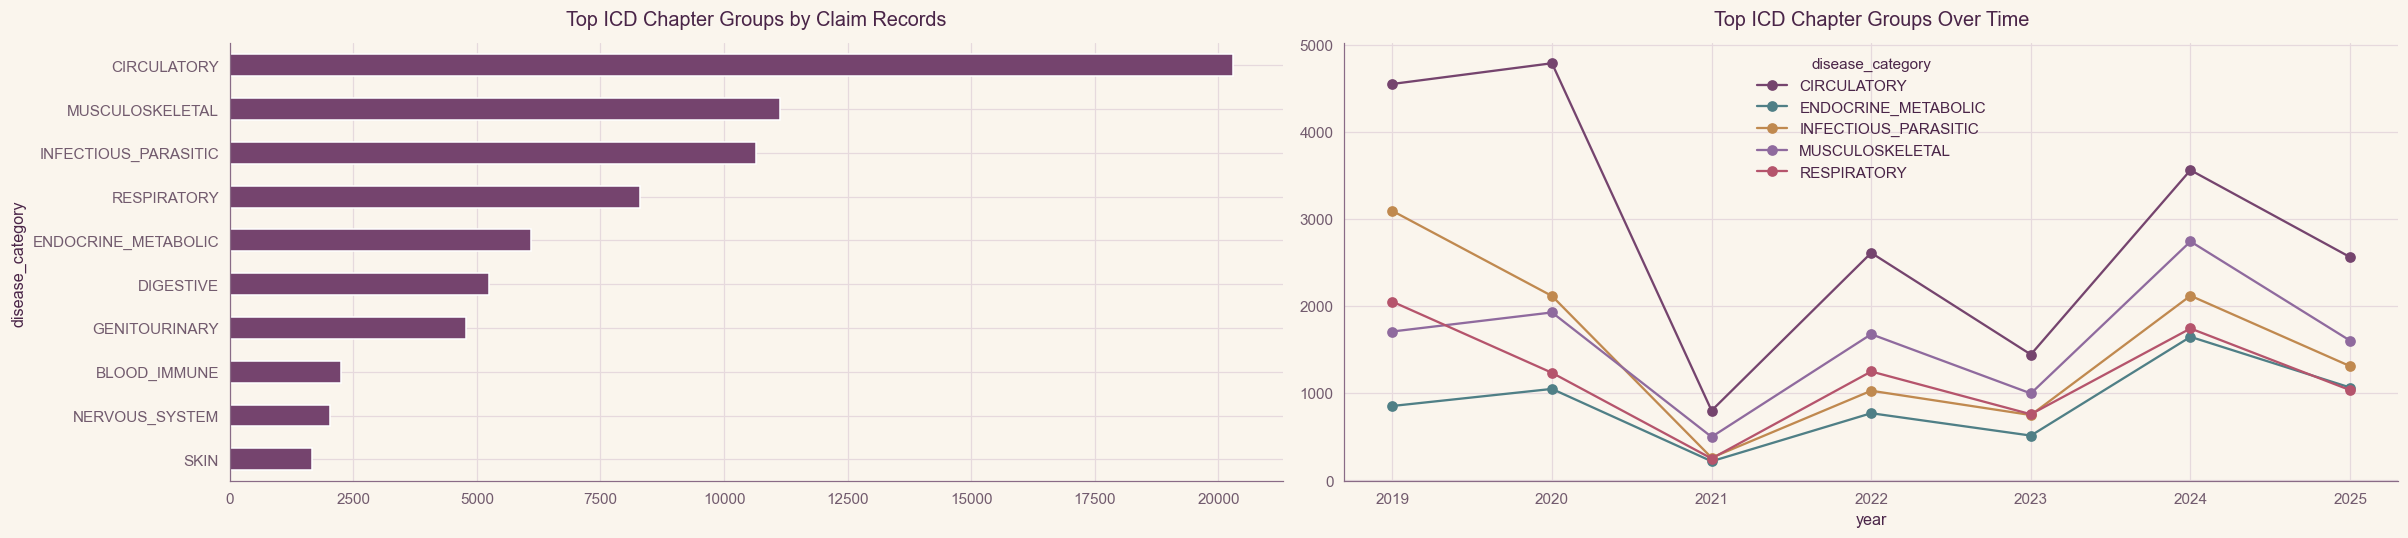

In [100]:
top_five = known["disease_category"].value_counts().head(5).index
trend = known.loc[known["disease_category"].isin(top_five)].groupby(["year", "disease_category"]).size().unstack(fill_value=0)
# 5) Plots
fig, ax = plt.subplots(1, 2, figsize=(22, 5))
top_dis.sort_values().plot(kind="barh", ax=ax[0], color=CL['mauve'])
ax[0].set_title("Top ICD Chapter Groups by Claim Records")

trend.plot(ax=ax[1], marker="o")
ax[1].set_title("Top ICD Chapter Groups Over Time")
plt.tight_layout()
plt.show()

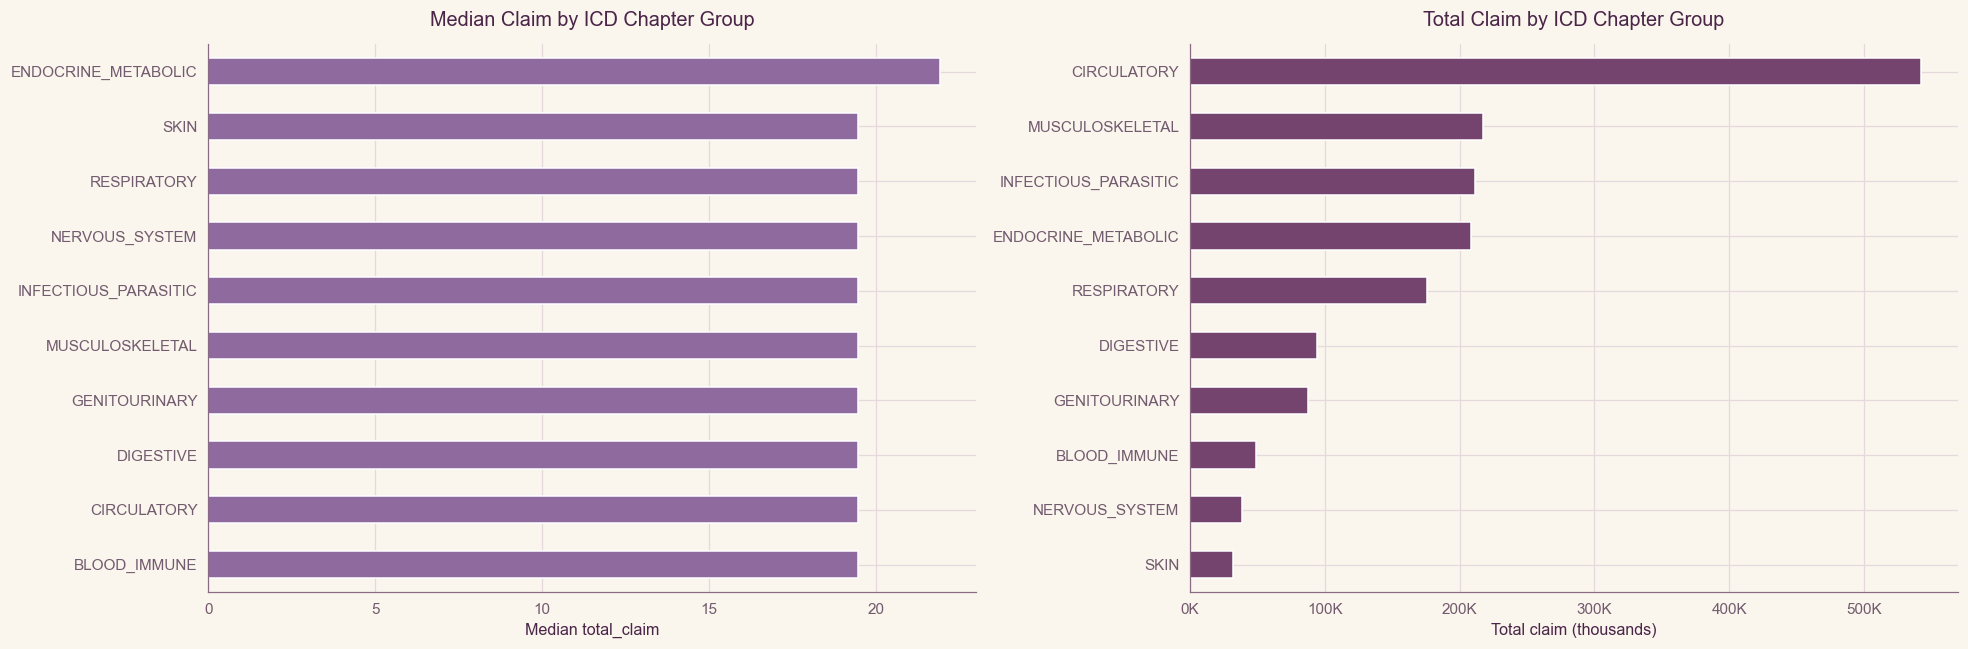

In [101]:
from matplotlib.ticker import FuncFormatter

paid = df[(df["total_claim"] > 0) & (df["disease_category"] != "UNKNOWN")]
top10 = paid["disease_category"].value_counts().head(10).index
g = paid[paid["disease_category"].isin(top10)].groupby("disease_category")["total_claim"]

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

g.median().sort_values().plot(kind="barh", color=CL['orchid'], ax=ax[0])
ax[0].set_title("Median Claim by ICD Chapter Group")
ax[0].set_xlabel("Median total_claim")
ax[0].set_ylabel("")

g.sum().sort_values().plot(kind="barh", color=CL['mauve'], ax=ax[1])
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1000:,.0f}K"))
ax[1].set_title("Total Claim by ICD Chapter Group")
ax[1].set_xlabel("Total claim (thousands)")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

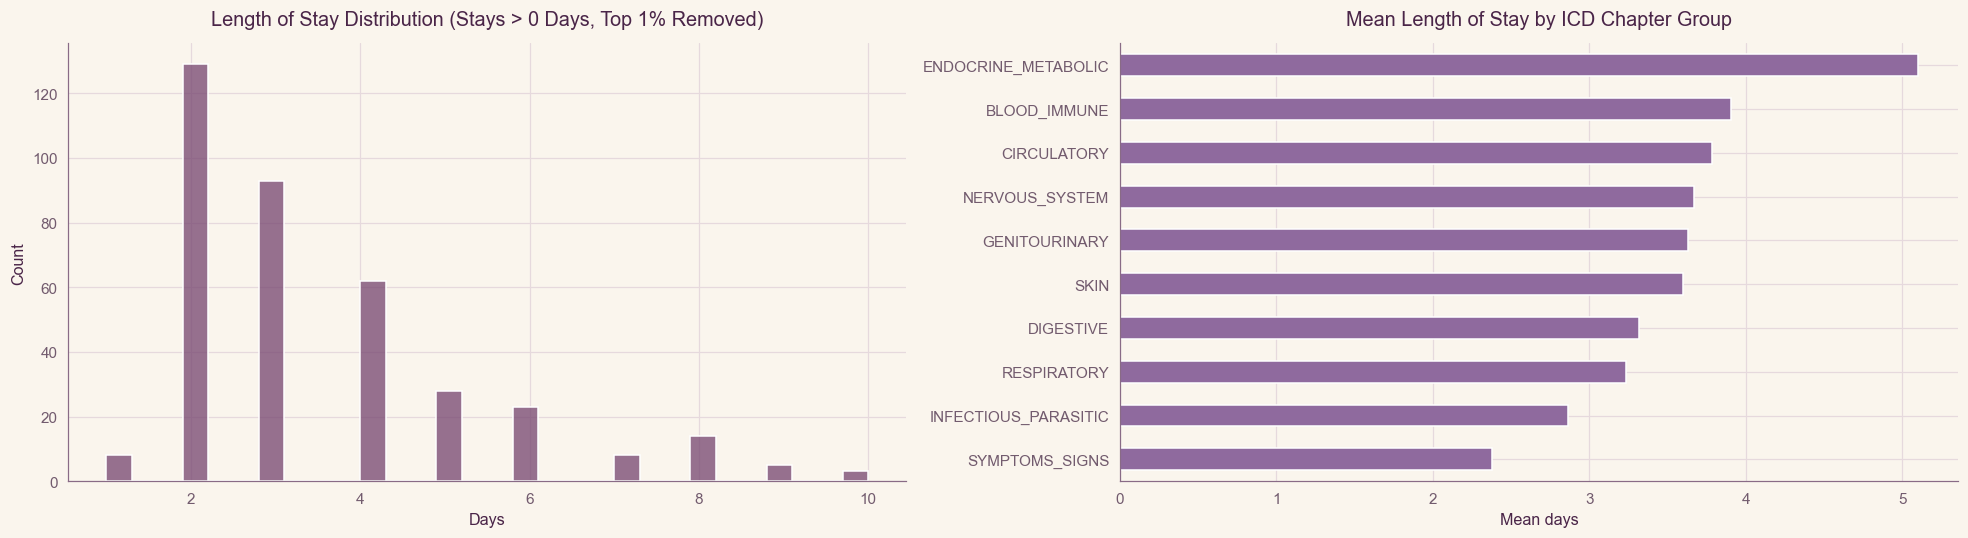

In [102]:
los = df.dropna(subset=["length_of_stay"]).copy()
stay = los[los["length_of_stay"] > 0]
if len(stay) < 30:
    cl_note(f'Stay length is zero days for almost every record ({len(stay)} stays above zero), so stay-length charts are skipped. Confirm the discharge-date definition with the data owner.')
else:
    top = stay["disease_category"].value_counts().head(10).index

    fig, ax = plt.subplots(1, 2, figsize=(18, 5))

    sns.histplot(stay[stay["length_of_stay"] <= stay["length_of_stay"].quantile(0.99)]["length_of_stay"],
                 bins=30, ax=ax[0])
    ax[0].set_title("Length of Stay Distribution (Stays > 0 Days, Top 1% Removed)")
    ax[0].set_xlabel("Days")

    stay[stay["disease_category"].isin(top)].groupby("disease_category")["length_of_stay"] \
        .mean().sort_values().plot(kind="barh", color=CL['orchid'], ax=ax[1])
    ax[1].set_title("Mean Length of Stay by ICD Chapter Group")
    ax[1].set_xlabel("Mean days")
    ax[1].set_ylabel("")

    plt.tight_layout()
    plt.show()


,eligible_patient_days,observed_returns,return_pct
revisit_30,122256,27455,22.456976
revisit_90,121057,40334,33.318189
revisit_180,119072,49091,41.227997


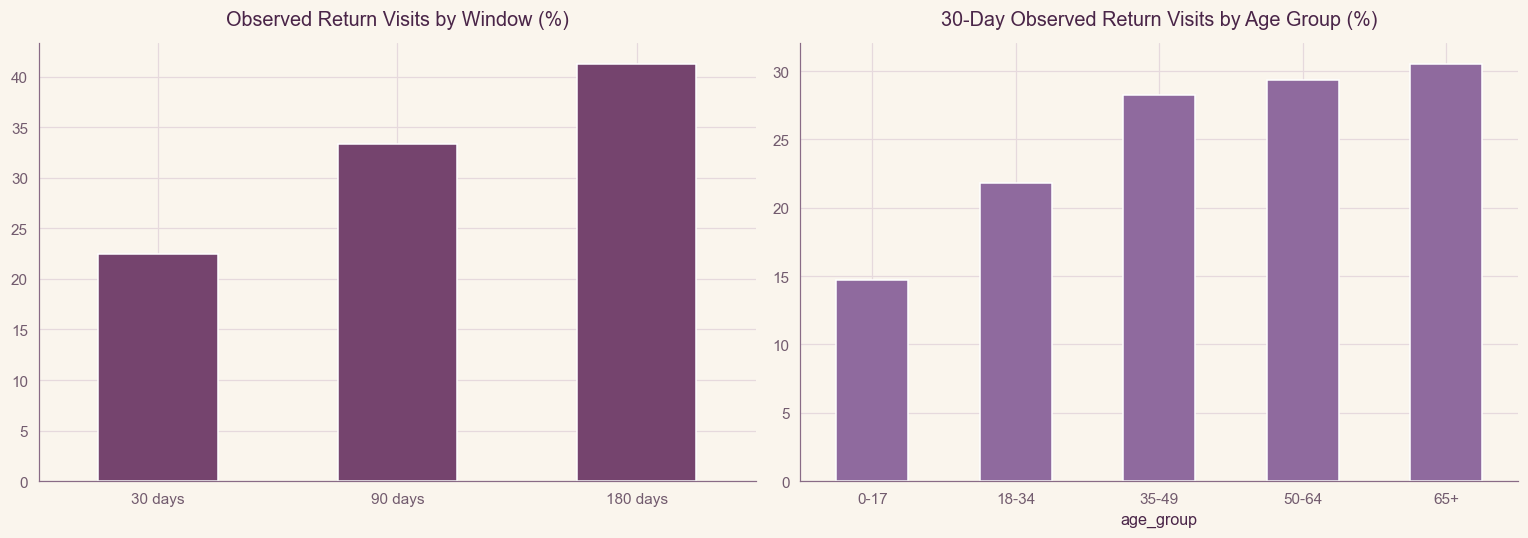

In [103]:
# One record per distinct observed patient-day; exclude unknown outcomes.
episode_ages = df.sort_values('source_row_id').drop_duplicates(['patient_id','visit_date'])[['patient_id','visit_date','age','age_imputed','age_conflict']]
r = episodes.merge(episode_ages,on=['patient_id','visit_date'],how='left',validate='one_to_one')
r['age_group']=pd.cut(r.age,bins=[0,18,35,50,65,111],right=False,labels=['0-17','18-34','35-49','50-64','65+'])
cols=['revisit_30','revisit_90','revisit_180']
rates=r[cols].mean().mul(100)
display(pd.DataFrame({'eligible_patient_days':r[cols].count(),'observed_returns':r[cols].sum(),'return_pct':rates}))
fig,ax=plt.subplots(1,2,figsize=(14,5))
rates.astype(float).plot(kind='bar',color='#75446e',ax=ax[0])
ax[0].set_title('Observed Return Visits by Window (%)')
ax[0].set_xticklabels(['30 days','90 days','180 days'],rotation=0)
age_rate=r.loc[~r.age_imputed.fillna(False) & ~r.age_conflict.fillna(False)].groupby('age_group',observed=True).revisit_30.mean().mul(100)
age_rate.astype(float).plot(kind='bar',color='#8f6a9e',ax=ax[1])
ax[1].set_title('30-Day Observed Return Visits by Age Group (%)')
ax[1].tick_params(axis='x',rotation=0)
plt.tight_layout();plt.show()


In [104]:
# Plain-language reading of the diagnosis and return charts above.
ds = disease_summary
rt = rates.astype(float)
share_top = top_dis.iloc[0] / len(known)
share_top3 = top_dis.head(3).sum() / len(known)
items = [
    f'{strong(nice(top_dis.index[0]))} is the most frequent ICD chapter group ({share_top:.1%} of records); the top three groups together cover {strong(f"{share_top3:.1%}")}.',
    f'The highest median claim belongs to {strong(nice(ds.median_claim.idxmax()))} ({ds.median_claim.max():,.0f}), the longest mean stay to {strong(nice(ds.mean_los.idxmax()))} ({ds.mean_los.max():.1f} days).',
    f'Observed later-visit rates are {strong(f"{rt.iloc[0]:.1f}%")} within 30 days, {strong(f"{rt.iloc[1]:.1f}%")} within 90 days and {strong(f"{rt.iloc[2]:.1f}%")} within 180 days.']
if ds.median_claim.idxmax() != ds.visits.idxmax():
    items.insert(2, 'The most common group is not the most expensive one, so volume and cost per record need to be read separately.')
cl_takeaways('Key takeaways: diagnoses and later visits', items,
             caveat=f'Groups are ICD chapters of the first listed code, derived from code syntax and not clinically validated; {df.multi_chapter.mean():.0%} of records list codes from more than one chapter. Later-visit rates mean another observed visit day, not inpatient readmission.')


<div id="carelytics-cost" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Cost and Spending Analysis</h2></div>

,component,total,share_pct,mean_per_record,records_above_zero_pct
4,Service,1320866.5,75.2,16.9,100.0
0,Drugs,434534.0,24.8,5.6,47.9
1,Investigation,0.0,0.0,0.0,0.0
2,Outpatient,0.0,0.0,0.0,0.0
3,Inpatient,0.0,0.0,0.0,0.0


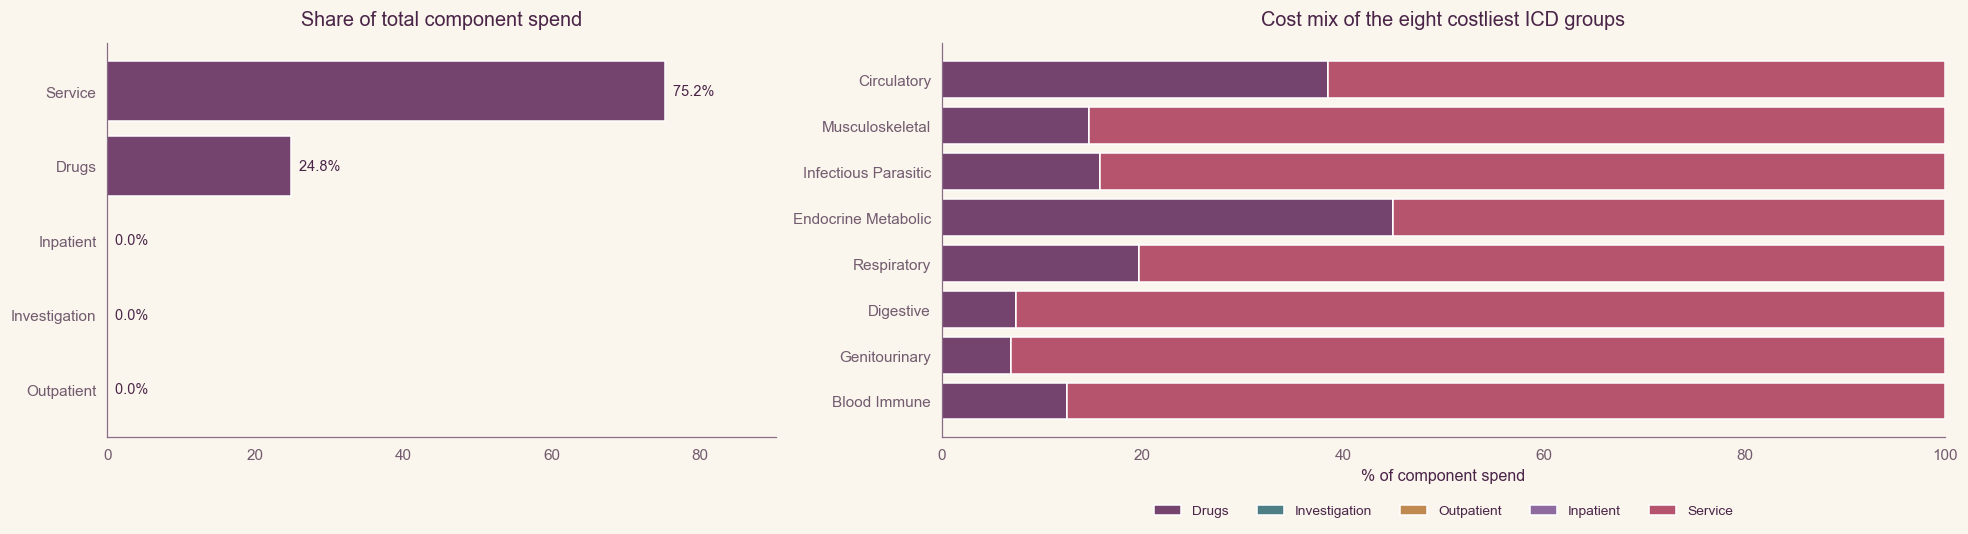

In [105]:
# Where the money goes: share of each cost component, overall and by diagnosis group.
comp_cols = [c for c in ['drugs_amount', 'investigation_amount', 'outpatient_amount', 'inpatient_amount', 'service_amount'] if c in df.columns]
label = {c: c.replace('_amount', '').replace('_', ' ').capitalize() for c in comp_cols}
tot = df[comp_cols].sum()
structure = pd.DataFrame({'component': [label[c] for c in comp_cols], 'total': tot.values,
                          'share_pct': (tot / tot.sum() * 100).values, 'mean_per_record': df[comp_cols].mean().values,
                          'records_above_zero_pct': (df[comp_cols].gt(0).mean() * 100).values}).sort_values('total', ascending=False)
display(structure.round(1))

top_ch = df.groupby('disease_category').total_claim.sum().nlargest(8).index
mix = df[df.disease_category.isin(top_ch)].groupby('disease_category')[comp_cols].sum()
mix = mix.div(mix.sum(axis=1), axis=0).mul(100).loc[top_ch[::-1]]
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.5]})
order = structure.sort_values('share_pct')
ax[0].barh(order.component, order.share_pct, color=CL['mauve'])
for y, v in enumerate(order.share_pct):
    ax[0].text(v, y, f'  {v:.1f}%', va='center', fontsize=9.5, color=CL['plum'])
ax[0].set_xlim(0, max(order.share_pct.max() * 1.2, 1)); ax[0].set_title('Share of total component spend'); ax[0].grid(False)
left = np.zeros(len(mix))
for i, c in enumerate(comp_cols):
    ax[1].barh([nice(x) for x in mix.index], mix[c].values, left=left, color=CL_CYCLE[i % len(CL_CYCLE)], label=label[c])
    left += mix[c].values
ax[1].set_xlim(0, 100); ax[1].set_xlabel('% of component spend'); ax[1].set_title('Cost mix of the eight costliest ICD groups')
ax[1].legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, -.14), fontsize=9); ax[1].grid(False)
plt.tight_layout(); plt.show()
cl_note('Component shares use the sum of the five component columns. The source does not confirm that components add up to total_claim, so this is a description of structure, not an accounting reconciliation.')


,top_patients_pct,patients,share_of_total_claim_pct
0,1,359,10.7
1,5,1791,30.2
2,10,3581,43.3
3,20,7162,59.0
4,50,17904,82.5


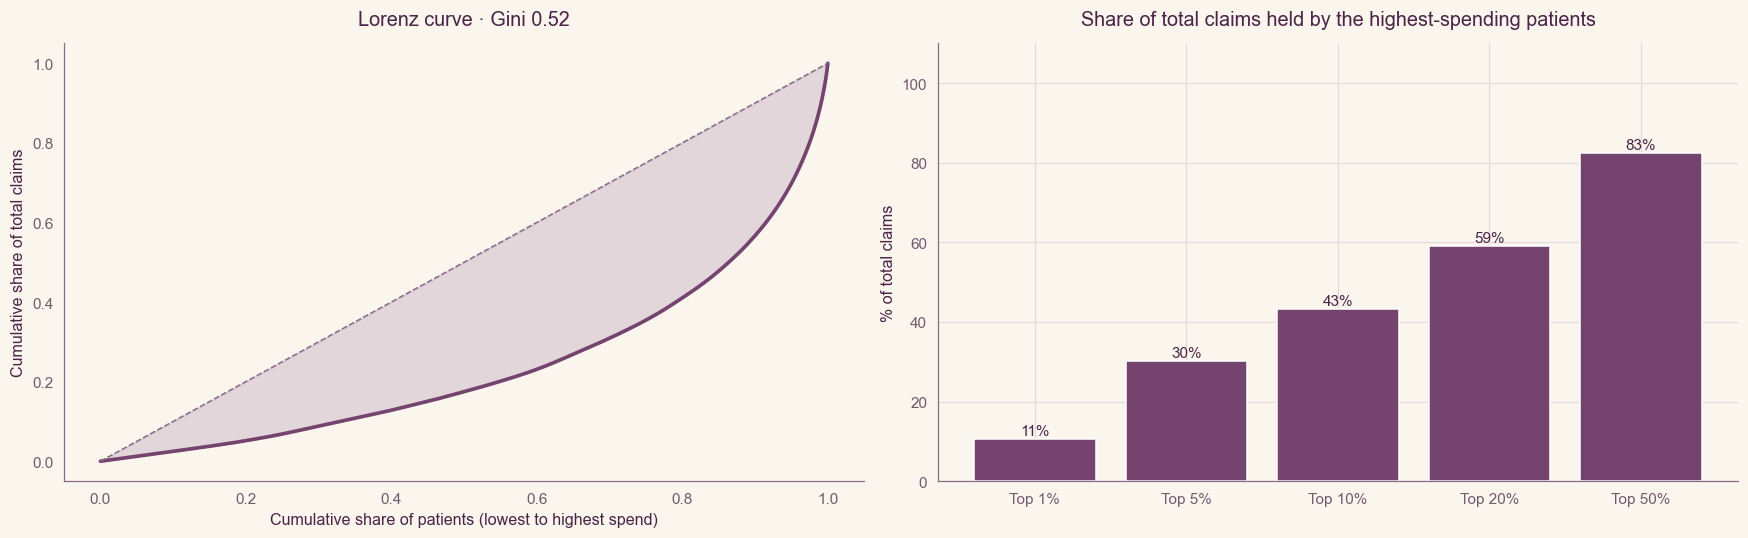

In [106]:
# How concentrated is spending? Patient-level Lorenz curve, Gini coefficient and top-share table.
per_patient = df.groupby('patient_id').total_claim.sum()
per_patient = per_patient[per_patient > 0].sort_values()
n_pat, total_spend = len(per_patient), per_patient.sum()
values = per_patient.to_numpy(dtype=float)
gini = (2 * np.sum(np.arange(1, n_pat + 1) * values) / (n_pat * total_spend)) - (n_pat + 1) / n_pat
lorenz = np.concatenate([[0], np.cumsum(values) / total_spend])
population = np.linspace(0, 1, n_pat + 1)
desc = per_patient.sort_values(ascending=False)
top_share = pd.DataFrame({'top_patients_pct': [1, 5, 10, 20, 50]})
top_share['patients'] = [max(1, int(np.ceil(n_pat * p / 100))) for p in top_share.top_patients_pct]
top_share['share_of_total_claim_pct'] = [desc.head(k).sum() / total_spend * 100 for k in top_share.patients]
display(top_share.round(1))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(population, lorenz, color=CL['mauve'], lw=2.4)
ax[0].plot([0, 1], [0, 1], ls='--', color=CL['dusk'], lw=1)
ax[0].fill_between(population, lorenz, population, color=CL['orchid'], alpha=.22)
ax[0].set(xlabel='Cumulative share of patients (lowest to highest spend)', ylabel='Cumulative share of total claims', title=f'Lorenz curve · Gini {gini:.2f}')
ax[0].grid(False)
ax[1].bar([f'Top {p}%' for p in top_share.top_patients_pct], top_share.share_of_total_claim_pct, color=CL['mauve'])
for x, v in enumerate(top_share.share_of_total_claim_pct):
    ax[1].text(x, v + 1, f'{v:.0f}%', ha='center', fontsize=10, color=CL['plum'])
ax[1].set_ylim(0, 110); ax[1].set_ylabel('% of total claims'); ax[1].set_title('Share of total claims held by the highest-spending patients')
plt.tight_layout(); plt.show()
cl_note('Only patients with a total above zero are included. A Gini of 0 means perfectly even spending; values near 1 mean a few patients account for most of it.')


gender,F,M
age_group,,
0-17,19.4,19.4
18-34,17.6,19.4
35-49,19.4,19.4
50-64,19.4,19.4
65+,19.4,19.4


,records,median,mean
stay_band,,,
Same day,77648,19.4,21.8
1–3 days,230,136.9,145.1
4–7 days,121,188.4,206.0
8–14 days,24,219.1,232.9


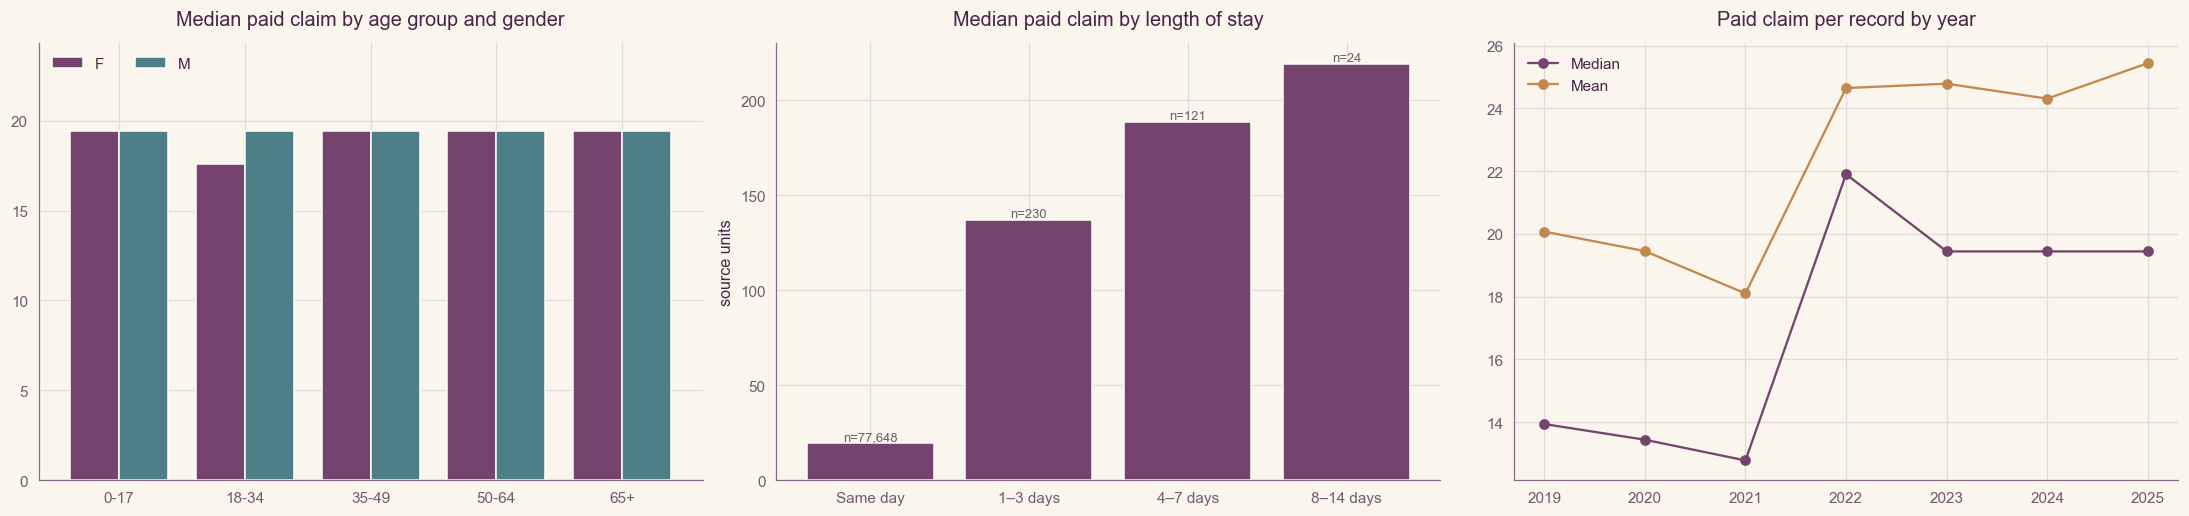

In [107]:
# What drives the size of a claim: age, gender, length of stay and year.
paid = df[df.total_claim.gt(0)].copy()
paid['age_group'] = pd.cut(paid.age, bins=AGE_BINS, right=False, labels=AGE_LABELS)
age_gender = paid.pivot_table(index='age_group', columns='gender', values='total_claim', aggfunc='median', observed=True)
paid['stay_band'] = pd.cut(paid.length_of_stay, bins=[-1, 0, 3, 7, 14, np.inf], labels=['Same day', '1–3 days', '4–7 days', '8–14 days', '15+ days'])
stay_tbl = paid.groupby('stay_band', observed=True).total_claim.agg(records='size', median='median', mean='mean')
by_year = paid.groupby(paid.visit_date.dt.year).total_claim.agg(records='size', median='median', mean='mean', total='sum')
by_year.index.name = 'year'
display(age_gender.round(1))
display(stay_tbl.round(1))

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
age_gender.plot(kind='bar', ax=ax[0], color=[CL['mauve'], CL['teal'], CL['amber']][:age_gender.shape[1]], width=.78)
ax[0].set_title('Median paid claim by age group and gender'); ax[0].set_xlabel(''); ax[0].tick_params(axis='x', rotation=0)
ax[0].set_ylim(0, age_gender.to_numpy().max() * 1.25); ax[0].legend(title='', ncol=3, loc='upper left')
ax[1].bar(stay_tbl.index.astype(str), stay_tbl['median'], color=CL['mauve'])
for x, (m, n) in enumerate(zip(stay_tbl['median'], stay_tbl.records)):
    ax[1].text(x, m, f'n={n:,}', ha='center', va='bottom', fontsize=8.5, color=CL['muted'])
ax[1].set_title('Median paid claim by length of stay'); ax[1].set_ylabel('source units')
ax[2].plot(by_year.index, by_year['median'], marker='o', color=CL['mauve'], label='Median')
ax[2].plot(by_year.index, by_year['mean'], marker='o', color=CL['amber'], label='Mean')
ax[2].set_title('Paid claim per record by year'); ax[2].set_xticks(by_year.index); ax[2].legend()
plt.tight_layout(); plt.show()

inpatient_share = structure.loc[structure.component.eq('Inpatient'), 'share_pct']
top5 = top_share.loc[top_share.top_patients_pct.eq(5), 'share_of_total_claim_pct'].iloc[0]
items = [f'The top 5% of patients by spend account for {strong(f"{top5:.0f}%")} of all claim money (Gini {gini:.2f}).']
if len(inpatient_share):
    items.append(f'Inpatient spend is {strong(f"{inpatient_share.iloc[0]:.1f}%")} of component spend; {strong(structure.iloc[0].component)} is the largest component overall.')
if len(stay_tbl) > 1 and stay_tbl['median'].iloc[0] > 0:
    stay_ratio = stay_tbl['median'].iloc[-1] / stay_tbl['median'].iloc[0]
    items.append(f'Median claims in the longest-stay band ({stay_tbl.index[-1]}) are about {strong(f"{stay_ratio:.1f}×")} those of the shortest band ({stay_tbl.index[0]}).')
items.append(f'The age group with the highest median claim is {strong(age_gender.median(axis=1).idxmax())}.')
cl_takeaways('Key takeaways: cost and spending', items,
             caveat='Currency, accounting definitions and the meaning of zero-value claims are unverified. Descriptive comparisons only; they do not control for diagnosis mix.')


<div id="carelytics-utilization" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Patient Utilization and Retention</h2></div>

,patients_pct,visit_days_pct,claims_pct
band,,,
1 day,55.5,25.5,22.8
2 days,20.7,19.0,17.1
3–4 days,13.9,21.3,20.4
5–9 days,7.9,22.6,25.0
10+ days,2.0,11.6,14.8


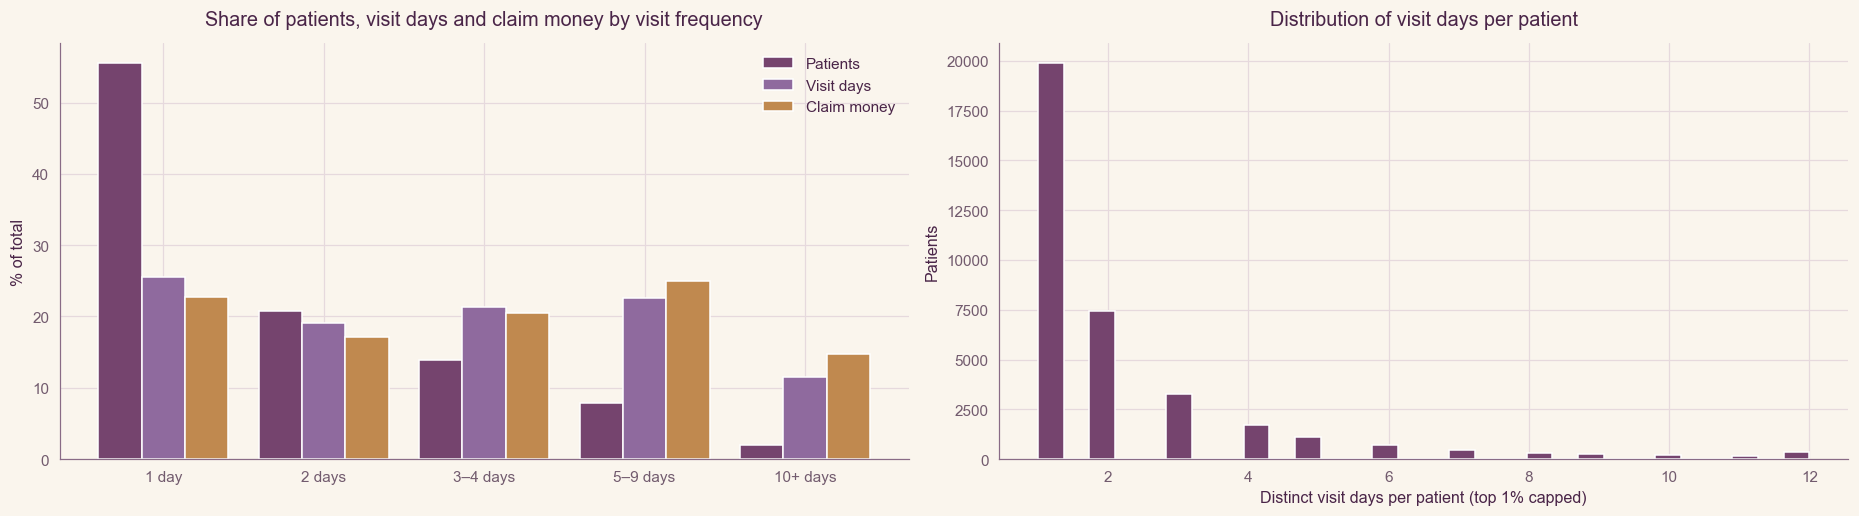

In [108]:
# How often do patients come back? Visit frequency and who generates the volume.
visit_days = df.drop_duplicates(['patient_id', 'visit_date']).groupby('patient_id').size().rename('visit_days')
spend = df.groupby('patient_id').total_claim.sum().rename('claims')
u = pd.concat([visit_days, spend], axis=1).dropna()
u['band'] = pd.cut(u.visit_days, bins=[0, 1, 2, 4, 9, np.inf], labels=['1 day', '2 days', '3–4 days', '5–9 days', '10+ days'])
freq = u.groupby('band', observed=True).agg(patients=('visit_days', 'size'), visit_days=('visit_days', 'sum'), claims=('claims', 'sum'))
freq_pct = freq.div(freq.sum()).mul(100)
freq_pct.columns = ['patients_pct', 'visit_days_pct', 'claims_pct']
display(freq_pct.round(1))

fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
x = np.arange(len(freq_pct)); w = .27
for i, (col, name, colr) in enumerate([('patients_pct', 'Patients', CL['mauve']), ('visit_days_pct', 'Visit days', CL['orchid']), ('claims_pct', 'Claim money', CL['amber'])]):
    ax[0].bar(x + (i - 1) * w, freq_pct[col], width=w, color=colr, label=name)
ax[0].set_xticks(x); ax[0].set_xticklabels(freq_pct.index.astype(str)); ax[0].set_ylabel('% of total'); ax[0].legend()
ax[0].set_title('Share of patients, visit days and claim money by visit frequency')
ax[1].hist(u.visit_days.clip(upper=u.visit_days.quantile(.99)), bins=30, color=CL['mauve'])
ax[1].set_xlabel('Distinct visit days per patient (top 1% capped)'); ax[1].set_ylabel('Patients'); ax[1].set_title('Distribution of visit days per patient')
plt.tight_layout(); plt.show()

k = max(1, int(np.ceil(len(u) * .05)))
heavy = u.sort_values('visit_days', ascending=False).head(k)
cl_takeaways('Key takeaways: patient utilization', [
    f'{strong(f"{freq_pct.patients_pct.iloc[0]:.1f}%")} of patients were seen on a single observed day.',
    f'The most frequent 5% of patients ({k:,} people) account for {strong(f"{heavy.visit_days.sum() / u.visit_days.sum():.1%}")} of visit days and {strong(f"{heavy.claims.sum() / max(u.claims.sum(), 1):.1%}")} of claim money.',
    f'Median patient has {strong(f"{u.visit_days.median():.0f}")} visit day(s); the maximum is {int(u.visit_days.max())}.'],
    caveat='Visit days are distinct observed dates within this source; visits to other providers or before the source began are not seen.')


,statistic,value
0,Median gap (days),58.0
1,25th percentile,11.0
2,75th percentile,148.0
3,Gaps within 30 days (%),38.2
4,Gaps within 90 days (%),63.3
5,Gaps within 180 days (%),78.8
6,Gaps within 365 days (%),89.2


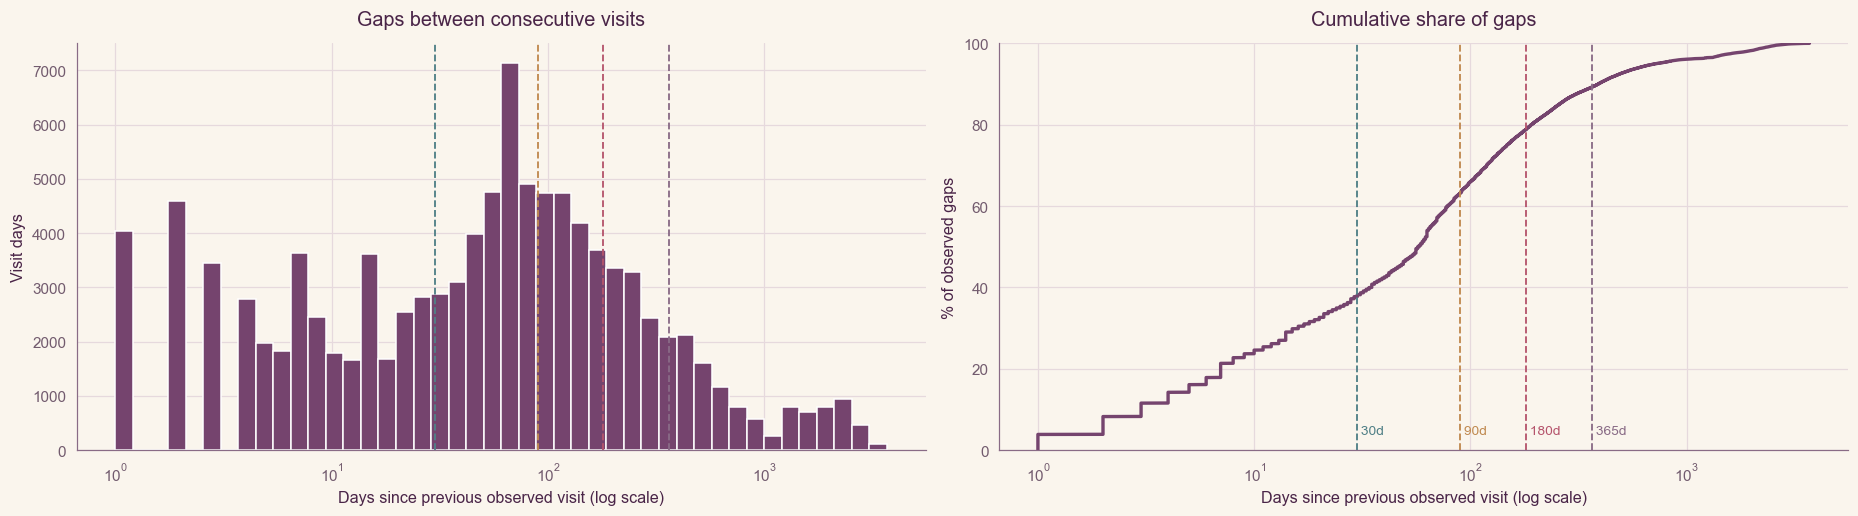

In [109]:
# Time between visits: how long do patients wait before the next observed visit day?
gaps = episodes.days_since_last_visit.dropna().astype(float)
gaps = gaps[gaps > 0]
marks = [30, 90, 180, 365]
gap_stats = pd.DataFrame({'statistic': ['Median gap (days)', '25th percentile', '75th percentile'] + [f'Gaps within {m} days (%)' for m in marks],
                          'value': [gaps.median(), gaps.quantile(.25), gaps.quantile(.75)] + [gaps.le(m).mean() * 100 for m in marks]})
display(gap_stats.round(1))

fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
bins = np.logspace(0, np.log10(max(gaps.max(), 10)), 45)
ax[0].hist(gaps, bins=bins, color=CL['mauve']); ax[0].set_xscale('log')
xs = np.sort(gaps.to_numpy()); ys = np.arange(1, len(xs) + 1) / len(xs) * 100
ax[1].plot(xs, ys, color=CL['mauve'], lw=2.2); ax[1].set_xscale('log'); ax[1].set_ylim(0, 100)
for m, colr in zip(marks, [CL['teal'], CL['amber'], CL['rose'], CL['dusk']]):
    for a in ax:
        a.axvline(m, color=colr, ls='--', lw=1.2)
    ax[1].text(m, 4, f' {m}d', color=colr, fontsize=9)
ax[0].set(xlabel='Days since previous observed visit (log scale)', ylabel='Visit days', title='Gaps between consecutive visits')
ax[1].set(xlabel='Days since previous observed visit (log scale)', ylabel='% of observed gaps', title='Cumulative share of gaps')
plt.tight_layout(); plt.show()
cl_note('Only gaps that were actually observed are shown. Patients who never returned have no gap, so this curve is conditional on a return and is not a survival estimate.')


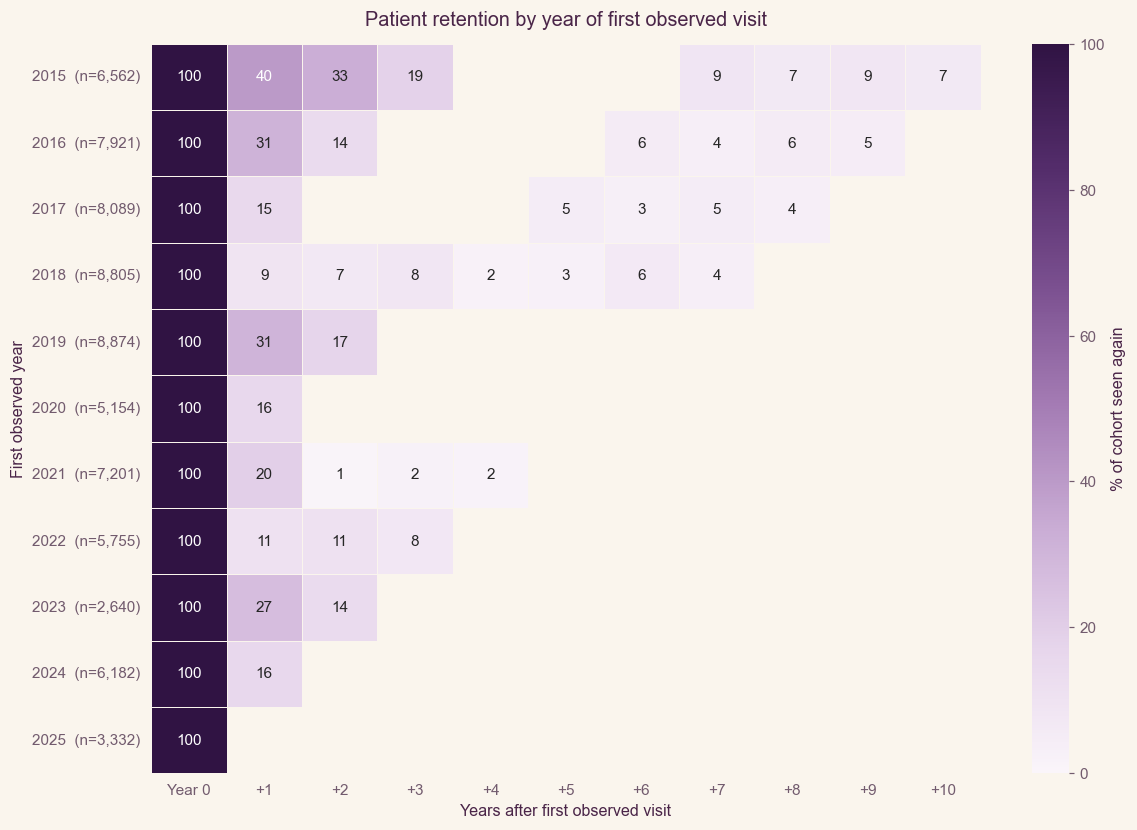

In [110]:
# Cohort retention: of the patients first seen in a given year, how many are seen again in later years?
first_year_seen = episodes.groupby('patient_id').year.min().rename('cohort')
activity = episodes[['patient_id', 'year']].drop_duplicates().merge(first_year_seen, on='patient_id')
activity['years_after'] = activity.year - activity.cohort
cohort = activity.groupby(['cohort', 'years_after']).patient_id.nunique().unstack()
cohort_size = cohort[0]
retention = cohort.div(cohort_size, axis=0).mul(100)
retention = retention.loc[cohort_size >= 50]
if retention.empty:
    raise ValueError('No cohort has at least 50 patients; lower the 50-patient threshold above.')
retention.index = [f'{int(c)}  (n={int(cohort_size[c]):,})' for c in retention.index]
retention.columns = [f'+{int(c)}' if c else 'Year 0' for c in retention.columns]

fig, ax = plt.subplots(figsize=(11, max(3.2, .55 * len(retention) + 1.6)))
sns.heatmap(retention, cmap=CL_SEQ, annot=True, fmt='.0f', vmin=0, vmax=100, linewidths=.6, linecolor=CL['paper'], cbar_kws={'label': '% of cohort seen again'}, ax=ax)
ax.set_title('Patient retention by year of first observed visit'); ax.set_ylabel('First observed year'); ax.set_xlabel('Years after first observed visit'); ax.grid(False)
plt.tight_layout(); plt.show()
cl_note('"First observed" means first seen in this source, not first ever. Blank cells are years the source does not reach yet. Cohorts smaller than 50 patients are hidden.')

if retention.shape[1] > 1:
    nxt = retention.iloc[:, 1].dropna()
    cl_takeaways('Key takeaways: retention', [
        f'On average {strong(f"{nxt.mean():.0f}%")} of a cohort is seen again in the following calendar year (range {nxt.min():.0f}%–{nxt.max():.0f}%).',
        'Retention that falls steadily with each year after the first visit is typical of episodic care; a flat curve would point to chronic follow-up.'],
        caveat='Drop-offs can mean recovery, care elsewhere or incomplete source coverage; the data cannot separate them.')


<div id="carelytics-section-53" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Relationships and Correlations</h2></div>

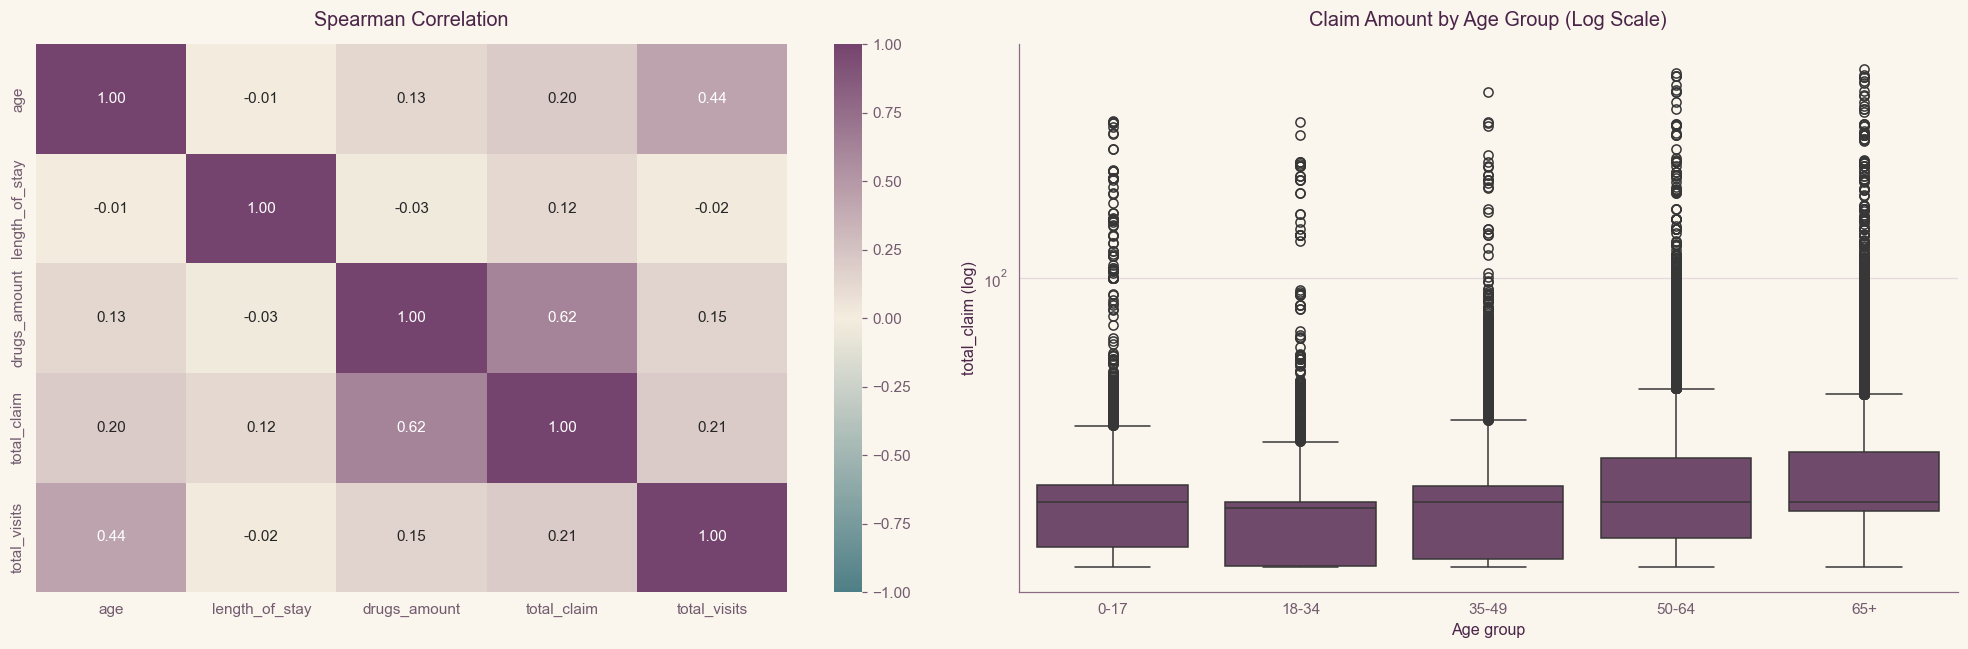

In [111]:
num_cols = ["age", "length_of_stay", "drugs_amount", "investigation_amount",
            "total_claim", "total_visits"]
num_cols = [c for c in num_cols if df[c].nunique(dropna=True) > 1]   # constant columns have no correlation
corr = df[num_cols].apply(pd.to_numeric, errors="coerce").corr(method="spearman")

paid = df[df["total_claim"] > 0].copy()
paid["age_group"] = pd.cut(paid["age"], bins=[0, 18, 35, 50, 65, 111], right=False,
                           labels=["0-17", "18-34", "35-49", "50-64", "65+"])

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap=CL_DIV, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Spearman Correlation")

sns.boxplot(data=paid, x="age_group", y="total_claim", color=CL['mauve'], ax=ax[1])
ax[1].set_yscale("log")
ax[1].set_title("Claim Amount by Age Group (Log Scale)")
ax[1].set_xlabel("Age group")
ax[1].set_ylabel("total_claim (log)")

plt.tight_layout()
plt.show()

_pairs_c = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
_top_c = _pairs_c.reindex(_pairs_c.abs().sort_values(ascending=False).index).head(3)
dropped_const = [c_ for c_ in ["investigation_amount", "length_of_stay"] if c_ in df.columns and c_ not in num_cols]
cl_takeaways('Key takeaways: relationships', [f'{strong(nice(a_))} and {strong(nice(b_))}: Spearman rho {v_:+.2f}.' for (a_, b_), v_ in _top_c.items()],
             caveat='Rank correlations describe monotonic association, not causation.' + (f' Constant columns left out: {", ".join(dropped_const)}.' if dropped_const else ''))


<div id="carelytics-section-55" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Phase 5: Statistical Analysis</h2></div>

Phase 5 groups the research questions (next section) and the tests that answer them, followed by the interpretation notes.


<div id="carelytics-section-56" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Research Questions and Hypotheses</h2></div>

Four exploratory comparisons use one observation per patient and Holm-adjusted p-values at 0.05: positive claim by gender (Mann–Whitney), positive claim by age group (Kruskal–Wallis), observed 30-day return versus age group (Chi-square when valid), and age versus positive claim (Spearman). Each null describes equality of distributions, independence, or zero monotonic association, respectively. Missing outcomes are excluded, never converted to negative labels.

In [112]:
from scipy import stats
# One earliest usable positive claim per patient for monetary comparisons.
base=df.loc[df.total_claim.gt(0) & ~df.age_imputed & ~df.age_conflict].sort_values(['visit_date','source_row_id']).drop_duplicates('patient_id').copy()
base['age_group']=pd.cut(base.age,bins=[0,18,35,50,65,111],right=False,labels=['0-17','18-34','35-49','50-64','65+'])
results=[]
f=base.loc[base.gender.eq('F'),'total_claim'].dropna().astype(float)
m=base.loc[base.gender.eq('M'),'total_claim'].dropna().astype(float)
if len(f) and len(m):
    u,p=stats.mannwhitneyu(f,m,alternative='two-sided')
    results.append(dict(question='Claim by gender',test='Mann–Whitney',n=len(f)+len(m),statistic=u,p_value=p,effect=2*u/(len(f)*len(m))-1,effect_name='rank-biserial (F vs M)'))
groups=[g.total_claim.dropna().to_numpy(dtype=float) for _,g in base.dropna(subset=['age_group']).groupby('age_group',observed=True)]
groups=[g for g in groups if len(g)]
if len(groups)>1 and np.ptp(np.concatenate(groups))>0:
    h,p=stats.kruskal(*groups);total=sum(map(len,groups));k=len(groups)
    results.append(dict(question='Claim by age group',test='Kruskal–Wallis',n=total,statistic=h,p_value=p,effect=max(0,(h-k+1)/(total-k)),effect_name='epsilon squared'))
# First reliably eligible dated observation per patient (independent unit).
q3=r.loc[r.revisit_30.notna() & r.age.notna() & ~r.age_imputed.fillna(False) & ~r.age_conflict.fillna(False)].sort_values('visit_date').drop_duplicates('patient_id')
t=pd.crosstab(q3.age_group,q3.revisit_30)
if t.shape[0]>1 and t.shape[1]==2:
    chi,p,dof,expected=stats.chi2_contingency(t)
    if (expected>=5).all():
        results.append(dict(question='30-day observed return by age',test='Chi-square',n=int(t.to_numpy().sum()),statistic=chi,p_value=p,effect=np.sqrt(chi/(t.to_numpy().sum()*(min(t.shape)-1))),effect_name="Cramer's V"))
    else:print('Q3 withheld: expected counts below 5. A suitable exact/permutation test is required.')
x=base.dropna(subset=['age','total_claim'])
if len(x)>2 and x.age.nunique()>1 and x.total_claim.nunique()>1:
    rho,p=stats.spearmanr(x.age.astype(float),x.total_claim.astype(float))
    results.append(dict(question='Age versus positive claim',test='Spearman',n=len(x),statistic=rho,p_value=p,effect=rho,effect_name='rho'))
statistical_results=pd.DataFrame(results)
if len(statistical_results):
    order=np.argsort(statistical_results.p_value.to_numpy());adjusted=np.zeros(len(order));running=0
    for rank,idx in enumerate(order):
        running=max(running,(len(order)-rank)*statistical_results.loc[idx,'p_value']);adjusted[idx]=min(1,running)
    statistical_results['p_holm']=adjusted
    statistical_results['evidence_at_0_05']=statistical_results.p_holm.lt(.05)
    def _effect_label(row):
        e=abs(row.effect); cuts=(.01,.06,.14) if row.effect_name=='epsilon squared' else (.1,.3,.5)
        return 'negligible' if e<cuts[0] else 'small' if e<cuts[1] else 'medium' if e<cuts[2] else 'large'
    statistical_results['effect_size_label']=statistical_results.apply(_effect_label,axis=1)
    statistical_results['practically_meaningful']=statistical_results.evidence_at_0_05 & statistical_results.effect_size_label.ne('negligible')
    display(statistical_results)
    statistical_results.to_csv(OUT/'statistical_results.csv',index=False)
display(base.groupby('age_group',observed=True).total_claim.agg(['count','median']))
print('Inference is exploratory; associations do not prove causation. Unknown return outcomes are excluded.')
if len(statistical_results):
    cl_takeaways('Key takeaways: statistical tests', [
        f'{strong(r_.question)}: {r_.test}, n={int(r_.n):,}, Holm p={r_.p_holm:.2g}, {r_.effect_name} {r_.effect:+.3f} ({strong(r_.effect_size_label)} effect)'
        + (' - statistically significant but practically negligible.' if (r_.evidence_at_0_05 and r_.effect_size_label == 'negligible') else '.')
        for r_ in statistical_results.itertuples()],
        caveat='With thousands of patients almost any difference is significant; the effect-size label says whether it is large enough to matter. Rules of thumb: |r| or V below 0.1 negligible, 0.1-0.3 small, 0.3-0.5 medium; epsilon squared below 0.01 negligible, 0.01-0.06 small, 0.06-0.14 medium.')


,question,test,n,statistic,p_value,effect,effect_name,p_holm,evidence_at_0_05,effect_size_label,practically_meaningful
0,Claim by gender,Mann–Whitney,35806,1.519819e+08,4.917598e-02,-0.012169,rank-biserial (F vs M),4.917598e-02,True,negligible,False
1,Claim by age group,Kruskal–Wallis,35806,1.059646e+03,4.223333e-228,0.029487,epsilon squared,1.689333e-227,True,small,True
2,30-day observed return by age,Chi-square,29074,8.073534e+02,1.961335e-173,0.166640,Cramer's V,5.884006e-173,True,small,True
3,Age versus positive claim,Spearman,35806,1.126452e-01,1.940344e-101,0.112645,rho,3.880689e-101,True,small,True


,count,median
age_group,,
0-17,7915,19.44
18-34,8035,17.64
35-49,6924,19.44
50-64,7112,19.44
65+,5820,19.44


Inference is exploratory; associations do not prove causation. Unknown return outcomes are excluded.


<div id="clean-interpretation" style="background:#F2E6D7;border-top:1px solid #9B7B79;padding:24px 28px;color:#4A2548;margin:24px 0 16px"><div style="font:10px Arial;letter-spacing:3px">CARELYTICS / DATA QUALITY</div><h2 style="font:30px Georgia;color:#4A2548;margin:12px 0 0">Interpretation and limitations</h2></div>
Results are generated in the preceding cell from the cleaned data. Previous hard-coded numerical conclusions have been removed.

- The tests use at most one observation per patient, and exclude imputed or conflicting ages when age is involved. Holm-adjusted p-values address four comparisons. Results describe selected usable observations, not all hospital patients.
- Q1–Q2 compare positive claim distributions; Q4 tests monotonic association. They do not establish causation. Effect sizes and sample sizes accompany p-values.
- Q3 concerns a later observed visit day, not inpatient readmission. It excludes incomplete date histories and censored outcomes; Chi-square is withheld if expected cell counts are too small.
- Disease charts now show coarse ICD chapter groups. Fine inherited labels were inconsistent; syntax checks do not clinically validate diagnoses or codes.
- Records are claims, not proven separate encounters. Annual changes can reflect source coverage. No population denominators establish utilization rates.
- Data-owner review is still needed for duplicate assumptions, missingness, currency, accounting definitions, diagnosis labels, and follow-up coverage.


<div id="modeling-overview" style="padding:22px;background:#f2e6d7;border-left:4px solid #75446e;color:#4a2548"><h2 style="font:28px Georgia">Predictive modeling &mdash; research benchmarks</h2><p>Three prediction tasks are trained and evaluated on separate, later time periods: the observed 30-day return, the daily claim amount and the observed ICD chapter. No numbers are quoted here on purpose &mdash; they are computed live in the <b>Model scorecard</b> (section 22), which compares every model with a simple baseline and states plainly where a model adds nothing.</p><p>Nothing in these sections supports operational or clinical use. Full comparisons, limitations and the saved research models follow.</p></div>


<div id="modeling-1" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Scope and reproducibility</h2></div>

In [113]:
from pathlib import Path
import json, hashlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
    log_loss, precision_score, recall_score, f1_score, balanced_accuracy_score,
    confusion_matrix, precision_recall_curve, roc_curve)
SEED=42
BASE=PROJECT
SOURCE_DIR=PROJECT / 'cleaning_outputs'
MODEL_OUT=BASE/'outputs'/'modeling'; MODEL_OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.facecolor':'#faf5ed','axes.facecolor':'#faf5ed','axes.edgecolor':'#896b86','axes.labelcolor':'#4a2548','text.color':'#4a2548','axes.titleweight':'normal','figure.dpi':110})
print('Target: next observed visit day within 30 days; prediction at start of index day.')
print('Research benchmark only. Source coverage is unverified; outcome is not inpatient readmission.')

Target: next observed visit day within 30 days; prediction at start of index day.
Research benchmark only. Source coverage is unverified; outcome is not inpatient readmission.


<div id="modeling-3" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Build point-in-time features</h2></div>

In [114]:
ep=pd.read_csv(SOURCE_DIR/'observed_patient_days.csv',parse_dates=['visit_date'])
ep=ep.sort_values(['patient_id','visit_date']).reset_index(drop=True)
assert not ep.duplicated(['patient_id','visit_date']).any()
# Recompute history from all reliable observed days, strictly before the index day.
g=ep.groupby('patient_id',sort=False)
ep['prior_visit_days']=g.cumcount()
ep['days_since_previous']=(ep.visit_date-g.visit_date.shift()).dt.days
ep['history_days']=(ep.visit_date-g.visit_date.transform('min')).dt.days
history_groups=list(ep.groupby('patient_id',sort=False).indices.values())
history_dates=ep.visit_date.to_numpy(dtype='datetime64[D]').astype('int64')
for window in [30,90,180,365]:
    counts=np.zeros(len(ep),dtype=int)
    for idx in history_groups:
        dates=history_dates[idx]
        counts[idx]=np.arange(len(idx))-np.searchsorted(dates,dates-window,side='left')
    ep[f'prior_days_{window}']=counts
ep['month_sin']=np.sin(2*np.pi*ep.visit_date.dt.month/12)
ep['month_cos']=np.cos(2*np.pi*ep.visit_date.dt.month/12)
ep['weekday']=ep.visit_date.dt.dayofweek
ep['calendar_year']=ep.visit_date.dt.year
# Use original contemporaneous demographics, avoiding future patient-level conflict flags/imputation.
demo=pd.read_csv(SOURCE_DIR/'cleaned_records.csv',usecols=['patient_id','visit_date','age_original','gender_original','date_reliable'],parse_dates=['visit_date'],low_memory=False)
demo=demo.loc[demo.patient_id.notna() & demo.date_reliable].copy()
demo['age_current']=pd.to_numeric(demo.age_original,errors='coerce')
demo['age_current']=demo.age_current.where(demo.age_current.between(0,110))
demo['gender_current']=demo.gender_original.astype('string').str.strip().str.upper().replace({'MALE':'M','FEMALE':'F'})
demo['gender_current']=demo.gender_current.where(demo.gender_current.isin(['F','M']))
demo=demo.groupby(['patient_id','visit_date']).agg(age_current=('age_current','median'),age_distinct=('age_current','nunique'),gender_current=('gender_current','first'),gender_distinct=('gender_current','nunique')).reset_index()
demo.loc[demo.age_distinct.gt(1),'age_current']=np.nan
demo.loc[demo.gender_distinct.ne(1),'gender_current']='Unknown'
ep=ep.merge(demo,on=['patient_id','visit_date'],how='left',validate='one_to_one')
ep['gender_female']=ep.gender_current.eq('F').astype(int)
ep['gender_male']=ep.gender_current.eq('M').astype(int)
ep['age_missing']=ep.age_current.isna().astype(int)
ep['gender_unknown']=~ep.gender_current.isin(['F','M'])
end=ep.visit_date.max()
next_gap=(ep.groupby('patient_id').visit_date.shift(-1)-ep.visit_date).dt.days
# Equal ascertainment window for positives and negatives; no late positives retained selectively.
eligible=ep.temporal_history_complete & ep.visit_date.le(end-pd.Timedelta(days=30))
data=ep.loc[eligible].copy()
data['target']=next_gap.loc[eligible].between(1,30).astype(int)
FEATURES=['age_current','age_missing','gender_female','gender_male','prior_visit_days','days_since_previous','history_days','prior_days_30','prior_days_90','prior_days_180','prior_days_365','month_sin','month_cos','weekday']
assert not set(FEATURES)&{'patient_id','revisit_30','days_to_next_visit','total_visits','visits_this_year','discharge_date','total_claim'}
assert np.isfinite(data[FEATURES].fillna(0).to_numpy()).all()
print('Eligible patient-days:',len(data),'| Patients:',data.patient_id.nunique(),'| Positive rate:',round(data.target.mean(),4))
# calendar_year is deliberately NOT a feature: train ends 2020 and test starts 2024, so a tree would only learn the data-recording era.
print('Positive rate by year:',data.groupby(data.visit_date.dt.year).target.mean().round(3).to_dict())
print('Retrospective cohort restriction: complete reliable date histories across the source; prospective cohort transport is not established.')

Eligible patient-days: 122019 | Patients: 60726 | Positive rate: 0.2231
Positive rate by year: {2015: 0.169, 2016: 0.202, 2017: 0.22, 2018: 0.155, 2019: 0.228, 2020: 0.247, 2021: 0.203, 2022: 0.203, 2023: 0.25, 2024: 0.3, 2025: 0.302}
Retrospective cohort restriction: complete reliable date histories across the source; prospective cohort transport is not established.


<div id="modeling-5" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Purged chronological partitions</h2></div>

In [115]:
# Labels must mature strictly before the next stage starts. Final 30 days are censored.
SPLITS=dict(train_end='2020-12-02',selection_start='2021-01-01',selection_end='2022-12-02',calibration_start='2023-01-01',calibration_end='2023-12-02',threshold_start='2024-01-01',threshold_end='2024-06-01',test_start='2024-07-01')   # one place to change the time split
train=data.loc[data.visit_date.lt(SPLITS['train_end'])].copy()
valid=data.loc[data.visit_date.ge(SPLITS['selection_start']) & data.visit_date.lt(SPLITS['selection_end'])].copy()
cal=data.loc[data.visit_date.ge(SPLITS['calibration_start']) & data.visit_date.lt(SPLITS['calibration_end'])].copy()
threshold_set=data.loc[data.visit_date.ge(SPLITS['threshold_start']) & data.visit_date.lt(SPLITS['threshold_end'])].copy()
test=data.loc[data.visit_date.ge(SPLITS['test_start'])].copy()
parts={'train':train,'selection':valid,'calibration':cal,'threshold':threshold_set,'test':test}
split_report=pd.DataFrame([{'partition':name,'rows':len(d),'patients':d.patient_id.nunique(),'start':str(d.visit_date.min().date()),'end':str(d.visit_date.max().date()),'positive_rate':d.target.mean()} for name,d in parts.items()])
for a,b in zip(list(parts.values())[:-1],list(parts.values())[1:]):
    assert len(a)>100 and a.target.nunique()==2
    assert a.visit_date.max()+pd.Timedelta(days=30)<b.visit_date.min()
assert test.target.nunique()==2 and len(test)>100
assigned=pd.concat([d.assign(partition=k)[['patient_id','visit_date','partition']] for k,d in parts.items()])
assert not assigned.duplicated(['patient_id','visit_date']).any()
split_report.to_csv(MODEL_OUT/'split_summary.csv',index=False)
display(split_report)
_drift=split_report.positive_rate.max()-split_report.positive_rate.min()
if _drift>.05: print(f'WARNING: the positive rate moves by {_drift:.1%} across partitions, so part of any metric change between periods is label drift (often a change in how patient IDs are recorded), not model quality.')
print('Same patients may recur across time, matching longitudinal prediction; IDs are excluded. New-patient performance is reported separately.')

,partition,rows,patients,start,end,positive_rate
0,train,73490,37668,2015-05-05,2020-12-01,0.206654
1,selection,22202,13950,2021-02-01,2022-12-01,0.203765
2,calibration,2487,1861,2023-01-01,2023-12-01,0.223965
3,threshold,5238,3586,2024-01-01,2024-05-31,0.272814
4,test,14655,8231,2024-07-01,2025-08-01,0.308700


Same patients may recur across time, matching longitudinal prediction; IDs are excluded. New-patient performance is reported separately.


<div id="modeling-7" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Expanding-window model comparison</h2></div>

In [116]:
def prep(estimator,scaled=False):
    steps=[('impute',SimpleImputer(strategy='median',add_indicator=True))]
    if scaled:steps.append(('scale',StandardScaler()))
    return Pipeline(steps+[('model',estimator)])
candidates={
 'dummy':prep(DummyClassifier(strategy='prior')),
 'logistic_C0.1':prep(LogisticRegression(C=.1,max_iter=1500,random_state=SEED),True),
 'logistic_C1':prep(LogisticRegression(C=1,max_iter=1500,random_state=SEED),True),
 'random_forest':prep(RandomForestClassifier(n_estimators=180,max_depth=10,min_samples_leaf=25,max_features=.8,n_jobs=1,random_state=SEED)),
 'boosting_leaf7':prep(HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=7,learning_rate=.06,l2_regularization=10,early_stopping=False,random_state=SEED)),
 'boosting_leaf15':prep(HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=15,learning_rate=.06,l2_regularization=10,early_stopping=False,random_state=SEED))}
cv_rows=[]
for year in [2018,2019,2020]:
    start=pd.Timestamp(year,1,1);stop=min(pd.Timestamp(year+1,1,1),pd.Timestamp(SPLITS['train_end']))
    a=train.loc[train.visit_date.lt(start-pd.Timedelta(days=30))]
    b=train.loc[train.visit_date.ge(start) & train.visit_date.lt(stop)]
    assert a.visit_date.max()+pd.Timedelta(days=30)<b.visit_date.min()
    for name,template in candidates.items():
        m=clone(template).fit(a[FEATURES],a.target);p=m.predict_proba(b[FEATURES])[:,1]
        cv_rows.append({'model':name,'fold_year':year,'train_rows':len(a),'validation_rows':len(b),'AP':average_precision_score(b.target,p),'ROC_AUC':roc_auc_score(b.target,p),'Brier':brier_score_loss(b.target,p)})
    print('Completed temporal fold',year,flush=True)
cv=pd.DataFrame(cv_rows);cv.to_csv(MODEL_OUT/'temporal_cv.csv',index=False)
display(cv.groupby('model')[['AP','ROC_AUC','Brier']].mean().sort_values('AP',ascending=False))

Completed temporal fold 2018
Completed temporal fold 2019
Completed temporal fold 2020


,AP,ROC_AUC,Brier
model,,,
random_forest,0.271775,0.590368,0.165024
boosting_leaf7,0.271019,0.589779,0.164794
boosting_leaf15,0.269637,0.590513,0.164953
logistic_C1,0.268584,0.583379,0.165368
logistic_C0.1,0.268572,0.583375,0.165367
dummy,0.212909,0.500000,0.168260


<div id="modeling-9" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Select using validation only, calibrate and fix threshold</h2></div>

In [117]:
# Choose one candidate per family using training CV, then compare on the selection period.
cv_mean=cv.groupby('model').AP.mean()
families=[['dummy'],['logistic_C0.1','logistic_C1'],['random_forest'],['boosting_leaf7','boosting_leaf15']]
shortlist=[max(f,key=lambda n:cv_mean[n]) for f in families]
fitted={};selection_rows=[]
for name in shortlist:
    m=clone(candidates[name]).fit(train[FEATURES],train.target);fitted[name]=m
    p=m.predict_proba(valid[FEATURES])[:,1]
    selection_rows.append({'model':name,'AP':average_precision_score(valid.target,p),'ROC_AUC':roc_auc_score(valid.target,p),'Brier':brier_score_loss(valid.target,p)})
selection=pd.DataFrame(selection_rows).sort_values('AP',ascending=False)
winner=selection.iloc[0]['model'];best=fitted[winner]
selection.to_csv(MODEL_OUT/'selection_results.csv',index=False);display(selection)
# Frozen model: calibration is learned only on the dedicated 2023 partition.
def logits(p):
    p=np.clip(p,1e-6,1-1e-6);return np.log(p/(1-p)).reshape(-1,1)
calibrator=LogisticRegression(C=1e6,solver='lbfgs',random_state=SEED).fit(logits(best.predict_proba(cal[FEATURES])[:,1]),cal.target)
def probability(frame):return calibrator.predict_proba(logits(best.predict_proba(frame[FEATURES])[:,1]))[:,1]
threshold_probs=probability(threshold_set)
grid=np.linspace(.01,.99,199)
threshold_table=pd.DataFrame([{'threshold':t,'precision':precision_score(threshold_set.target,threshold_probs>=t,zero_division=0),'recall':recall_score(threshold_set.target,threshold_probs>=t,zero_division=0),'F1':f1_score(threshold_set.target,threshold_probs>=t,zero_division=0)} for t in grid])
CAPACITY=0.20   # operational budget: alert on the highest-risk 20% of patient-days
f1_threshold=float(threshold_table.sort_values(['F1','threshold'],ascending=[False,False]).iloc[0].threshold)
chosen_threshold=float(np.quantile(threshold_probs,1-CAPACITY))
flag_all_f1=f1_score(threshold_set.target,np.ones(len(threshold_set)),zero_division=0)
threshold_table.to_csv(MODEL_OUT/'threshold_selection.csv',index=False)
print('Selected:',winner,'| Frozen threshold (flags the top',f'{CAPACITY:.0%}','of the threshold period):',round(chosen_threshold,4))
print(f'For reference, the F1-optimal threshold ({f1_threshold:.3f}) flags {np.mean(threshold_probs>=f1_threshold):.0%} of patient-days and reaches F1 {threshold_table.F1.max():.3f}, against {flag_all_f1:.3f} for flagging everyone, so it is not used.')

,model,AP,ROC_AUC,Brier
3,boosting_leaf7,0.275320,0.600220,0.158733
2,random_forest,0.273386,0.593793,0.159299
1,logistic_C1,0.266207,0.578633,0.159925
0,dummy,0.203765,0.500000,0.162253


Selected: boosting_leaf7 | Frozen threshold (flags the top 20% of the threshold period): 0.28
For reference, the F1-optimal threshold (0.203) flags 68% of patient-days and reaches F1 0.452, against 0.429 for flagging everyone, so it is not used.


<div id="modeling-11" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Locked final evaluation and diagnostics</h2></div>

,model,n,prevalence,AP,ROC_AUC,Brier,log_loss,precision,recall,F1,balanced_accuracy,flagged_fraction,lift
0,flag_everyone_baseline,14655,0.3087,0.308700,0.500000,0.223818,0.646763,0.308700,1.000000,0.471766,0.500000,1.000000,1.000000
1,boosting_leaf7_raw,14655,0.3087,0.362129,0.582073,0.218369,0.633624,0.375335,0.185676,0.248447,0.523842,0.152712,1.215857
2,boosting_leaf7_calibrated,14655,0.3087,0.362129,0.582073,0.213601,0.619461,0.367750,0.382626,0.375041,0.544437,0.321187,1.191286


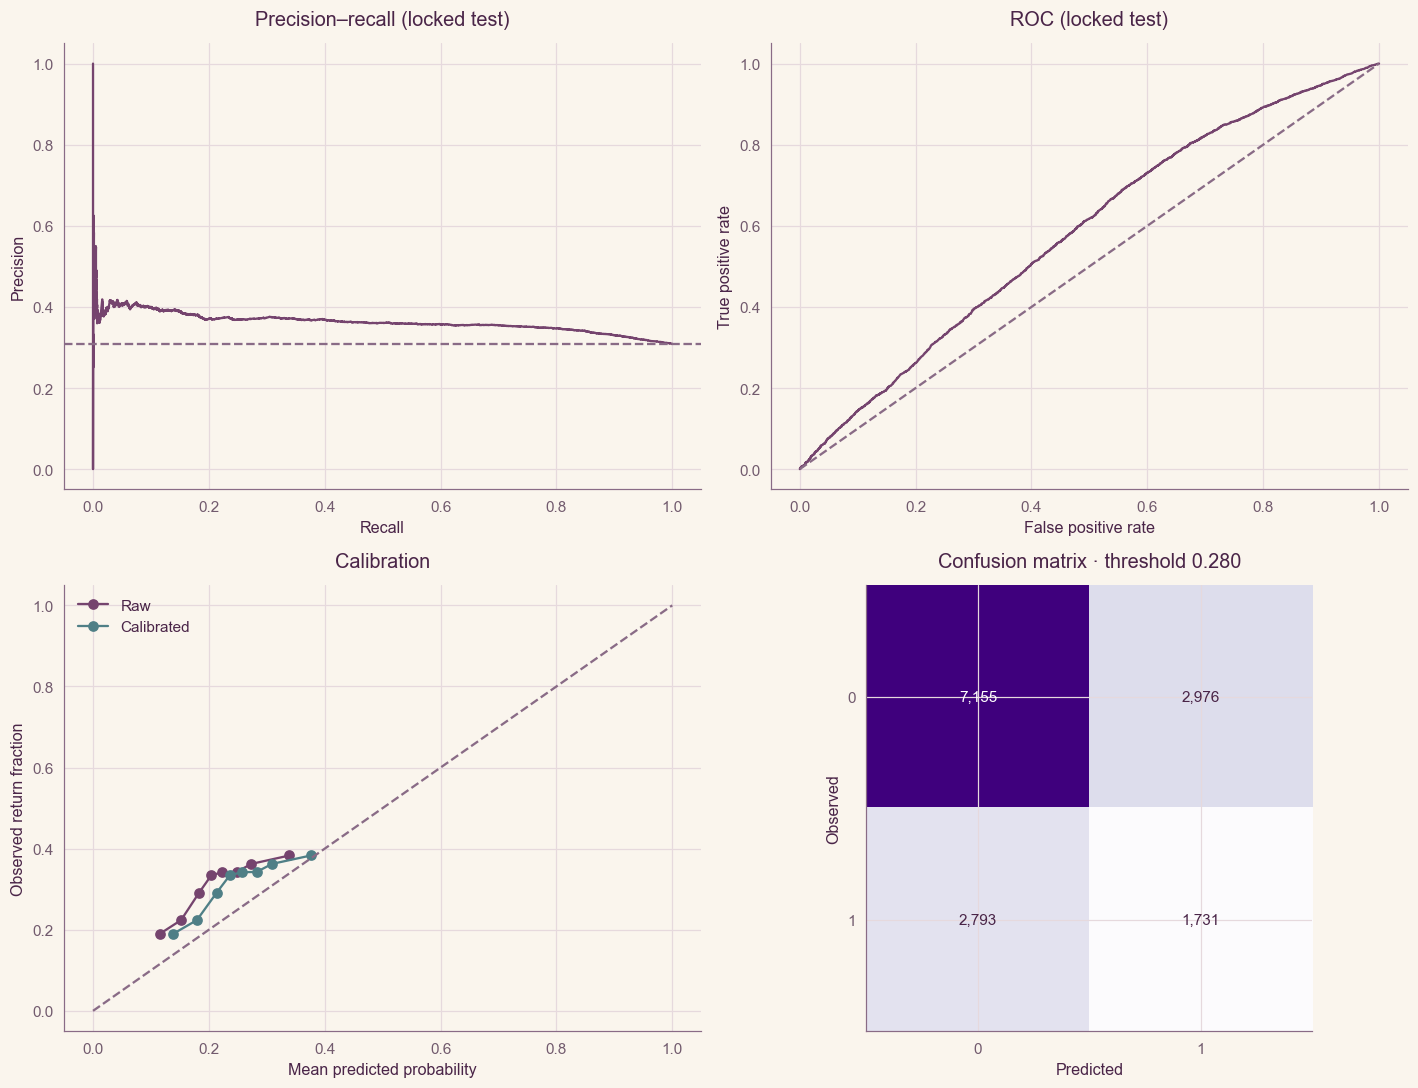

In [118]:
y=test.target.to_numpy();raw_p=best.predict_proba(test[FEATURES])[:,1];p=probability(test);pred=p>=chosen_threshold
def metrics(y,p,t):
    z=p>=t
    return {'n':len(y),'prevalence':float(np.mean(y)),'AP':average_precision_score(y,p),'ROC_AUC':roc_auc_score(y,p),'Brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),'precision':precision_score(y,z,zero_division=0),'recall':recall_score(y,z,zero_division=0),'F1':f1_score(y,z,zero_division=0),'balanced_accuracy':balanced_accuracy_score(y,z),'flagged_fraction':float(np.mean(z)),'lift':float(precision_score(y,z,zero_division=0)/max(float(np.mean(y)),1e-9))}
final_metrics=metrics(y,p,chosen_threshold)
prior=np.repeat(train.target.mean(),len(test))
test_results=pd.DataFrame([{'model':'flag_everyone_baseline',**metrics(y,prior,0.0)},{'model':winner+'_raw',**metrics(y,raw_p,chosen_threshold)},{'model':winner+'_calibrated',**final_metrics}])
test_results.to_csv(MODEL_OUT/'test_metrics.csv',index=False);display(test_results)
fig,axes=plt.subplots(2,2,figsize=(13,10))
precision,recall,_=precision_recall_curve(y,p);axes[0,0].plot(recall,precision,color='#75446e');axes[0,0].axhline(y.mean(),ls='--',color='#896b86');axes[0,0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall (locked test)')
fpr,tpr,_=roc_curve(y,p);axes[0,1].plot(fpr,tpr,color='#75446e');axes[0,1].plot([0,1],[0,1],'--',color='#896b86');axes[0,1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC (locked test)')
for vals,label in [(raw_p,'Raw'),(p,'Calibrated')]:
    actual,estimated=calibration_curve(y,vals,n_bins=8,strategy='quantile');axes[1,0].plot(estimated,actual,'o-',label=label)
axes[1,0].plot([0,1],[0,1],'--',color='#896b86');axes[1,0].legend();axes[1,0].set(xlabel='Mean predicted probability',ylabel='Observed return fraction',title='Calibration')
cm=confusion_matrix(y,pred);axes[1,1].imshow(cm,cmap='Purples')
for (i,j),v in np.ndenumerate(cm):axes[1,1].text(j,i,f'{v:,}',ha='center',va='center',color='white' if v>cm.max()/2 else '#4a2548')
axes[1,1].set(xticks=[0,1],yticks=[0,1],xlabel='Predicted',ylabel='Observed',title=f'Confusion matrix · threshold {chosen_threshold:.3f}')
plt.tight_layout();fig.savefig(MODEL_OUT/'evaluation.png',bbox_inches='tight');plt.show()

<div id="modeling-13" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Patient-cluster uncertainty, subgroups and interpretation</h2></div>

,dimension,group,n,prevalence,AP,ROC_AUC,Brier,log_loss,precision,recall,F1,balanced_accuracy,flagged_fraction,lift
0,patient_group,Not seen in training,12565,0.308635,0.365632,0.588119,0.212301,0.615830,0.368954,0.422898,0.394089,0.550001,0.353760,1.195437
1,patient_group,Seen in training,2090,0.309091,0.337432,0.544491,0.221418,0.641293,0.347328,0.140867,0.200441,0.511223,0.125359,1.123709
2,gender_current,F,8866,0.314009,0.361502,0.571972,0.216352,0.625524,0.364769,0.389009,0.376499,0.539457,0.334875,1.161654
3,gender_current,M,5787,0.300674,0.363194,0.596092,0.209441,0.610295,0.372842,0.372414,0.372628,0.551539,0.300328,1.240022
4,age_band,0–17,2403,0.183104,0.193847,0.502498,0.150902,0.481463,0.320000,0.018182,0.034409,0.504761,0.010404,1.747636
5,age_band,18–34,2631,0.277841,0.312331,0.547916,0.202116,0.595285,0.327354,0.099863,0.153040,0.510458,0.084759,1.178207
6,age_band,35–49,3027,0.347539,0.352989,0.502669,0.234309,0.665125,0.350694,0.384030,0.366606,0.502648,0.380575,1.009080
7,age_band,50–64,3163,0.342713,0.365825,0.536546,0.229683,0.654518,0.363107,0.517528,0.426778,0.522112,0.488460,1.059508
8,age_band,65+,3425,0.355036,0.390488,0.549998,0.233389,0.662412,0.388763,0.563322,0.460040,0.537886,0.514453,1.094994


Mean ROC-AUC inside age bands: 0.528 (0.50 = no ranking ability within a band; compare with the pooled test AUC).


,lower_95,upper_95
AP,0.349274,0.375166
ROC_AUC,0.571503,0.591087
Brier,0.209796,0.217286
recall,0.364468,0.401238
precision,0.355029,0.382131


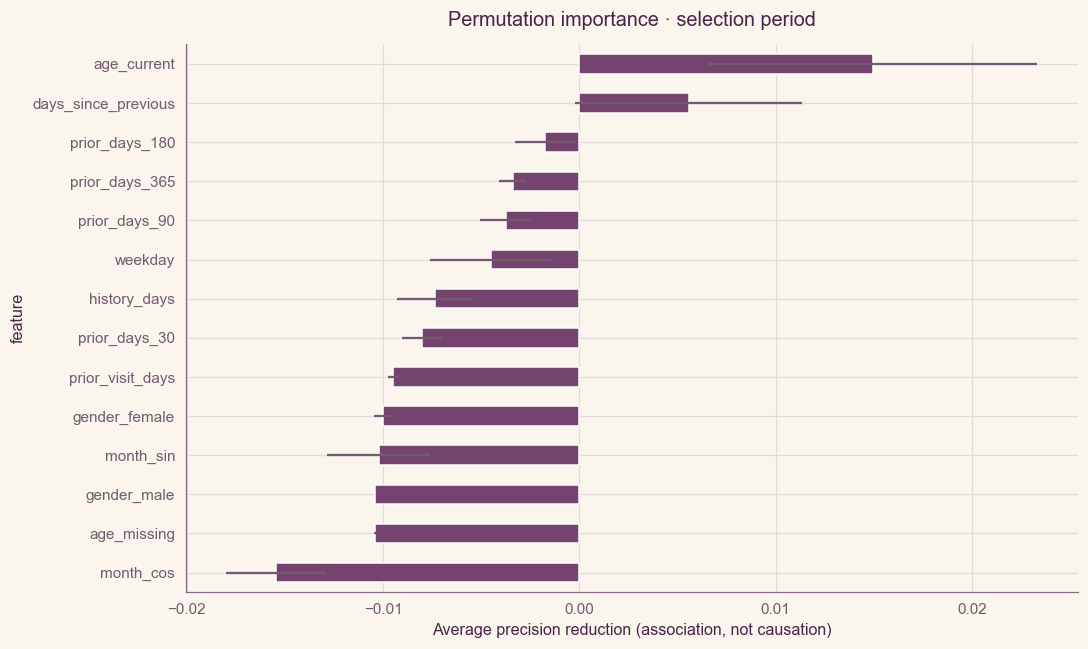

Point-in-time feature checks passed; no patient IDs or future visit totals used as predictors.


In [119]:
test=test.copy();test['probability']=p;test['prediction']=pred
test['patient_group']=np.where(test.patient_id.isin(train.patient_id),'Seen in training','Not seen in training')
test['age_band']=pd.cut(test.age_current,[-1,18,35,50,65,111],right=False,labels=['0–17','18–34','35–49','50–64','65+']).astype('string').fillna('Unknown')
subrows=[]
for field in ['patient_group','gender_current','age_band']:
    for group,d in test.groupby(field,dropna=False,observed=True):
        if len(d)>=50 and d.target.nunique()==2:subrows.append({'dimension':field,'group':str(group),**metrics(d.target,d.probability,chosen_threshold)})
subgroups=pd.DataFrame(subrows);subgroups.to_csv(MODEL_OUT/'subgroup_metrics.csv',index=False);display(subgroups)
_w=subgroups.loc[subgroups.dimension.eq('age_band'),'ROC_AUC']
print(f'Mean ROC-AUC inside age bands: {_w.mean():.3f} (0.50 = no ranking ability within a band; compare with the pooled test AUC).')
# Patient-cluster bootstrap accounts for repeated observations from the same patient.
codes,patients=pd.factorize(test.patient_id);rng=np.random.default_rng(SEED);boot=[]
for i in range(200):
    weights=np.bincount(rng.integers(0,len(patients),len(patients)),minlength=len(patients))[codes]
    if np.unique(y[weights>0]).size<2:continue
    boot.append({'AP':average_precision_score(y,p,sample_weight=weights),'ROC_AUC':roc_auc_score(y,p,sample_weight=weights),'Brier':np.average((p-y)**2,weights=weights),'recall':recall_score(y,pred,sample_weight=weights,zero_division=0),'precision':precision_score(y,pred,sample_weight=weights,zero_division=0)})
ci=pd.DataFrame(boot).quantile([.025,.975]).T.rename(columns={.025:'lower_95',.975:'upper_95'})
ci.to_csv(MODEL_OUT/'patient_cluster_confidence_intervals.csv');display(ci)
# Interpret on selection set, avoiding repeated choices using the locked test.
importance=permutation_importance(best,valid[FEATURES],valid.target,scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=1,max_samples=min(4000,len(valid)))
importance=pd.DataFrame({'feature':FEATURES,'AP_drop_mean':importance.importances_mean,'AP_drop_std':importance.importances_std}).sort_values('AP_drop_mean',ascending=False)
importance.to_csv(MODEL_OUT/'feature_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(10,6));importance.sort_values('AP_drop_mean').plot.barh(x='feature',y='AP_drop_mean',xerr='AP_drop_std',ax=ax,color='#75446e',legend=False);ax.set(title='Permutation importance · selection period',xlabel='Average precision reduction (association, not causation)');plt.tight_layout();fig.savefig(MODEL_OUT/'feature_importance.png',bbox_inches='tight');plt.show()
# Back-check rolling features against explicit histories for deterministic samples.
for ix in np.linspace(0,len(ep)-1,100,dtype=int):
    row=ep.iloc[ix];past=ep.loc[ep.patient_id.eq(row.patient_id) & ep.visit_date.lt(row.visit_date),'visit_date']
    assert row.prior_visit_days==len(past)
    for w in [30,90,180,365]:assert row[f'prior_days_{w}']==int(past.ge(row.visit_date-pd.Timedelta(days=w)).sum())
print('Point-in-time feature checks passed; no patient IDs or future visit totals used as predictors.')

<div id="modeling-15" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Save reproducible model and model card</h2></div>

In [120]:
bundle={'pipeline':best,'sigmoid_calibrator':calibrator,'features':FEATURES,'threshold':chosen_threshold,'target':'later observed visit day within 30 days','prediction_time':'start of index day','sklearn_version':sklearn.__version__}
joblib.dump(bundle,MODEL_OUT/'observed_return_30_model.joblib')
loaded=joblib.load(MODEL_OUT/'observed_return_30_model.joblib')
reloaded=loaded['sigmoid_calibrator'].predict_proba(logits(loaded['pipeline'].predict_proba(test[FEATURES].head(30))[:,1]))[:,1]
assert np.allclose(reloaded,p[:30])
data.assign(partition=data.index.map(pd.concat([d.assign(partition=k)['partition'] for k,d in parts.items()]).to_dict())).to_csv(MODEL_OUT/'modeling_dataset.csv',index=False)
manifest={'seed':SEED,'python':platform.python_version(),'sklearn':sklearn.__version__,'selected_model':winner,'threshold':chosen_threshold,'features':FEATURES,'source_endpoint':str(end.date()),'eligible_rows':len(data),'test_metrics':final_metrics,'source_hashes':{f:hashlib.sha256((SOURCE_DIR/f).read_bytes()).hexdigest() for f in ['observed_patient_days.csv','cleaned_records.csv']}}
(MODEL_OUT/'model_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
test[['patient_id','visit_date','target','probability','prediction','patient_group']].to_csv(MODEL_OUT/'test_predictions.csv',index=False)
features_doc=pd.DataFrame({'feature':FEATURES,'available_at':'start of index day','definition':['Current-day observed age; same-day conflicts become missing','Missing current age indicator','Current observed F','Current observed M','Number of strictly earlier distinct observed visit days','Days since prior observed visit; missing for first visit','Days since first observed visit','Earlier distinct days in preceding 30 days','Earlier distinct days in preceding 90 days','Earlier distinct days in preceding 180 days','Earlier distinct days in preceding 365 days','Sine of index month','Cosine of index month','Index weekday (Monday=0)']})
features_doc.to_csv(MODEL_OUT/'feature_contract.csv',index=False)
card=f'''# Carelytics — observed 30-day return modeling

## Intended use
Exploratory research benchmark for predicting a later observed patient-day within 30 days, at the start of the index day. This is not confirmed readmission, a clinical decision tool, or a deployment-ready validated medical model.

## Data and selection
One row per reliable distinct patient-day. Current observed age and gender plus strictly historical visit features are used. Missing age is imputed within each training pipeline. Same-day conflicting demographics remain unknown. No current charges, diagnoses, discharge dates, patient identifiers, next-visit gaps, inherited outcomes or full-history totals enter the predictors.

Only patients with complete reliable date histories in this source enter the retrospective outcome cohort. This is a future-informed cohort restriction, disclosed as a selection limitation rather than a predictor. Source coverage and visits outside the source are unknown. Source-year/month conflicts were excluded by prior cleaning, but billing-period semantics are unverified. The final 30 calendar days are excluded for both positives and negatives. Claims with identical rows were assumed duplicates during upstream cleaning; encounters are not independently verified. History before the first source record is left-truncated. Age/gender validation, provenance and source definitions need owner confirmation.

## Design
Three expanding yearly training folds (2018, 2019, 2020), each with a 30-day label maturity gap. Six candidate configurations across a prior-only baseline, logistic regression, random forest and histogram gradient boosting. Training-CV selects configuration within family; a separate 2021–2022 selection period selects family by average precision. Training ends 2020-12-01, selection ends 2022-12-01, calibration is 2023 through December 1, threshold selection is January–May 2024, and locked test starts July 2024. Each adjacent stage has more than 30 days between the last index day and next stage. All transformations fit on training observations only. Model remains frozen after training; sigmoid calibration uses the separate calibration period. The alert threshold flags the highest-risk 20% of patient-days (a capacity assumption fixed on the separate threshold period), not a clinical utility optimum. Calendar year is not a predictor because the periods do not overlap.

## Results
Selected model: **{winner}**. Frozen threshold: **{chosen_threshold:.3f}**.

{test_results.to_markdown(index=False)}

### Patient-cluster bootstrap intervals (200 replicates)
{ci.to_markdown()}

### Time partitions
{split_report.to_markdown(index=False)}

## Interpretation and limits
Permutation importance is computed on the selection period, not used to tune on the test. AP should be interpreted relative to test prevalence. Reported confidence intervals resample patients and describe uncertainty conditional on this source, model and cohort; they do not capture transport error. Same patients can occur in earlier and later periods because the target is longitudinal use; identifiers are excluded. Test results for patients not seen in training are reported separately. Subgroup differences are descriptive with potentially small samples and are not evidence of fairness or clinical safety. No model or calibration is selected using final test results, including if calibration degrades test metrics. Calendar drift and incomplete capture can dominate performance. Prospective/external validation, confirmed encounter definitions, source coverage verification, operational feature availability, clinical utility assessment and ongoing monitoring are required before any real use.

## Reuse
The joblib bundle includes preprocessing, fitted model, sigmoid calibrator, threshold and ordered feature contract. Load only trusted local model artifacts. Supply features defined in feature_contract.csv, using history strictly before the index day. Reproducing the notebook requires the existing cleaning output files and the versions in model_manifest.json. The bundle serialization was reloaded and its predictions matched. Training code is this notebook (the Modeling sections); no source files are modified.

Method reference: https://scikit-learn.org/stable/common_pitfalls.html
'''
(MODEL_OUT/'model_card.md').write_text(card,encoding='utf-8')
print('Saved model, diagnostics, reproducibility manifest, predictions and model card:',MODEL_OUT)

Saved model, diagnostics, reproducibility manifest, predictions and model card: C:\Users\nagat\OneDrive\Desktop\final _project\outputs\modeling


<div id="additional-modeling-1" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Additional targets and available labels</h2></div>

In [121]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
extra=pd.read_csv(SOURCE_DIR/'cleaned_records.csv',usecols=['patient_id','visit_date','date_reliable','total_claim','disease_category','icd10_format_issue'],parse_dates=['visit_date'],low_memory=False)
extra=extra.loc[extra.patient_id.notna() & extra.date_reliable].copy()
claim_groups=extra.groupby(['patient_id','visit_date'])
labels=claim_groups.agg(claim_total=('total_claim',lambda x:x.sum(min_count=len(x))),diagnosis_invalid=('icd10_format_issue','any'))
diagnosis_sets=claim_groups.disease_category.agg(lambda x:sorted(set(x.dropna())))
labels['diagnosis_group']=diagnosis_sets.map(lambda x:x[0] if len(x)==1 else ('MULTIPLE_CHAPTERS' if x else 'UNKNOWN'))
labels['diagnosis_unmapped']=diagnosis_sets.map(lambda x:any(v in ['UNKNOWN','UNMAPPED'] for v in x))
all_targets=ep.merge(labels.reset_index(),on=['patient_id','visit_date'],how='left',validate='one_to_one')
cost_data=all_targets.loc[all_targets.claim_total.notna() & all_targets.claim_total.ge(0)].copy()
diagnosis_data=all_targets.loc[all_targets.diagnosis_group.notna() & ~all_targets.diagnosis_group.isin(['UNKNOWN','UNMAPPED']) & ~all_targets.diagnosis_invalid.fillna(True) & ~all_targets.diagnosis_unmapped.fillna(True)].copy()
def time_parts(frame):
    return {'train':frame.loc[frame.visit_date.lt(SPLITS['train_end'])].copy(),
      'selection':frame.loc[frame.visit_date.ge(SPLITS['selection_start']) & frame.visit_date.lt(SPLITS['selection_end'])].copy(),
      'calibration':frame.loc[frame.visit_date.ge(SPLITS['calibration_start']) & frame.visit_date.lt(SPLITS['calibration_end'])].copy(),
      'threshold':frame.loc[frame.visit_date.ge(SPLITS['threshold_start']) & frame.visit_date.lt(SPLITS['threshold_end'])].copy(),
      'test':frame.loc[frame.visit_date.ge(SPLITS['test_start'])].copy()}
cost_parts=time_parts(cost_data);dx_parts=time_parts(diagnosis_data)
multi_split=pd.DataFrame([{'target':target,'partition':part,'rows':len(d),'patients':d.patient_id.nunique(),'start':str(d.visit_date.min().date()),'end':str(d.visit_date.max().date())} for target,parts in [('claim_total',cost_parts),('ICD_group',dx_parts)] for part,d in parts.items()])
multi_split.to_csv(MODEL_OUT/'additional_split_summary.csv',index=False);display(multi_split)
print('Cost: observed summed total_claim per patient-day; monetary units and accounting definitions unverified.')
print('Diagnosis: observed syntax-derived ICD chapter group, using pre-diagnosis features only; clinical truth is unverified.')

,target,partition,rows,patients,start,end
0,claim_total,train,107194,44878,2015-05-05,2020-12-01
1,claim_total,selection,28344,17240,2021-02-01,2022-12-01
2,claim_total,calibration,5412,3648,2023-01-01,2023-12-01
3,claim_total,threshold,7246,4758,2024-01-01,2024-05-31
4,claim_total,test,21215,10574,2024-07-01,2025-08-31
5,ICD_group,train,34297,14442,2019-04-01,2020-12-01
6,ICD_group,selection,28053,17114,2021-02-01,2022-12-01
7,ICD_group,calibration,5188,3561,2023-01-01,2023-12-01
8,ICD_group,threshold,6835,4598,2024-01-01,2024-05-31
9,ICD_group,test,19664,10152,2024-07-01,2025-08-31


Cost: observed summed total_claim per patient-day; monetary units and accounting definitions unverified.
Diagnosis: observed syntax-derived ICD chapter group, using pre-diagnosis features only; clinical truth is unverified.


<div id="additional-modeling-3" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Claim amount forecasting and temporal tuning</h2></div>

,model,MAE,RMSE
0,median_baseline,8.325764,21.765303
2,forest_log,8.354262,20.898182
3,boosting_log,8.407773,20.951914
1,ridge_log,8.433205,20.869788


,model,n,MAE,RMSE,R2,mean_observed,mean_predicted,zero_target_fraction
0,median_baseline,21215,10.5178,19.007082,-0.426027,24.638917,14.25,0.0
1,median_baseline,21215,10.5178,19.007082,-0.426027,24.638917,14.25,0.0


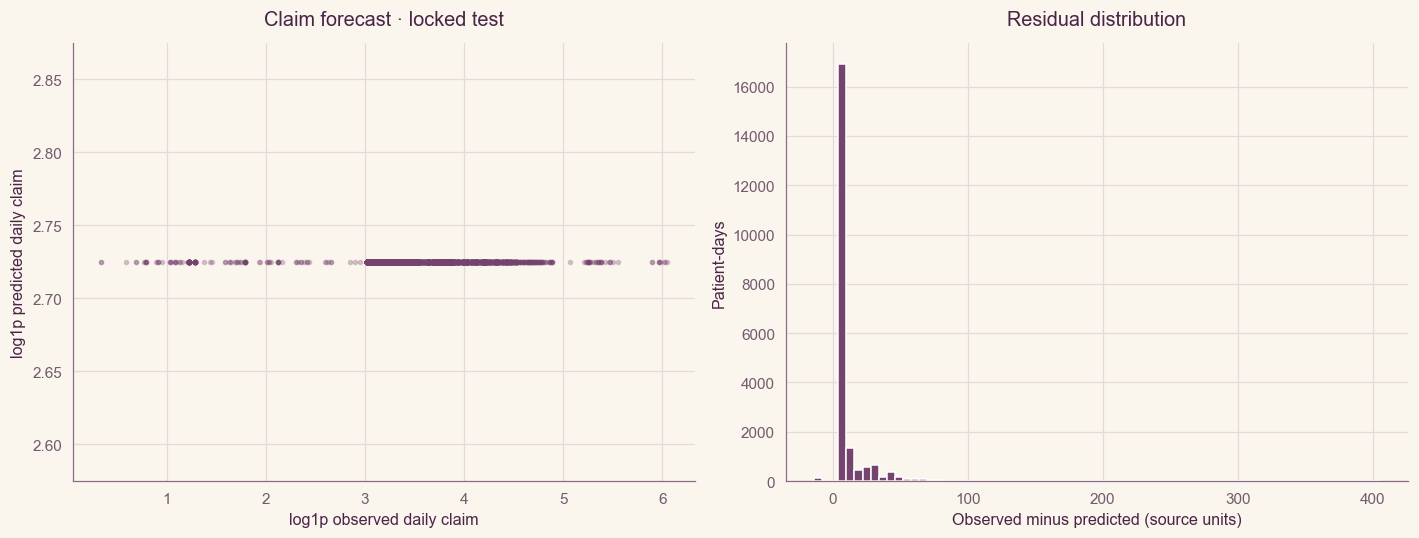

In [122]:
cost_candidates={
 'median_baseline':prep(DummyRegressor(strategy='median')),
 'ridge_log':TransformedTargetRegressor(regressor=prep(Ridge(alpha=10),True),func=np.log1p,inverse_func=np.expm1),
 'forest_log':TransformedTargetRegressor(regressor=prep(RandomForestRegressor(n_estimators=120,max_depth=10,min_samples_leaf=25,n_jobs=1,random_state=SEED)),func=np.log1p,inverse_func=np.expm1),
 'boosting_log':TransformedTargetRegressor(regressor=prep(HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=15,learning_rate=.06,l2_regularization=10,early_stopping=False,random_state=SEED)),func=np.log1p,inverse_func=np.expm1)}
cost_cv=[]
for year in [2018,2019,2020]:
    start=pd.Timestamp(year,1,1);stop=min(pd.Timestamp(year+1,1,1),pd.Timestamp(SPLITS['train_end']))
    a=cost_parts['train'].loc[cost_parts['train'].visit_date.lt(start-pd.Timedelta(days=30))]
    b=cost_parts['train'].loc[cost_parts['train'].visit_date.ge(start) & cost_parts['train'].visit_date.lt(stop)]
    for name,template in cost_candidates.items():
        m=clone(template).fit(a[FEATURES],a.claim_total);v=np.maximum(0,m.predict(b[FEATURES]))
        cost_cv.append({'model':name,'year':year,'MAE':mean_absolute_error(b.claim_total,v),'RMSE':np.sqrt(mean_squared_error(b.claim_total,v))})
cost_cv=pd.DataFrame(cost_cv);cost_cv.to_csv(MODEL_OUT/'cost_temporal_cv.csv',index=False)
cost_fitted={};cost_selection=[]
for name,template in cost_candidates.items():
    m=clone(template).fit(cost_parts['train'][FEATURES],cost_parts['train'].claim_total);cost_fitted[name]=m
    v=np.maximum(0,m.predict(cost_parts['selection'][FEATURES]))
    cost_selection.append({'model':name,'MAE':mean_absolute_error(cost_parts['selection'].claim_total,v),'RMSE':np.sqrt(mean_squared_error(cost_parts['selection'].claim_total,v))})
cost_selection=pd.DataFrame(cost_selection).sort_values('MAE');cost_selection.to_csv(MODEL_OUT/'cost_selection.csv',index=False);display(cost_selection)
cost_winner=cost_selection.iloc[0]['model'];cost_model=cost_fitted[cost_winner]
cc=cost_parts['calibration'];cost_residual=np.abs(cc.claim_total.to_numpy()-np.maximum(0,cost_model.predict(cc[FEATURES])))
qlevel=min(1,np.ceil((len(cc)+1)*.9)/len(cc));interval_radius=float(np.quantile(cost_residual,qlevel,method='higher'))
ct=cost_parts['test'];cp=np.maximum(0,cost_model.predict(ct[FEATURES]));cy=ct.claim_total.to_numpy()
lower=np.maximum(0,cp-interval_radius);upper=cp+interval_radius
cost_test=[]
for name,m in [(cost_winner,cost_model),('median_baseline',cost_fitted['median_baseline'])]:
    v=np.maximum(0,m.predict(ct[FEATURES]));cost_test.append({'model':name,'n':len(ct),'MAE':mean_absolute_error(cy,v),'RMSE':np.sqrt(mean_squared_error(cy,v)),'R2':r2_score(cy,v),'mean_observed':cy.mean(),'mean_predicted':v.mean(),'zero_target_fraction':np.mean(cy==0)})
cost_test=pd.DataFrame(cost_test);cost_test.to_csv(MODEL_OUT/'cost_test_metrics.csv',index=False);display(cost_test)
cost_interval={'nominal_coverage':.9,'test_coverage':float(np.mean((cy>=lower)&(cy<=upper))),'mean_width':float(np.mean(upper-lower)),'calibration_radius':interval_radius,'caveat':'No coverage guarantee under temporal drift or repeated-patient dependence.'}
(MODEL_OUT/'cost_interval_summary.json').write_text(json.dumps(cost_interval,indent=2))
cost_pred=ct[['patient_id','visit_date','claim_total']].copy();cost_pred['predicted']=cp;cost_pred['lower_90']=lower;cost_pred['upper_90']=upper;cost_pred.to_csv(MODEL_OUT/'cost_test_predictions.csv',index=False)
joblib.dump({'pipeline':cost_model,'features':FEATURES,'interval_radius':interval_radius,'target':'sum of observed total_claim on index day','units':'source units, unverified','clip_nonnegative':True},MODEL_OUT/'claim_amount_model.joblib')
fig,axs=plt.subplots(1,2,figsize=(13,5));axs[0].scatter(np.log1p(cy),np.log1p(cp),s=7,alpha=.25,color='#75446e');axs[0].set(xlabel='log1p observed daily claim',ylabel='log1p predicted daily claim',title='Claim forecast · locked test');axs[1].hist(cy-cp,bins=70,color='#75446e');axs[1].set(xlabel='Observed minus predicted (source units)',ylabel='Patient-days',title='Residual distribution');plt.tight_layout();fig.savefig(MODEL_OUT/'cost_evaluation.png',bbox_inches='tight');plt.show()

<div id="additional-modeling-5" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · ICD group prediction without diagnosis leakage</h2></div>

,model,macro_F1,weighted_F1,accuracy
2,balanced_forest,0.080369,0.182777,0.174242
1,logistic,0.059022,0.196191,0.314013
0,most_frequent_baseline,0.022768,0.105624,0.257726


,model,n,macro_F1,weighted_F1,accuracy,balanced_accuracy
0,balanced_forest,19664,0.075771,0.154777,0.160140,0.116240
1,most_frequent_baseline,19664,0.020655,0.084891,0.228336,0.055556


,precision,recall,f1-score,support
BLOOD_IMMUNE,0.053381,0.027881,0.036630,538.00000
CIRCULATORY,0.381071,0.375724,0.378378,4490.00000
DIGESTIVE,0.101010,0.015349,0.026649,1303.00000
EAR,0.016667,0.034335,0.022440,233.00000
ENDOCRINE_METABOLIC,0.194823,0.375128,0.256455,1946.00000
EYE,0.012109,0.176471,0.022663,68.00000
GENITOURINARY,0.141667,0.025223,0.042821,1348.00000
HEALTH_SERVICE_CONTACT,0.027491,0.250000,0.049536,128.00000
INFECTIOUS_PARASITIC,0.212121,0.008509,0.016362,2468.00000
INJURY_POISONING,0.024599,0.096639,0.039216,238.00000


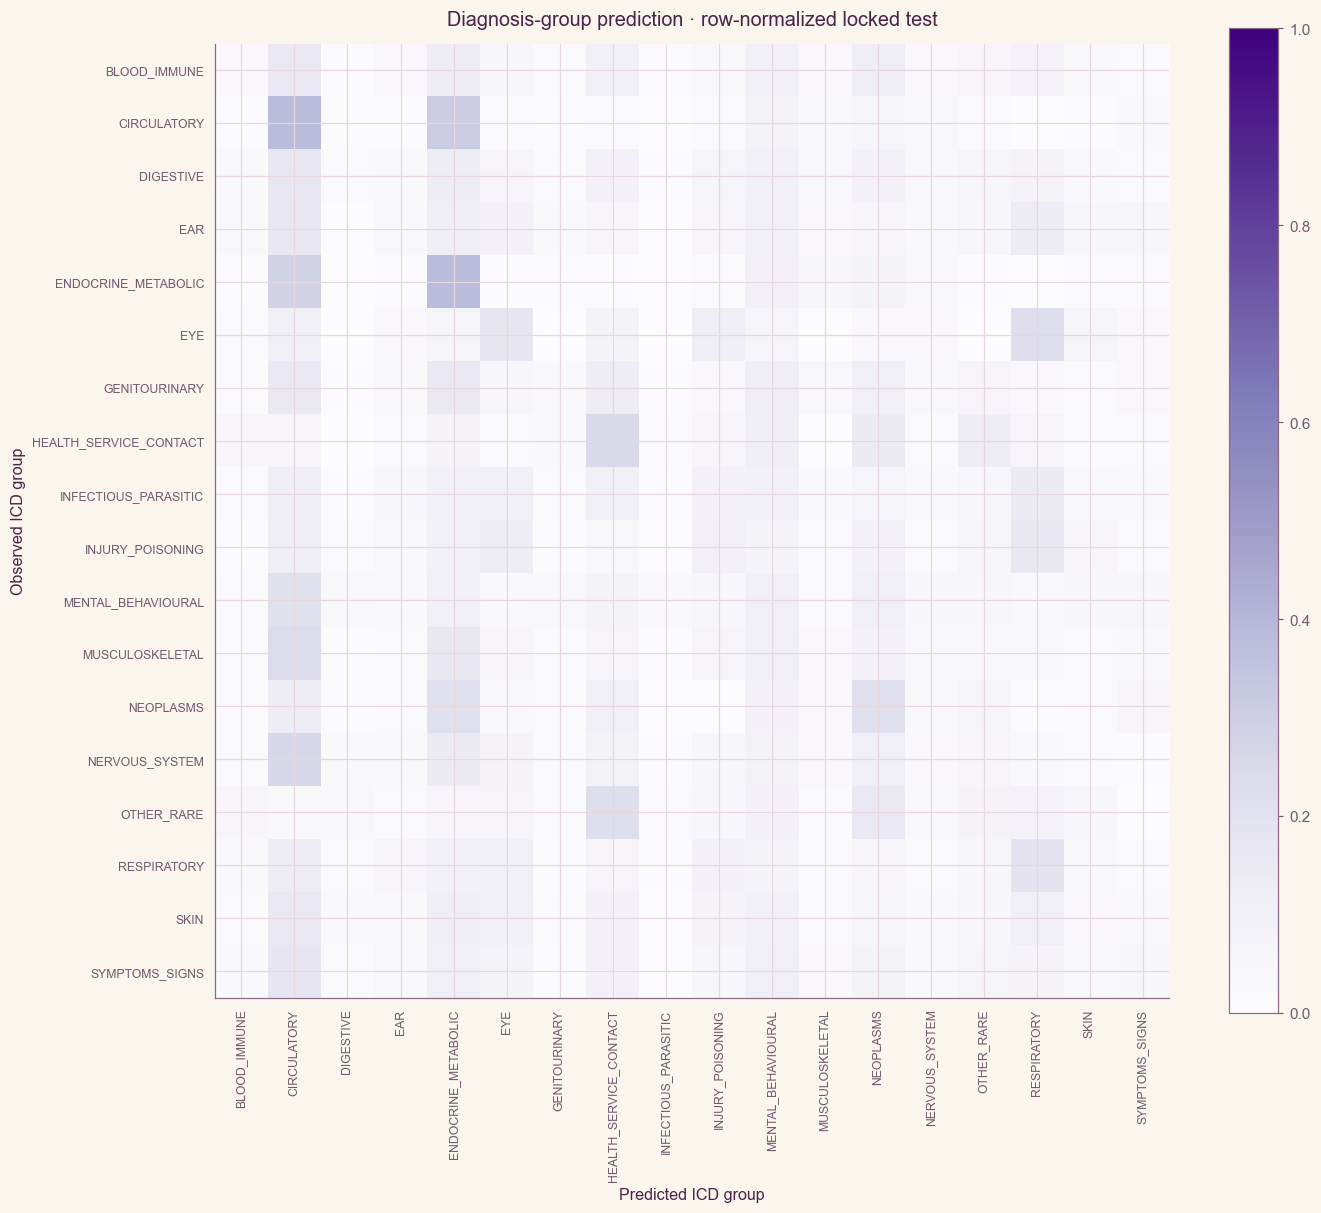

['C:\\Users\\nagat\\OneDrive\\Desktop\\final _project\\outputs\\modeling\\diagnosis_group_model.joblib']

In [123]:
dx_train=dx_parts['train'];class_counts=dx_train.diagnosis_group.value_counts()
# Rare-category mapping is learned exclusively from training, never future class frequencies.
known_classes=set(class_counts[class_counts.ge(100)].index)
def dx_target(d):return d.diagnosis_group.where(d.diagnosis_group.isin(known_classes),'OTHER_RARE')
dx_candidates={
 'most_frequent_baseline':prep(DummyClassifier(strategy='most_frequent')),
 'logistic':prep(LogisticRegression(C=.1,max_iter=2000,random_state=SEED),True),
 'balanced_forest':prep(RandomForestClassifier(n_estimators=140,max_depth=12,min_samples_leaf=20,class_weight='balanced_subsample',n_jobs=1,random_state=SEED))}
dx_cv=[]
for start in [pd.Timestamp('2019-10-01'),pd.Timestamp('2020-04-01'),pd.Timestamp('2020-08-01')]:
    year=str(start.date());stop=min(start+pd.DateOffset(months=4),pd.Timestamp(SPLITS['train_end']))
    a=dx_train.loc[dx_train.visit_date.lt(start-pd.Timedelta(days=30))];b=dx_train.loc[dx_train.visit_date.ge(start) & dx_train.visit_date.lt(stop)]
    fold_counts=a.diagnosis_group.value_counts();fold_known=set(fold_counts[fold_counts.ge(100)].index)
    ya=a.diagnosis_group.where(a.diagnosis_group.isin(fold_known),'OTHER_RARE');yb=b.diagnosis_group.where(b.diagnosis_group.isin(fold_known),'OTHER_RARE')
    for name,template in dx_candidates.items():
        m=clone(template).fit(a[FEATURES],ya);v=m.predict(b[FEATURES]);dx_cv.append({'model':name,'year':year,'macro_F1':f1_score(yb,v,average='macro',zero_division=0),'weighted_F1':f1_score(yb,v,average='weighted',zero_division=0),'accuracy':accuracy_score(yb,v)})
dx_cv=pd.DataFrame(dx_cv);dx_cv.to_csv(MODEL_OUT/'diagnosis_temporal_cv.csv',index=False)
dx_fitted={};dx_selection=[]
for name,template in dx_candidates.items():
    m=clone(template).fit(dx_train[FEATURES],dx_target(dx_train));dx_fitted[name]=m
    v=m.predict(dx_parts['selection'][FEATURES]);ys=dx_target(dx_parts['selection'])
    dx_selection.append({'model':name,'macro_F1':f1_score(ys,v,average='macro',zero_division=0),'weighted_F1':f1_score(ys,v,average='weighted',zero_division=0),'accuracy':accuracy_score(ys,v)})
dx_selection=pd.DataFrame(dx_selection).sort_values('macro_F1',ascending=False);dx_selection.to_csv(MODEL_OUT/'diagnosis_selection.csv',index=False);display(dx_selection)
dx_winner=dx_selection.iloc[0]['model'];dx_model=dx_fitted[dx_winner];dt=dx_parts['test'];dy=dx_target(dt);dp=dx_model.predict(dt[FEATURES])
dx_test=[]
for name,m in [(dx_winner,dx_model),('most_frequent_baseline',dx_fitted['most_frequent_baseline'])]:
    v=m.predict(dt[FEATURES]);dx_test.append({'model':name,'n':len(dt),'macro_F1':f1_score(dy,v,average='macro',zero_division=0),'weighted_F1':f1_score(dy,v,average='weighted',zero_division=0),'accuracy':accuracy_score(dy,v),'balanced_accuracy':balanced_accuracy_score(dy,v)})
dx_test=pd.DataFrame(dx_test);dx_test.to_csv(MODEL_OUT/'diagnosis_test_metrics.csv',index=False);display(dx_test)
dx_report=pd.DataFrame(classification_report(dy,dp,zero_division=0,output_dict=True)).T;dx_report.to_csv(MODEL_OUT/'diagnosis_class_report.csv');display(dx_report)
dx_pred=dt[['patient_id','visit_date','diagnosis_group']].copy();dx_pred['mapped_target']=dy;dx_pred['predicted_group']=dp;dx_pred.to_csv(MODEL_OUT/'diagnosis_test_predictions.csv',index=False)
classes=dx_model.classes_;cm=confusion_matrix(dy,dp,labels=classes,normalize='true')
fig,ax=plt.subplots(figsize=(13,11));im=ax.imshow(cm,cmap='Purples',vmin=0,vmax=1);ax.set(xticks=np.arange(len(classes)),yticks=np.arange(len(classes)),xticklabels=classes,yticklabels=classes,xlabel='Predicted ICD group',ylabel='Observed ICD group',title='Diagnosis-group prediction · row-normalized locked test');plt.setp(ax.get_xticklabels(),rotation=90,fontsize=8);plt.setp(ax.get_yticklabels(),fontsize=8);fig.colorbar(im,ax=ax);plt.tight_layout();fig.savefig(MODEL_OUT/'diagnosis_confusion.png',bbox_inches='tight');plt.show()
joblib.dump({'pipeline':dx_model,'features':FEATURES,'training_known_classes':sorted(known_classes),'rare_label':'OTHER_RARE','target':'current observed syntax-derived ICD chapter group','clinical_validity':'not established'},MODEL_OUT/'diagnosis_group_model.joblib')

<div id="additional-modeling-7" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Additional model verification and report</h2></div>

In [124]:
for fname,frame,expected in [('claim_amount_model.joblib',ct,cp),('diagnosis_group_model.joblib',dt,dp)]:
    b=joblib.load(MODEL_OUT/fname);v=b['pipeline'].predict(frame[FEATURES].head(20))
    if fname.startswith('claim'):assert np.allclose(np.maximum(0,v),expected[:20])
    else:assert np.array_equal(v,expected[:20])
assert not set(FEATURES)&{'total_claim','claim_total','diagnosis_group','icd10','diagnosis_text','disease_category'}
for parts in [cost_parts,dx_parts]:
    for a,b in zip(list(parts.values())[:-1],list(parts.values())[1:]):assert a.visit_date.max()+pd.Timedelta(days=30)<b.visit_date.min()
summary={'claim_model':cost_winner,'diagnosis_model':dx_winner,'cost_intervals':cost_interval,'diagnosis_train_class_counts':class_counts.to_dict(),'source_units':'unverified','all_predictors_available':'start of index day'}
(MODEL_OUT/'additional_manifest.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
_mae_model=float(cost_test.iloc[0].MAE);_mae_base=float(cost_test.loc[cost_test.model.eq('median_baseline')].iloc[0].MAE)
cost_verdict=('The selected cost model beats the median baseline on the locked test.' if _mae_model<_mae_base else 'The selected cost model does NOT beat the median baseline on the locked test; this result is retained, with no test-based reselection.')
report=f'''# Carelytics — all modeling targets

## 1. Observed 30-day return
See model_card.md for the full return model, validation design, subgroup analyses, uncertainty and limitations.

## 2. Daily claim amount
Target is the sum of the total_claim source field on the index patient-day, requiring all same-day amounts to be observed and nonnegative. Component fields are not assumed to sum to total_claim. Currency and semantics are unverified, so outputs are in source units. Features are available at the start of the index day; current claim fields and diagnoses are excluded. Three expanding temporal folds compare median baseline, log-target Ridge, random forest and histogram boosting. All candidates are trained only on the training period; separate selection data choose minimum MAE. Selected model: **{cost_winner}**. The frozen test is used for reporting only.

{cost_test.to_markdown(index=False)}

A separate 2023 calibration period estimates absolute-residual intervals with nominal 90% coverage. Actual test coverage is **{cost_interval['test_coverage']:.1%}**, with mean width **{cost_interval['mean_width']:.4f}** source units. Repeated patients and temporal drift invalidate an exchangeability guarantee; coverage is measured, not promised. Zero-value concentration and outliers are reported rather than hidden. {cost_verdict} Totals reported as zero while components were positive were rebuilt from the components upstream (flag total_claim_rebuilt); the target distribution by period is printed in the two-stage section. Negative R² is retained when present. No operational billing forecast is claimed.

## 3. Observed ICD chapter grouping
The target is the current-day syntax-derived ICD chapter grouping, not a clinically validated diagnosis. Same-day different chapters are MULTIPLE_CHAPTERS. Unknown, unmapped or malformed code groups are excluded. Current ICD codes, diagnosis text and disease labels never enter the predictors. Targets with fewer than 100 training observations are mapped to OTHER_RARE, using training data only (within each temporal fold for CV). Three expanding temporal folds starting October 2019, April 2020 and August 2020 compare a majority baseline, logistic regression and balanced random forest. Separate selection data choose maximum macro F1, so minority classes influence selection. Selected model: **{dx_winner}**.

{dx_test.to_markdown(index=False)}

Full per-class precision, recall, F1 and support are saved in diagnosis_class_report.csv. Some groups may have zero recall. These failures remain visible. Predicted group labels are research outputs, not diagnoses or recommended treatments. Probability calibration is not claimed for this multiclass model.

## Shared methodology and limitations
See additional_split_summary.csv for exact target-specific sample counts. Costs and diagnosis labels do not require a future return window, so they use their own eligible cohorts. Only reliable identified dates enter these datasets. Same patients may recur over time to represent longitudinal use; patient IDs are never features. Missing current ages are imputed inside training pipelines; original contemporaneous demographics avoid future-derived conflict flags. History is strictly before the index day and left-truncated by source coverage. Models omit current billing/diagnosis fields whose availability is uncertain. No test-period result is used for model selection. Patterns can reflect billing practices, incomplete capture and changing coverage rather than patient biology. External/prospective validation, semantic verification and clinical utility review are required before real use.

The return model includes patient-cluster intervals and descriptive demographic subgroup metrics. Equivalent fairness and uncertainty validation for every additional target has not been established. Claim intervals are descriptive under temporal dependence, and diagnosis metrics do not establish clinical accuracy. Serialized models have been reloaded and prediction equivalence verified. Source files and the original descriptive analysis are preserved.

Method reference: https://scikit-learn.org/stable/common_pitfalls.html
'''
(MODEL_OUT/'all_targets_report.md').write_text(report,encoding='utf-8')
print('Completed all three targets. Additional model serialization and leakage checks passed.')

Completed all three targets. Additional model serialization and leakage checks passed.


<div id="modeling-scorecard" style="padding:22px;background:#f2e6d7;color:#4a2548;border-top:1px solid #896b86"><h2 style="font:28px Georgia;margin:0">Modeling · Scorecard against simple baselines</h2></div>

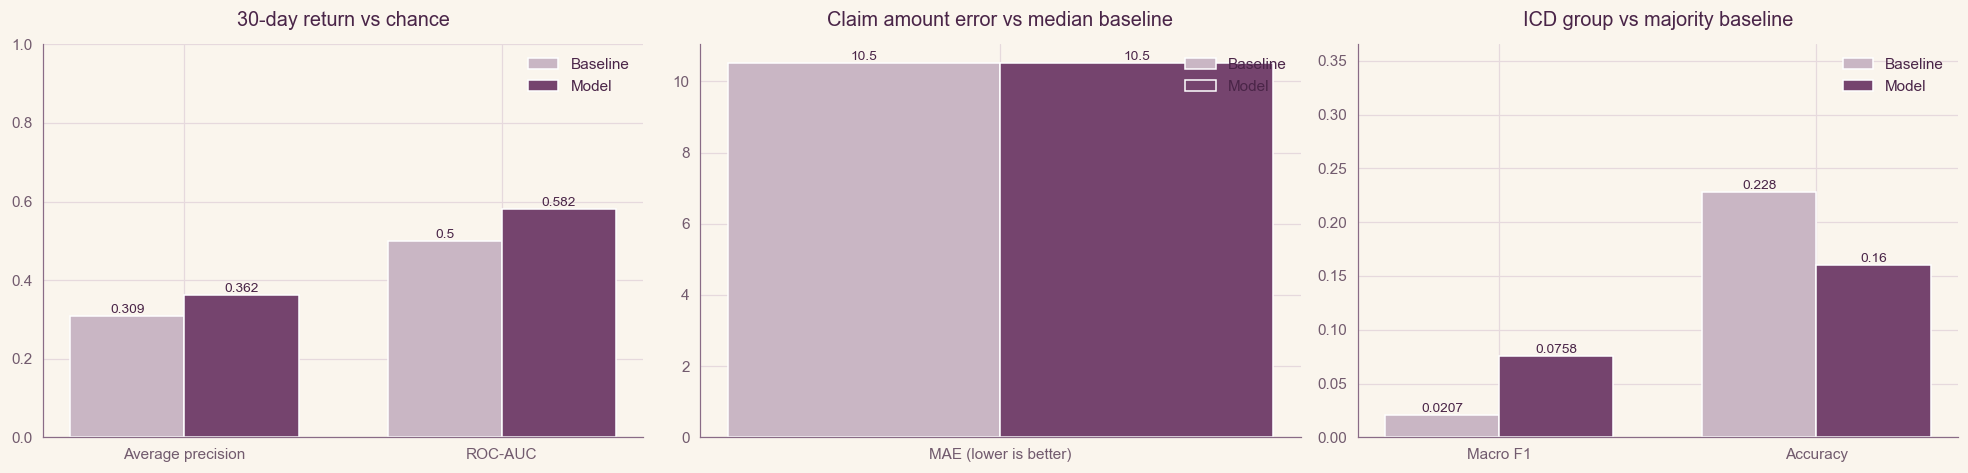

In [125]:
# Model scorecard: reads the saved test metrics so these numbers always match the files on disk.
def _load(name):
    path = MODEL_OUT / name
    return pd.read_csv(path) if path.exists() else None

ret, cst, dxm = _load('test_metrics.csv'), _load('cost_test_metrics.csv'), _load('diagnosis_test_metrics.csv')
absent = [n for n, v in [('test_metrics.csv', ret), ('cost_test_metrics.csv', cst), ('diagnosis_test_metrics.csv', dxm)] if v is None]
if absent:
    cl_takeaways('Scorecard unavailable', [f'Missing files: {", ".join(absent)}. Run the three modeling sections above first.'])
else:
    BADGE = {'good': (CL['lime'], CL['plum']), 'mixed': ('#f0e2a8', CL['plum']), 'poor': ('#ecc9d0', CL['plum'])}
    # 1) observed 30-day return
    r_base = ret.loc[ret.model.eq('flag_everyone_baseline')].iloc[0]
    r_mod = ret.loc[ret.model.str.endswith('_calibrated')].iloc[0]
    auc, ap, prev = float(r_mod.ROC_AUC), float(r_mod.AP), float(r_mod.prevalence)
    r_tone, r_text = ('poor', 'Limited signal') if auc < .6 else (('mixed', 'Modest signal') if auc < .7 else ('good', 'Useful signal'))
    # 2) daily claim amount
    c_mod = cst.iloc[0]; c_base = cst.loc[cst.model.eq('median_baseline')].iloc[0]
    c_gain = 1 - float(c_mod.MAE) / float(c_base.MAE)
    c_tone, c_text = ('poor', 'Worse than baseline') if c_gain < 0 else (('mixed', 'Marginal gain') if c_gain < .05 else ('good', 'Better than baseline'))
    # 3) diagnosis group
    d_mod = dxm.iloc[0]; d_base = dxm.loc[dxm.model.eq('most_frequent_baseline')].iloc[0]
    f1_better, acc_better = d_mod.macro_F1 > d_base.macro_F1, d_mod.accuracy > d_base.accuracy
    d_tone, d_text = ('good', 'Better than baseline') if (f1_better and acc_better) else (('mixed', 'Mixed result') if f1_better else ('poor', 'Worse than baseline'))

    def card(title, headline, sub, lines, tone, verdict):
        bg, fg = BADGE[tone]
        body = ''.join('<div style="margin:3px 0">%s</div>' % _h.escape(x) for x in lines)
        return ('<div style="background:%s;border:1px solid %s;border-top:3px solid %s;border-radius:5px;padding:18px 20px">'
                '<div style="font:10px Arial;letter-spacing:2px;text-transform:uppercase;color:%s">%s</div>'
                '<div style="font:34px/1.2 Georgia,serif;color:%s;margin:8px 0 0">%s</div>'
                '<div style="font:12px Arial;color:%s;margin-bottom:10px">%s</div>'
                '<div style="font:13px/1.55 Arial;color:#51434d">%s</div>'
                '<span style="display:inline-block;margin-top:12px;padding:4px 12px;border-radius:999px;background:%s;color:%s;font:bold 12px Arial">%s</span></div>'
                % (CL['sand'], CL['line'], CL['mauve'], CL['dusk'], title, CL['plum'], headline, CL['muted'], sub, body, bg, fg, verdict))

    cards = ''.join([
        card('Observed 30-day return', f'AUC {auc:.3f}', 'ROC-AUC, locked test period',
             [f'Average precision {ap:.3f} vs prevalence {prev:.3f} (lift ×{ap / prev:.2f})',
              f'Precision {float(r_mod.precision):.2f} · recall {float(r_mod.recall):.2f} at the frozen threshold (flags {float(r_mod.flagged_fraction):.0%}, lift ×{float(r_mod.lift):.2f})'], r_tone, r_text),
        card('Daily claim amount', f'MAE {float(c_mod.MAE):,.2f}', 'source units, locked test period',
             [f'Median baseline MAE {float(c_base.MAE):,.2f} ({c_gain:+.0%} change)', f'R² {float(c_mod.R2):.3f} · selected model: {c_mod.model}'], c_tone, c_text),
        card('ICD group prediction', f'F1 {float(d_mod.macro_F1):.3f}', 'macro F1, locked test period',
             [f'Majority baseline macro F1 {float(d_base.macro_F1):.3f}', f'Accuracy {float(d_mod.accuracy):.1%} vs baseline {float(d_base.accuracy):.1%}'], d_tone, d_text)])
    display(HTML('<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(260px,1fr));gap:12px;margin:8px 0">%s</div>' % cards))

    fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
    def pair(a, labels, base, model, title, ylim=None):
        x = np.arange(len(labels)); w = .36
        a.bar(x - w / 2, base, w, color='#c9b6c4', label='Baseline'); a.bar(x + w / 2, model, w, color=CL['mauve'], label='Model')
        for i in range(len(labels)):
            a.text(x[i] - w / 2, base[i], f'{base[i]:.3g}', ha='center', va='bottom', fontsize=9)
            a.text(x[i] + w / 2, model[i], f'{model[i]:.3g}', ha='center', va='bottom', fontsize=9)
        a.set_xticks(x); a.set_xticklabels(labels); a.set_title(title); a.legend()
        if ylim: a.set_ylim(*ylim)
    pair(ax[0], ['Average precision', 'ROC-AUC'], [prev, .5], [ap, auc], '30-day return vs chance', (0, 1))
    pair(ax[1], ['MAE (lower is better)'], [float(c_base.MAE)], [float(c_mod.MAE)], 'Claim amount error vs median baseline')
    pair(ax[2], ['Macro F1', 'Accuracy'], [float(d_base.macro_F1), float(d_base.accuracy)], [float(d_mod.macro_F1), float(d_mod.accuracy)], 'ICD group vs majority baseline', (0, max(.3, float(d_base.accuracy) * 1.6)))
    plt.tight_layout(); plt.show()
    cl_note('Verdict labels are rules of thumb (return: AUC below 0.60 limited, 0.60–0.70 modest, 0.70 and above useful; claim and diagnosis: comparison with the simple baseline). They are not clinical or operational acceptance criteria.')
    _sg = _load('subgroup_metrics.csv')
    _within = float(_sg.loc[_sg.dimension.eq('age_band'), 'ROC_AUC'].mean()) if (_sg is not None and (_sg.dimension == 'age_band').any()) else float('nan')
    _items = ['All three models are research benchmarks evaluated on a locked, later time period with no test-based reselection.',
              f'Return model: F1 {float(r_mod.F1):.3f} versus {float(r_base.F1):.3f} for simply flagging everyone; ROC-AUC averages {_within:.2f} inside age bands (0.50 = no ranking within a band)' + (', so most of the pooled AUC comes from age differences rather than visit history.' if (_within - .5) < .5 * (auc - .5) else '.'),
              f'Claim amount: MAE {float(c_mod.MAE):,.2f} against {float(c_base.MAE):,.2f} for the median baseline ({c_gain:+.0%}).',
              f'ICD group: macro F1 {float(d_mod.macro_F1):.3f} against {float(d_base.macro_F1):.3f} for the majority baseline; accuracy {float(d_mod.accuracy):.1%} against {float(d_base.accuracy):.1%}.',
              'None is validated for operational or clinical use. Model cards and all_targets_report.md list the limits in full.']
    cl_takeaways('Overall readiness', _items)


<div id="ext-setup" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Extended ML · Shared setup</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial">Eight extra analyses built on the same cleaned data (<code>df</code>, <code>episodes</code>). They are research tools: segmentation, high-cost detection, anomaly review, a two-stage cost model, time-to-return survival, comorbidity patterns, next-diagnosis sequences and volume forecasting. Run this setup cell first; every section below reuses it.</div>

In [150]:
# Extended ML: shared imports and a patient-level table built only from the analysis dataset `df`.
import warnings
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, average_precision_score, roc_auc_score, mean_absolute_error,
                             mean_squared_error, r2_score, f1_score, accuracy_score)
warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
EXT_OUT = MODEL_OUT.parent / 'extended_ml'
EXT_OUT.mkdir(parents=True, exist_ok=True)
INVALID_DX = {'UNKNOWN', 'UNMAPPED', 'NAN', 'NONE', ''}
comp_cols = [c for c in ['drugs_amount', 'investigation_amount', 'outpatient_amount', 'inpatient_amount', 'service_amount'] if c in df.columns]

# One row per patient (retrospective summary of everything observed).
pt = df.groupby('patient_id').agg(
    claims=('total_claim', 'size'), visit_days=('visit_date', 'nunique'),
    total_cost=('total_claim', 'sum'), mean_claim=('total_claim', 'mean'),
    age=('age', 'median'), mean_los=('length_of_stay', 'mean'),
    n_chapters=('disease_category', 'nunique'))
pt['mean_los'] = pt.mean_los.fillna(0)
pt['age'] = pt.age.fillna(pt.age.median())
pt['female'] = df.assign(f=df.gender.eq('F')).groupby('patient_id').f.max().astype(int)
print(f'{len(pt):,} patients · {len(df):,} claim rows · outputs go to {EXT_OUT}')

35,808 patients · 78,026 claim rows · outputs go to C:\Users\nagat\OneDrive\Desktop\final _project\outputs\extended_ml


<div id="ext-segmentation" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Patient Segmentation (Clustering)</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Question:</b> are there natural groups of patients by how often they come, how much they cost and how complex their diagnoses are? K-Means on log-scaled patient features; k is chosen by silhouette score. Segments are descriptive, not clinical categories.</div>

,patients,median_claims,median_visit_days,median_total_cost,median_age,mean_los,median_chapters,patients_pct,cost_share_pct
segment,,,,,,,,,
S1,27288,1.0,1.0,19.44,34.0,0.00,1.0,76.21,37.53
S2,8273,4.0,4.0,87.42,55.0,0.01,3.0,23.1,59.7
S3,247,1.0,1.0,164.24,43.0,2.73,1.0,0.69,2.77


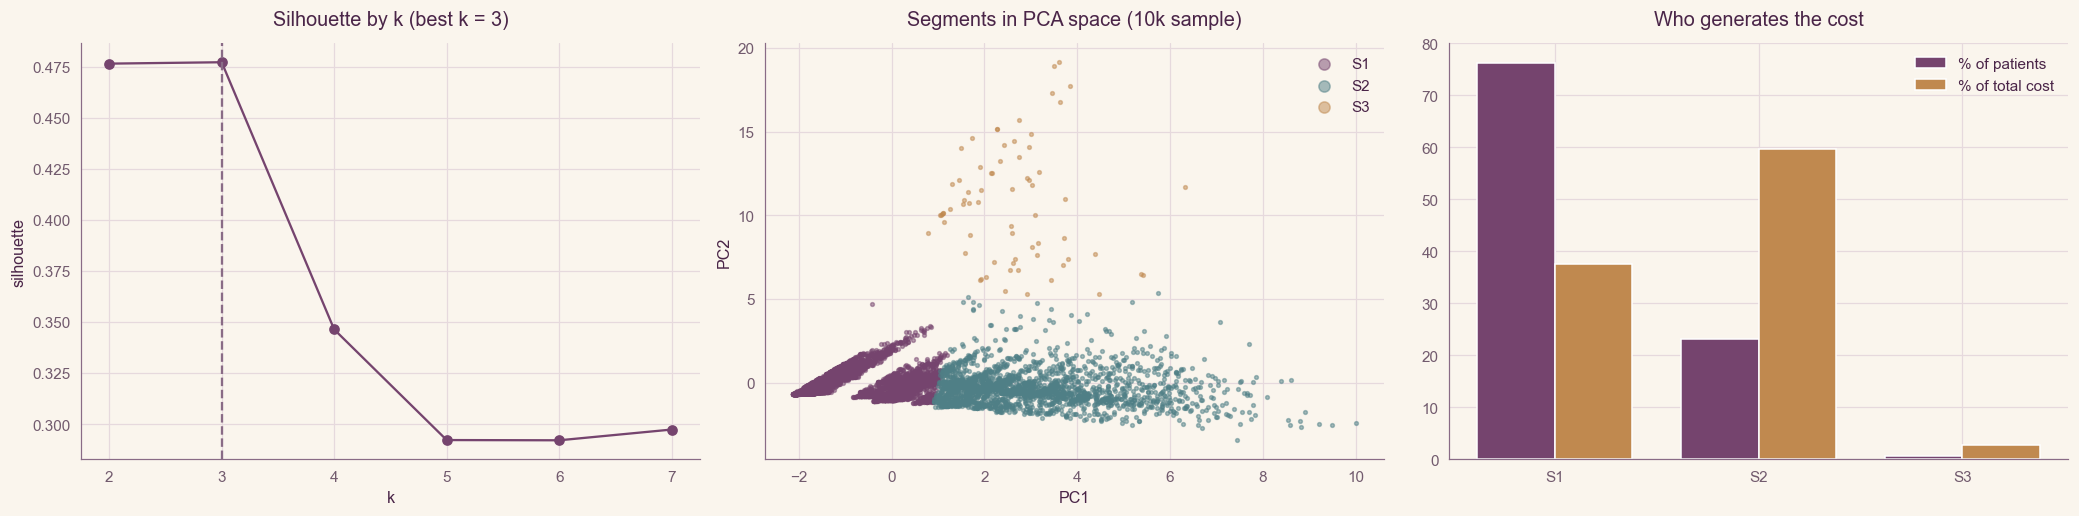

Best k = 3 (silhouette 0.48). Segment S2 holds 23.1% of patients and 59.7% of total cost.


In [127]:
seg_feats = ['claims', 'visit_days', 'total_cost', 'mean_claim', 'age', 'mean_los', 'n_chapters']
X = pt[seg_feats].astype(float).copy()
for c in ['claims', 'visit_days', 'total_cost', 'mean_claim', 'mean_los']:
    X[c] = np.log1p(X[c])
Xs = StandardScaler().fit_transform(X)

rng = np.random.RandomState(SEED)
sample = rng.choice(len(Xs), min(10000, len(Xs)), replace=False)
sil = {}
for k in range(2, 8):
    labels_k = KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs)
    sil[k] = silhouette_score(Xs[sample], labels_k[sample])
best_k = max(sil, key=sil.get)
km = KMeans(best_k, n_init=10, random_state=SEED).fit(Xs)

# Name segments S1..Sk by median total cost (S1 = cheapest).
pt['segment_raw'] = km.labels_
order = pt.groupby('segment_raw').total_cost.median().sort_values().index
pt['segment'] = pt.segment_raw.map({old: f'S{i + 1}' for i, old in enumerate(order)})

profile = pt.groupby('segment').agg(
    patients=('claims', 'size'), median_claims=('claims', 'median'), median_visit_days=('visit_days', 'median'),
    median_total_cost=('total_cost', 'median'), median_age=('age', 'median'),
    mean_los=('mean_los', 'mean'), median_chapters=('n_chapters', 'median'), cost_sum=('total_cost', 'sum'))
profile['patients_pct'] = profile.patients / profile.patients.sum() * 100
profile['cost_share_pct'] = profile.cost_sum / profile.cost_sum.sum() * 100
profile = profile.drop(columns='cost_sum')
display(profile.round(2))
profile.to_csv(EXT_OUT / 'segment_profile.csv')
pt[['segment']].to_csv(EXT_OUT / 'patient_segments.csv')

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].plot(list(sil), list(sil.values()), marker='o', color=CL['mauve'])
ax[0].axvline(best_k, ls='--', color=CL['dusk']); ax[0].set(title=f'Silhouette by k (best k = {best_k})', xlabel='k', ylabel='silhouette')
p2 = PCA(2, random_state=SEED).fit_transform(Xs[sample])
segs = pt.segment.to_numpy()[sample]
for i, s in enumerate(sorted(pt.segment.unique())):
    m = segs == s
    ax[1].scatter(p2[m, 0], p2[m, 1], s=6, alpha=.5, color=CL_CYCLE[i % len(CL_CYCLE)], label=s)
ax[1].set(title='Segments in PCA space (10k sample)', xlabel='PC1', ylabel='PC2'); ax[1].legend(markerscale=3)
w = .38; xs = np.arange(len(profile))
ax[2].bar(xs - w / 2, profile.patients_pct, w, color=CL['mauve'], label='% of patients')
ax[2].bar(xs + w / 2, profile.cost_share_pct, w, color=CL['amber'], label='% of total cost')
ax[2].set_xticks(xs); ax[2].set_xticklabels(profile.index); ax[2].set_title('Who generates the cost'); ax[2].legend()
plt.tight_layout(); plt.show()

top = profile.cost_share_pct.idxmax()
print(f'Best k = {best_k} (silhouette {sil[best_k]:.2f}). Segment {top} holds {profile.patients_pct[top]:.1f}% of patients '
      f'and {profile.cost_share_pct[top]:.1f}% of total cost.')

<div id="ext-highcost" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">High-Cost Patient Detection</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Question:</b> using only history up to a cut-off date, which patients will be top-decile spenders over the next 365 days? "High-cost" means next-year spend at or above the 90th percentile of spenders in the training snapshot, so it is well under 10% of all patients (most patients have no later spend at all). Two point-in-time snapshots: train on the earlier one, test on the later one, so no future information leaks into the features.</div>

Train snapshot 2023-09-01 · 23,360 patients · positives 0.7% | Test snapshot 2024-08-31 · 30,335 patients · positives 1.1% | cost threshold 138.5


,AP,ROC_AUC,precision_top10pct,lift_top10pct,future_cost_captured_pct
model,,,,,
prevalence_baseline,0.011,0.500,0.011,0.959,9.998
last_year_cost_rule,0.316,0.921,0.091,8.051,60.553
logistic,0.309,0.957,0.100,8.836,64.740
boosting,0.356,0.960,0.100,8.807,64.267


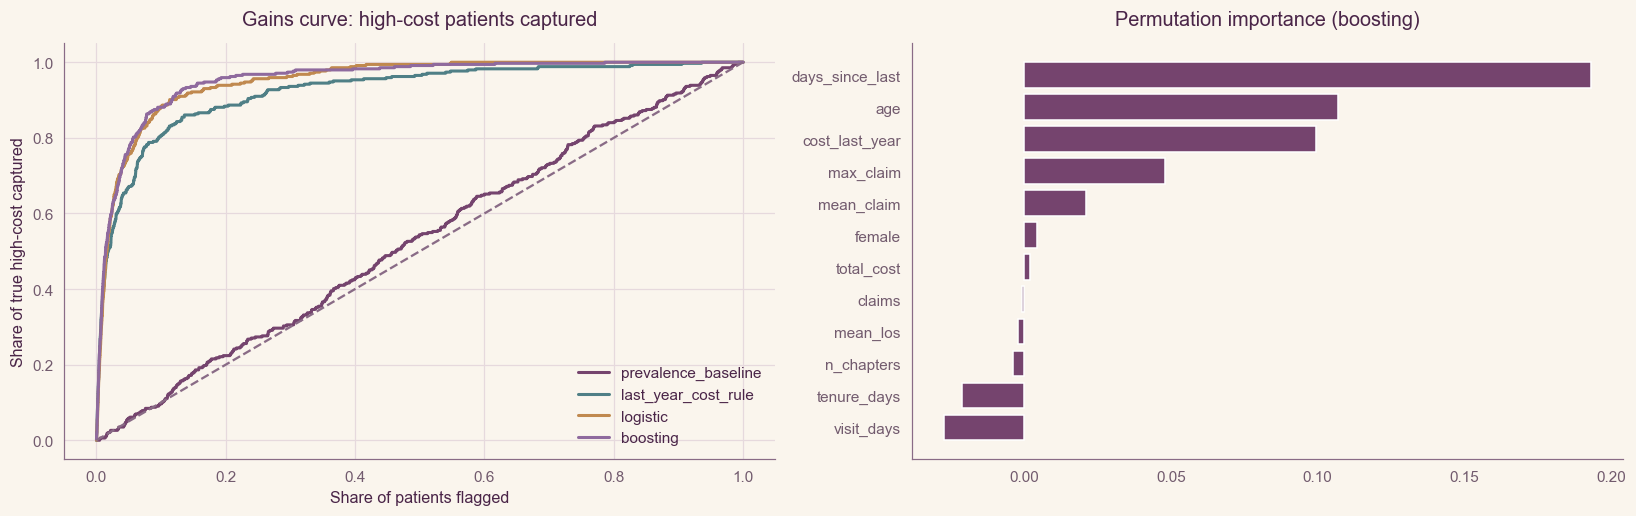

boosting: flagging the top 10% captures 64.3% of next-year cost (lift 8.8x; AP 0.356 vs prevalence 0.011). Research benchmark, not a decision tool.
Simple rule 'rank by last-year cost' captures 60.6% of next-year cost (AP 0.316); the model's added value is the gap to this rule.


In [128]:
HORIZON = pd.Timedelta(days=365)
t_end = df.visit_date.max().normalize()
T2 = t_end - HORIZON          # test snapshot
T1 = T2 - HORIZON             # train snapshot (its labels mature exactly at T2)
LOG_COLS = ['claims', 'visit_days', 'total_cost', 'mean_claim', 'max_claim', 'cost_last_year']
female_map = pt.female

def snapshot(T):
    hist = df[df.visit_date < T]
    fut = df[(df.visit_date >= T) & (df.visit_date < T + HORIZON)]
    g = hist.groupby('patient_id')
    X = g.agg(claims=('total_claim', 'size'), visit_days=('visit_date', 'nunique'), total_cost=('total_claim', 'sum'),
              mean_claim=('total_claim', 'mean'), max_claim=('total_claim', 'max'), age=('age', 'median'),
              mean_los=('length_of_stay', 'mean'), n_chapters=('disease_category', 'nunique'),
              last_visit=('visit_date', 'max'), first_visit=('visit_date', 'min'))
    X['days_since_last'] = (T - X.last_visit).dt.days
    X['tenure_days'] = (T - X.first_visit).dt.days
    recent = hist[hist.visit_date >= T - HORIZON].groupby('patient_id').total_claim.sum()
    X['cost_last_year'] = recent.reindex(X.index).fillna(0)
    X['female'] = female_map.reindex(X.index)
    X['mean_los'] = X.mean_los.fillna(0)
    X = X.drop(columns=['last_visit', 'first_visit'])
    for c in LOG_COLS:
        X[c] = np.log1p(X[c].astype(float))
    y_cost = fut.groupby('patient_id').total_claim.sum().reindex(X.index).fillna(0)
    return X, y_cost

Xtr, ctr = snapshot(T1)
Xte, cte = snapshot(T2)
thr = ctr[ctr > 0].quantile(.90)                       # threshold learned on the training snapshot only
ytr = ((ctr >= thr) & (ctr > 0)).astype(int)
yte = ((cte >= thr) & (cte > 0)).astype(int)
assert ytr.nunique() == 2 and yte.nunique() == 2, 'Not enough positives in one of the snapshots.'
print(f'Train snapshot {T1.date()} · {len(Xtr):,} patients · positives {ytr.mean():.1%} | '
      f'Test snapshot {T2.date()} · {len(Xte):,} patients · positives {yte.mean():.1%} | cost threshold {thr:,.1f}')

class _RuleScore:
    """Transparent baseline: rank patients by one feature (no learning)."""
    def __init__(self, col): self.col = col
    def fit(self, X, y): return self
    def predict_proba(self, X):
        s_ = X[self.col].to_numpy(float); s_ = (s_ - s_.min()) / (np.ptp(s_) + 1e-9)
        return np.column_stack([1 - s_, s_])

models = {
    'prevalence_baseline': DummyClassifier(strategy='prior'),
    'last_year_cost_rule': _RuleScore('cost_last_year'),
    'logistic': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=.5, max_iter=2000)),
    'boosting': HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, learning_rate=.06, l2_regularization=5, random_state=SEED)}
rows, scores = [], {}
top_n = int(np.ceil(.10 * len(Xte)))
for name, m in models.items():
    m.fit(Xtr, ytr)
    s = m.predict_proba(Xte)[:, 1]
    scores[name] = s
    flagged = np.argsort(-s, kind='stable')[:top_n]
    prec = yte.to_numpy()[flagged].mean()
    rows.append({'model': name, 'AP': average_precision_score(yte, s), 'ROC_AUC': roc_auc_score(yte, s),
                 'precision_top10pct': prec, 'lift_top10pct': prec / yte.mean(),
                 'future_cost_captured_pct': cte.to_numpy()[flagged].sum() / cte.sum() * 100})
hc = pd.DataFrame(rows).set_index('model')
display(hc.round(3))
hc.to_csv(EXT_OUT / 'high_cost_metrics.csv')

best_name = hc.loc[['logistic', 'boosting']].AP.idxmax()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for i, (name, s) in enumerate(scores.items()):
    o = np.argsort(-s, kind='stable')
    gain = np.cumsum(yte.to_numpy()[o]) / yte.sum()
    ax[0].plot(np.arange(1, len(o) + 1) / len(o), gain, label=name, color=CL_CYCLE[i], lw=2)
ax[0].plot([0, 1], [0, 1], ls='--', color=CL['dusk']); ax[0].set(title='Gains curve: high-cost patients captured', xlabel='Share of patients flagged', ylabel='Share of true high-cost captured'); ax[0].legend()
from sklearn.inspection import permutation_importance
sub = Xte.sample(min(4000, len(Xte)), random_state=SEED)
imp = permutation_importance(models[best_name], sub, yte.loc[sub.index], scoring='average_precision', n_repeats=5, random_state=SEED)
imp = pd.Series(imp.importances_mean, index=Xte.columns).sort_values()
ax[1].barh(imp.index, imp.values, color=CL['mauve']); ax[1].set_title(f'Permutation importance ({best_name})'); ax[1].grid(False)
plt.tight_layout(); plt.show()
print(f"{best_name}: flagging the top 10% captures {hc.loc[best_name,'future_cost_captured_pct']:.1f}% of next-year cost "
      f"(lift {hc.loc[best_name,'lift_top10pct']:.1f}x; AP {hc.loc[best_name,'AP']:.3f} vs prevalence {yte.mean():.3f}). Research benchmark, not a decision tool.")
print(f"Simple rule 'rank by last-year cost' captures {hc.loc['last_year_cost_rule','future_cost_captured_pct']:.1f}% of next-year cost (AP {hc.loc['last_year_cost_rule','AP']:.3f}); the model's added value is the gap to this rule.")


<div id="ext-anomaly" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Anomaly Detection (Claims for Review)</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Question:</b> which claims look unusual compared with similar claims? Isolation Forest on log amount, cost mix, stay length, age and the amount relative to the claim's own diagnosis group. A flag means <b>worth reviewing</b>, not fraud or error.</div>

,claims,flagged,median_claim,flag_rate_pct
disease_category,,,,
ENDOCRINE_METABOLIC,6094,123,21.9,2.02
CIRCULATORY,20295,329,19.44,1.62
BLOOD_IMMUNE,2250,36,19.44,1.60
INFECTIOUS_PARASITIC,10653,119,19.44,1.12
RESPIRATORY,8299,61,19.44,0.74
SYMPTOMS_SIGNS,1613,9,19.44,0.56
DIGESTIVE,5248,27,19.44,0.51
GENITOURINARY,4786,23,19.44,0.48
NERVOUS_SYSTEM,2028,9,19.44,0.44


,source_row_id,patient_id,visit_date,disease_category,total_claim,length_of_stay,age,claim_z,anomaly_score
75494,108924,f740b341549ec3ee,2022-08-06,CIRCULATORY,348.72,6.0,96.0,7.48,0.790
67226,125713,dc53b6685ca06f8a,2023-01-05,INFECTIOUS_PARASITIC,308.2,5.0,1.0,8.94,0.776
68643,60958,e05805464b1c8e56,2020-11-05,GENITOURINARY,136.92,4.0,94.0,5.93,0.776
75409,132859,f6fe1e867d1f9cef,2022-10-02,RESPIRATORY,308.66,6.0,8.0,7.98,0.772
72919,42268,eecce26526181c7b,2020-12-10,INFECTIOUS_PARASITIC,256.14,4.0,2.0,8.33,0.772
23865,187316,4dafc1b23b0d41bf,2023-01-01,INJURY_POISONING,390.62,5.0,81.0,9.17,0.772
24043,199721,4e3a635e71e87c04,2022-07-05,GENITOURINARY,186.1,8.0,0.0,6.88,0.771
28217,171099,5c4eec9f3b549123,2022-10-21,CIRCULATORY,341.34,5.0,84.0,7.42,0.771
51775,60930,a9eb75c8af5ac20c,2020-07-26,ENDOCRINE_METABOLIC,302.14,5.0,88.0,4.34,0.771
47972,193810,9d72901b30e87d53,2022-05-20,INFECTIOUS_PARASITIC,232.92,4.0,78.0,8.02,0.770


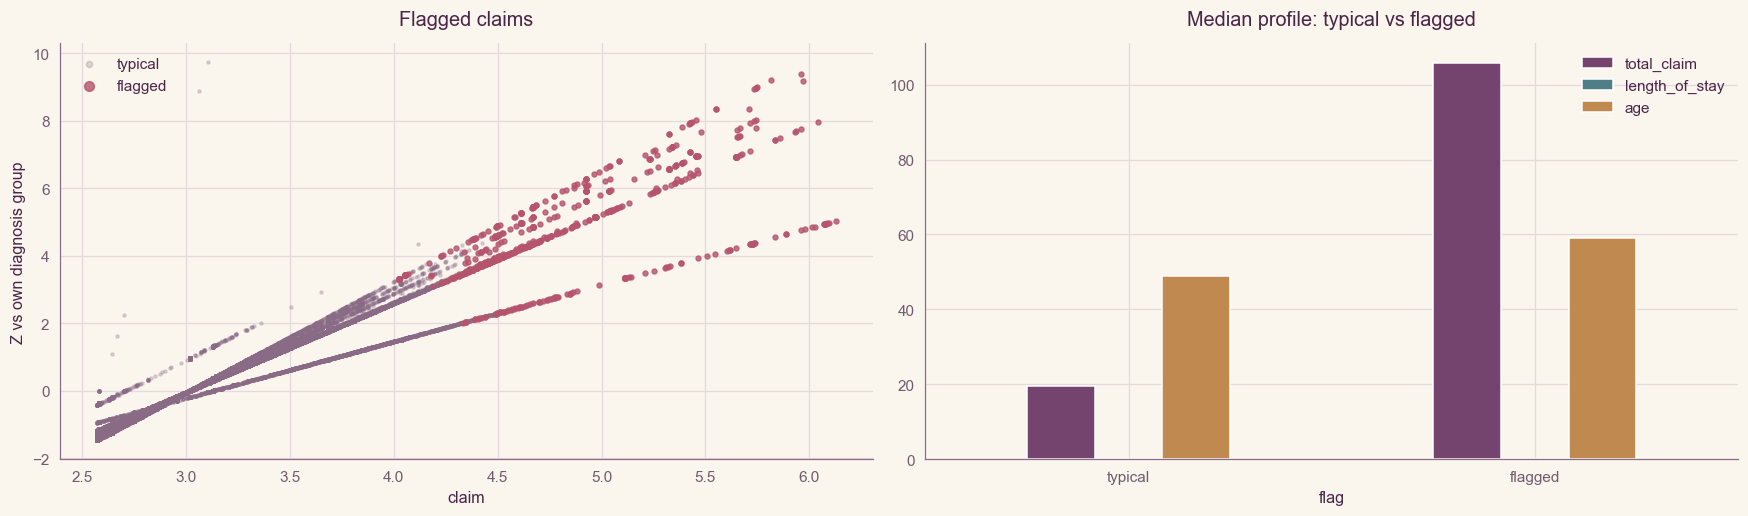

781 of 78,026 paid claims are in the top-1% review list. Saved the ranked list to claims_for_review.csv. Unsupervised: confirm with the data owner before treating any flag as an error.


In [131]:
a = df[df.total_claim > 0].copy()
a['log_claim'] = np.log1p(a.total_claim.astype(float))
grp = a.groupby('disease_category').log_claim
med, q1, q3 = grp.median(), grp.quantile(.25), grp.quantile(.75)
robust_sd = (q3 - q1) / 1.349
_global_sd = float((a.log_claim.quantile(.75) - a.log_claim.quantile(.25)) / 1.349) or float(a.log_claim.std())
robust_sd = robust_sd.where(robust_sd > 0.05, max(_global_sd, 0.05))   # constant-fee groups would otherwise give absurd z-scores
a['claim_z'] = (a.log_claim - a.disease_category.map(med)) / a.disease_category.map(robust_sd)
share_cols = []
for c in comp_cols:
    a[c + '_share'] = a[c].astype(float) / a.total_claim.astype(float)
    share_cols.append(c + '_share')
a['log_los'] = np.log1p(a.length_of_stay.fillna(0).astype(float))
a['age_f'] = a.age.fillna(a.age.median())
a_feats = ['log_claim', 'claim_z', 'log_los', 'age_f'] + share_cols
Z = StandardScaler().fit_transform(a[a_feats].fillna(0))
iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Z)
a['anomaly_score'] = -iso.score_samples(Z)          # higher = more unusual
REVIEW_RATE = 0.01   # review budget: the top 1% of claims by anomaly score (a ranking, not a detection threshold)
a['flag'] = a.anomaly_score >= a.anomaly_score.quantile(1 - REVIEW_RATE)

by_dx = (a.groupby('disease_category').agg(claims=('flag', 'size'), flagged=('flag', 'sum'), median_claim=('total_claim', 'median'))
         .assign(flag_rate_pct=lambda t: t.flagged / t.claims * 100).sort_values('flag_rate_pct', ascending=False))
display(by_dx.head(10).round(2))
review_cols = [c for c in ['source_row_id', 'patient_id', 'visit_date', 'disease_category', 'total_claim', 'length_of_stay', 'age', 'claim_z', 'anomaly_score'] if c in a.columns]
review = a.loc[a.flag, review_cols].sort_values('anomaly_score', ascending=False)
display(review.head(20).round({'total_claim': 2, 'claim_z': 2, 'anomaly_score': 3}))
review.to_csv(EXT_OUT / 'claims_for_review.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
ax[0].scatter(a.loc[~a.flag, 'log_claim'], a.loc[~a.flag, 'claim_z'], s=4, alpha=.25, color=CL['dusk'], label='typical')
ax[0].scatter(a.loc[a.flag, 'log_claim'], a.loc[a.flag, 'claim_z'], s=10, alpha=.8, color=CL['rose'], label='flagged')
ax[0].set(title='Flagged claims', xlabel='claim', ylabel='Z vs own diagnosis group'); ax[0].legend(markerscale=2)
cmp_ = a.groupby('flag')[['total_claim', 'length_of_stay', 'age']].median().rename(index={False: 'typical', True: 'flagged'})
cmp_.plot(kind='bar', ax=ax[1], color=[CL['mauve'], CL['teal'], CL['amber']]); ax[1].set_title('Median profile: typical vs flagged'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
n_flagged, n_paid_claims = int(a.flag.sum()), len(a)
print(f'{n_flagged:,} of {n_paid_claims:,} paid claims are in the top-{REVIEW_RATE:.0%} review list. Saved the ranked list to claims_for_review.csv. '
      'Unsupervised: confirm with the data owner before treating any flag as an error.')

<div id="ext-twostage" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Two-Stage Claim Cost Model (Hurdle)</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Why:</b> a single cost regressor can fail when the target changes meaning between periods (for example, totals recorded as zero). Here we first diagnose the target by period, then split the problem: (1) will the patient-day claim be above zero? (2) if yes, how large? Needs the objects from the modeling section (<code>cost_parts</code>, <code>FEATURES</code>, <code>prep</code>).</div>

Target distribution by period. A shift here, or one value repeating everywhere, explains most failures.


,rows,zero_share,mean,median,p90,max,most_common_value,most_common_share
train,107194.0,0.0,23.805,14.25,37.20,1800.00,10.20,0.137
selection,28344.0,0.0,20.843,15.04,32.54,443.42,12.24,0.348
calibration,5412.0,0.0,25.000,21.24,35.10,457.30,19.44,0.474
threshold,7246.0,0.0,24.082,19.44,39.84,129.24,19.44,0.616
test,21215.0,0.0,24.639,19.44,38.88,419.44,19.44,0.668


Stage 2 selection MAE on positive claims: {'ridge_log': 8.433, 'boosting_log': 8.412} -> chosen boosting_log


,n,MAE,RMSE,R2,mean_observed,mean_predicted
model,,,,,,
train_median_baseline,21215,10.518,19.007,-0.426,24.639,14.250
two_stage_expected (p x amount),21215,8.966,16.995,-0.140,24.639,17.024
two_stage_hard (amount if p>=0.5),21215,8.966,16.995,-0.140,24.639,17.024


Single-stage result from the earlier modeling section, for comparison:


,model,n,MAE,RMSE,R2,mean_observed,mean_predicted,zero_target_fraction
0,median_baseline,21215,10.518,19.007,-0.426,24.639,14.25,0.0
1,median_baseline,21215,10.518,19.007,-0.426,24.639,14.25,0.0


Stage 2 (amount | claim > 0): MAE 8.97 vs median baseline 10.52


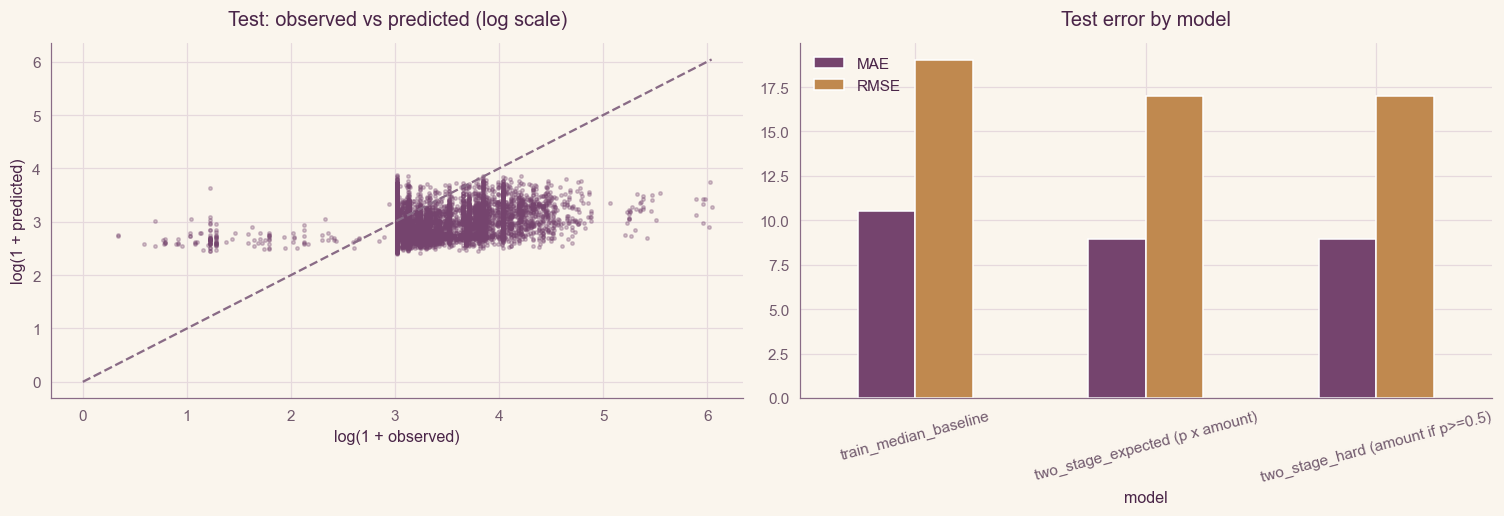

In [133]:
from sklearn.compose import TransformedTargetRegressor
parts = cost_parts
def most_common(v):
    vc = v.value_counts(normalize=True)
    return pd.Series({'most_common_value': vc.index[0], 'most_common_share': vc.iloc[0]})
diag = pd.DataFrame({k: {'rows': len(v), 'zero_share': v.claim_total.eq(0).mean(), 'mean': v.claim_total.mean(),
                         'median': v.claim_total.median(), 'p90': v.claim_total.quantile(.9), 'max': v.claim_total.max(),
                         **most_common(v.claim_total).to_dict()} for k, v in parts.items()}).T
print('Target distribution by period. A shift here, or one value repeating everywhere, explains most failures.')
display(diag.round(3))

tr, sel, te = parts['train'], parts['selection'], parts['test']
def fit_stage1(train):
    y = train.claim_total.gt(0).astype(int)
    if y.nunique() < 2:
        return None, float(y.iloc[0])
    m = prep(HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, learning_rate=.06, l2_regularization=5,early_stopping=False,random_state=SEED))
    return m.fit(train[FEATURES], y), None
def p_positive(m, const, X):
    return np.full(len(X), const) if m is None else m.predict_proba(X[FEATURES])[:, 1]

s1, s1_const = fit_stage1(tr)
pos_tr, pos_sel, pos_te = tr[tr.claim_total > 0], sel[sel.claim_total > 0], te[te.claim_total > 0]
cands = {
    'ridge_log': TransformedTargetRegressor(regressor=prep(Ridge(alpha=10), True), func=np.log1p, inverse_func=np.expm1),
    'boosting_log': TransformedTargetRegressor(regressor=prep(HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, learning_rate=.06, l2_regularization=10, early_stopping=False, random_state=SEED)), func=np.log1p, inverse_func=np.expm1)}
sel_scores = {}
fitted = {}
for name, m in cands.items():
    fitted[name] = m.fit(pos_tr[FEATURES], pos_tr.claim_total)
    sel_scores[name] = mean_absolute_error(pos_sel.claim_total, np.maximum(0, fitted[name].predict(pos_sel[FEATURES])))
s2_name = min(sel_scores, key=sel_scores.get); s2 = fitted[s2_name]
print('Stage 2 selection MAE on positive claims:', {k: round(v, 3) for k, v in sel_scores.items()}, '-> chosen', s2_name)

p = p_positive(s1, s1_const, te); amount = np.maximum(0, s2.predict(te[FEATURES])); y = te.claim_total.to_numpy()
preds = {'train_median_baseline': np.full(len(te), tr.claim_total.median()),
         'two_stage_expected (p x amount)': p * amount,
         'two_stage_hard (amount if p>=0.5)': np.where(p >= .5, amount, 0.0)}
rows = [{'model': k, 'n': len(te), 'MAE': mean_absolute_error(y, v), 'RMSE': np.sqrt(mean_squared_error(y, v)), 'R2': r2_score(y, v),
         'mean_observed': y.mean(), 'mean_predicted': v.mean()} for k, v in preds.items()]
cost2 = pd.DataFrame(rows).set_index('model'); display(cost2.round(3)); cost2.to_csv(EXT_OUT / 'two_stage_cost_metrics.csv')
if 'cost_test' in globals():
    print('Single-stage result from the earlier modeling section, for comparison:'); display(cost_test.round(3))
if len(np.unique(y > 0)) == 2:
    print(f'Stage 1 (claim > 0): AP {average_precision_score(y > 0, p):.3f}, ROC-AUC {roc_auc_score(y > 0, p):.3f} (prevalence {np.mean(y > 0):.3f})')
print(f'Stage 2 (amount | claim > 0): MAE {mean_absolute_error(pos_te.claim_total, np.maximum(0, s2.predict(pos_te[FEATURES]))):.2f} '
      f'vs median baseline {mean_absolute_error(pos_te.claim_total, np.full(len(pos_te), pos_tr.claim_total.median())):.2f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(np.log1p(y), np.log1p(preds['two_stage_expected (p x amount)']), s=5, alpha=.3, color=CL['mauve'])
lim = [0, max(np.log1p(y).max(), 1)]; ax[0].plot(lim, lim, ls='--', color=CL['dusk'])
ax[0].set(title='Test: observed vs predicted (log scale)', xlabel='log(1 + observed)', ylabel='log(1 + predicted)')
cost2[['MAE', 'RMSE']].plot(kind='bar', ax=ax[1], color=[CL['mauve'], CL['amber']]); ax[1].set_title('Test error by model'); ax[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

<div id="ext-survival" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Survival Analysis: Time to Next Visit</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Why:</b> a fixed 30-day return label throws information away and ignores censoring. Here the outcome is the <b>time until the next observed visit day</b>, measured from each patient's first observed visit. Patients without a later visit are censored at the end of follow-up. Kaplan–Meier curves are computed directly; a Cox model is fitted if <code>lifelines</code> is installed.</div>

61,029 patients · 42.5% observed a later visit · 57.5% censored
Cumulative probability of a later visit (Kaplan–Meier, censoring-aware):


,days,returned_pct
0,30,21.2
1,90,27.7
2,180,33.3
3,365,37.5


Median time to next visit: not reached (fewer than half return within follow-up)


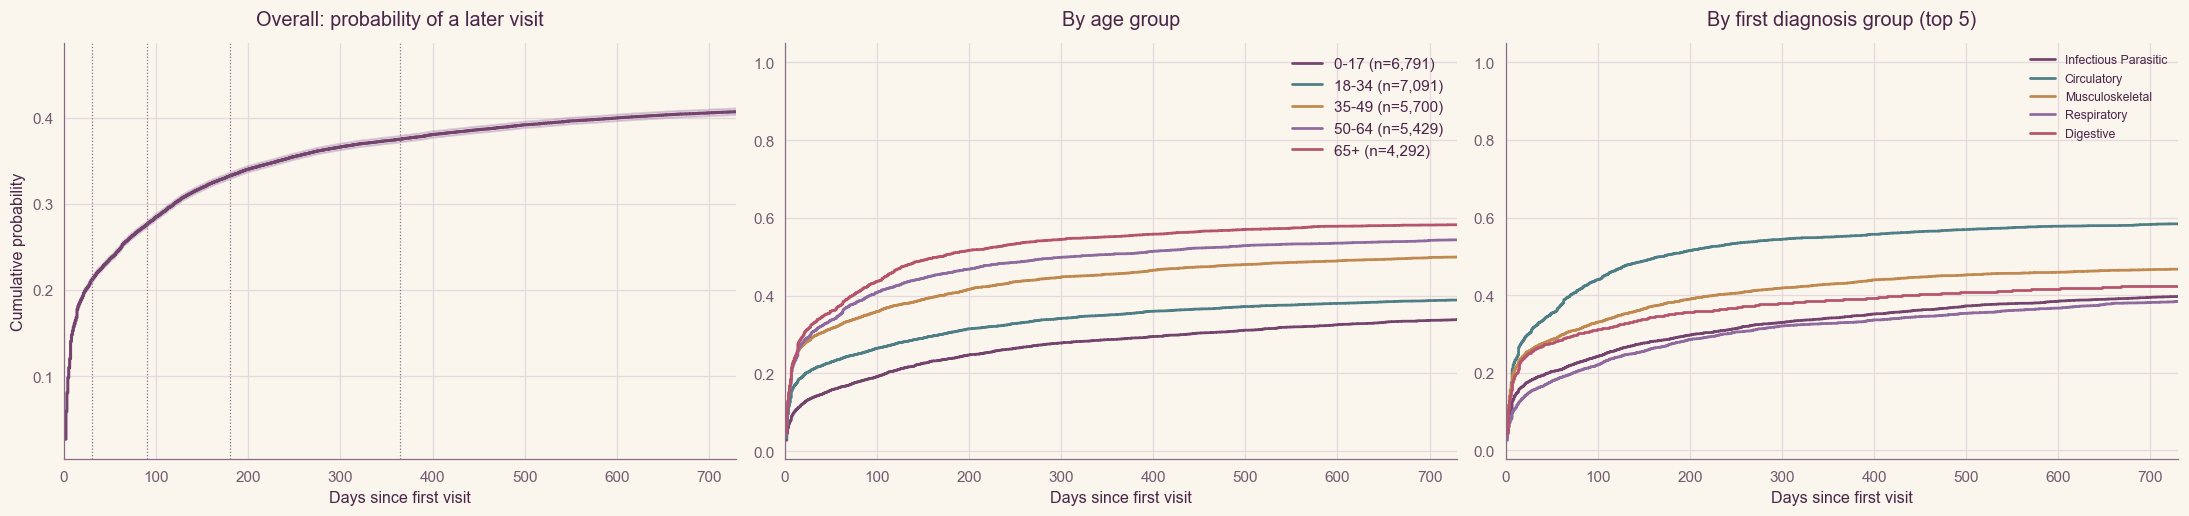

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
age,1.010,1.009,1.011,0.000
female,1.061,1.019,1.105,0.004
dx_DIGESTIVE,0.828,0.769,0.891,0.000
dx_INFECTIOUS_PARASITIC,0.736,0.693,0.782,0.000
dx_MUSCULOSKELETAL,0.871,0.824,0.921,0.000
dx_RESPIRATORY,0.752,0.703,0.805,0.000


Reading: "return" means another observed visit day in this source, not inpatient readmission.


In [151]:
from scipy import stats as _st
first = episodes[(episodes.visit_number == 1) & episodes.temporal_history_complete].copy()
ev = first.days_to_next_visit.notna()
first['event'] = ev.astype(int)
first['time'] = np.where(ev, first.days_to_next_visit, first.followup_days_observed).astype(float)
first = first[first.time > 0]
rec = df.sort_values(['patient_id', 'visit_date']).drop_duplicates('patient_id')[['patient_id', 'age', 'gender', 'disease_category']]
first = first.merge(rec, on='patient_id', how='left')
first['age_group'] = pd.cut(first.age, bins=AGE_BINS, labels=AGE_LABELS, right=False)
print(f'{len(first):,} patients · {first.event.mean():.1%} observed a later visit · {1 - first.event.mean():.1%} censored')

def km_curve(time, event):
    t = pd.DataFrame({'t': np.asarray(time, float), 'e': np.asarray(event, int)}).groupby('t').agg(d=('e', 'sum'), n=('e', 'size')).sort_index()
    at_risk = t.n[::-1].cumsum()[::-1]
    S = (1 - t.d / at_risk).cumprod()
    var = (t.d / (at_risk * (at_risk - t.d).replace(0, np.nan))).cumsum()
    se = S * np.sqrt(var)
    return pd.DataFrame({'t': t.index.to_numpy(), 'S': S.to_numpy(), 'lo': (S - 1.96 * se).clip(0, 1).to_numpy(),
                         'hi': (S + 1.96 * se).clip(0, 1).to_numpy(), 'at_risk': at_risk.to_numpy()})

def surv_at(curve, t):
    i = np.searchsorted(curve.t.to_numpy(), t, side='right') - 1
    return 1.0 if i < 0 else float(curve.S.iloc[i])

def logrank(time, event, group):
    d = pd.DataFrame({'t': np.asarray(time, float), 'e': np.asarray(event, int), 'g': np.asarray(group)}).dropna()
    gs = sorted(d.g.unique()); k = len(gs)
    times = np.sort(d.loc[d.e == 1, 't'].unique())
    n_g, d_g = [], []
    for g in gs:
        tg = np.sort(d.loc[d.g == g, 't'].to_numpy()); eg = np.sort(d.loc[(d.g == g) & (d.e == 1), 't'].to_numpy())
        n_g.append(len(tg) - np.searchsorted(tg, times, 'left'))
        d_g.append(np.searchsorted(eg, times, 'right') - np.searchsorted(eg, times, 'left'))
    n_g, d_g = np.array(n_g, float), np.array(d_g, float)
    N, D = n_g.sum(0), d_g.sum(0)
    O_E = d_g.sum(1) - (D * n_g / N).sum(1)
    with np.errstate(divide='ignore', invalid='ignore'):
        f = np.where(N > 1, D * (N - D) / (N * N * (N - 1)), 0.0)
    V = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            V[i, j] = (f * n_g[i] * ((N if i == j else 0) - n_g[j])).sum()
    chi = float(O_E[:-1] @ np.linalg.pinv(V[:-1, :-1]) @ O_E[:-1])
    return chi, float(_st.chi2.sf(chi, k - 1))

overall = km_curve(first.time, first.event)
horizons = [30, 90, 180, 365]
ret_km = pd.DataFrame({'days': horizons, 'returned_pct': [(1 - surv_at(overall, h)) * 100 for h in horizons]})
below = overall[overall.S <= .5]
print('Cumulative probability of a later visit (Kaplan–Meier, censoring-aware):'); display(ret_km.round(1))
print('Median time to next visit:', f'{below.t.iloc[0]:.0f} days' if len(below) else 'not reached (fewer than half return within follow-up)')
ret_km.to_csv(EXT_OUT / 'return_by_horizon.csv', index=False)

top_ch = first.disease_category.value_counts().head(5).index
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
ax[0].step(overall.t, 1 - overall.S, where='post', color=CL['mauve'], lw=2)
ax[0].fill_between(overall.t, 1 - overall.hi, 1 - overall.lo, step='post', color=CL['orchid'], alpha=.25)
for h in horizons: ax[0].axvline(h, ls=':', color=CL['dusk'], lw=.8)
ax[0].set(title='Overall: probability of a later visit', xlabel='Days since first visit', ylabel='Cumulative probability', xlim=(0, 730))
for i, g in enumerate([x for x in AGE_LABELS if (first.age_group == x).sum() > 30]):
    s = first[first.age_group == g]; c = km_curve(s.time, s.event)
    ax[1].step(c.t, 1 - c.S, where='post', label=f'{g} (n={len(s):,})', color=CL_CYCLE[i % 6], lw=1.8)
ax[1].set(title='By age group', xlabel='Days since first visit', xlim=(0, 730)); ax[1].legend()
for i, g in enumerate(top_ch):
    s = first[first.disease_category == g]; c = km_curve(s.time, s.event)
    ax[2].step(c.t, 1 - c.S, where='post', label=nice(g), color=CL_CYCLE[i % 6], lw=1.8)
ax[2].set(title='By first diagnosis group (top 5)', xlabel='Days since first visit', xlim=(0, 730)); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

for label_, col in [('age group', 'age_group'), ('first diagnosis group', 'disease_category'), ('gender', 'gender')]:
    s = first[first[col].notna()]
    if col == 'disease_category': s = s[s[col].isin(top_ch)]
    if col == 'gender': s = s[s[col].isin(['F', 'M'])]
    chi, pval = logrank(s.time, s.event, s[col].astype(str))
    
# Optional Cox proportional-hazards model (hazard ratio > 1 = returns sooner).
try:
    from lifelines import CoxPHFitter
    cox = first[['time', 'event', 'age', 'gender', 'disease_category']].dropna()
    cox = cox[cox.gender.isin(['F', 'M']) & cox.disease_category.isin(top_ch)]
    cox = cox.sample(min(30000, len(cox)), random_state=SEED)
    cox['female'] = cox.gender.eq('F').astype(int)
    cox = pd.concat([cox[['time', 'event', 'age', 'female']], pd.get_dummies(cox.disease_category, prefix='dx', drop_first=True).astype(int)], axis=1)
    cph = CoxPHFitter(penalizer=.01).fit(cox, 'time', 'event')
    display(cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']].round(3))
except ImportError:
    print('Optional: pip install lifelines to add a Cox hazard-ratio table. Kaplan–Meier results above do not need it.')
print('Reading: "return" means another observed visit day in this source, not inpatient readmission.')

<div id="ext-comorbidity" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Comorbidity Network</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Question:</b> which diagnosis groups appear together in the same patient more often than chance? Lift = P(A and B) / (P(A) × P(B)); confidence = P(B | A). Only pairs seen in at least 30 patients are shown. Chapters come from syntactic ICD parsing, so read them as patterns, not clinical conclusions.</div>

35,808 patients with at least one valid chapter · 46.6% have two or more


,A,B,patients_both,support_pct,conf_A_to_B_pct,conf_B_to_A_pct,lift,p_fisher,robust
0,HEALTH_SERVICE_CONTACT,PREGNANCY_CHILDBIRTH,32,0.09,6.58,15.02,11.07,0.00,False
1,MENTAL_BEHAVIOURAL,NERVOUS_SYSTEM,114,0.32,17.98,4.77,2.70,0.00,True
2,GENITOURINARY,NEOPLASMS,176,0.49,3.85,32.53,2.55,0.00,True
3,CIRCULATORY,ENDOCRINE_METABOLIC,3184,8.89,31.08,71.81,2.51,0.00,True
4,BLOOD_IMMUNE,NEOPLASMS,91,0.25,3.30,16.82,2.18,0.00,False
5,ENDOCRINE_METABOLIC,MENTAL_BEHAVIOURAL,165,0.46,3.72,26.03,2.10,0.00,True
6,MENTAL_BEHAVIOURAL,SYMPTOMS_SIGNS,63,0.18,9.94,3.64,2.06,0.00,False
7,ENDOCRINE_METABOLIC,NERVOUS_SYSTEM,584,1.63,13.17,24.45,1.97,0.00,True
8,DIGESTIVE,MENTAL_BEHAVIOURAL,143,0.40,2.90,22.56,1.64,0.00,True
9,CIRCULATORY,MENTAL_BEHAVIOURAL,285,0.80,2.78,44.95,1.57,0.00,True


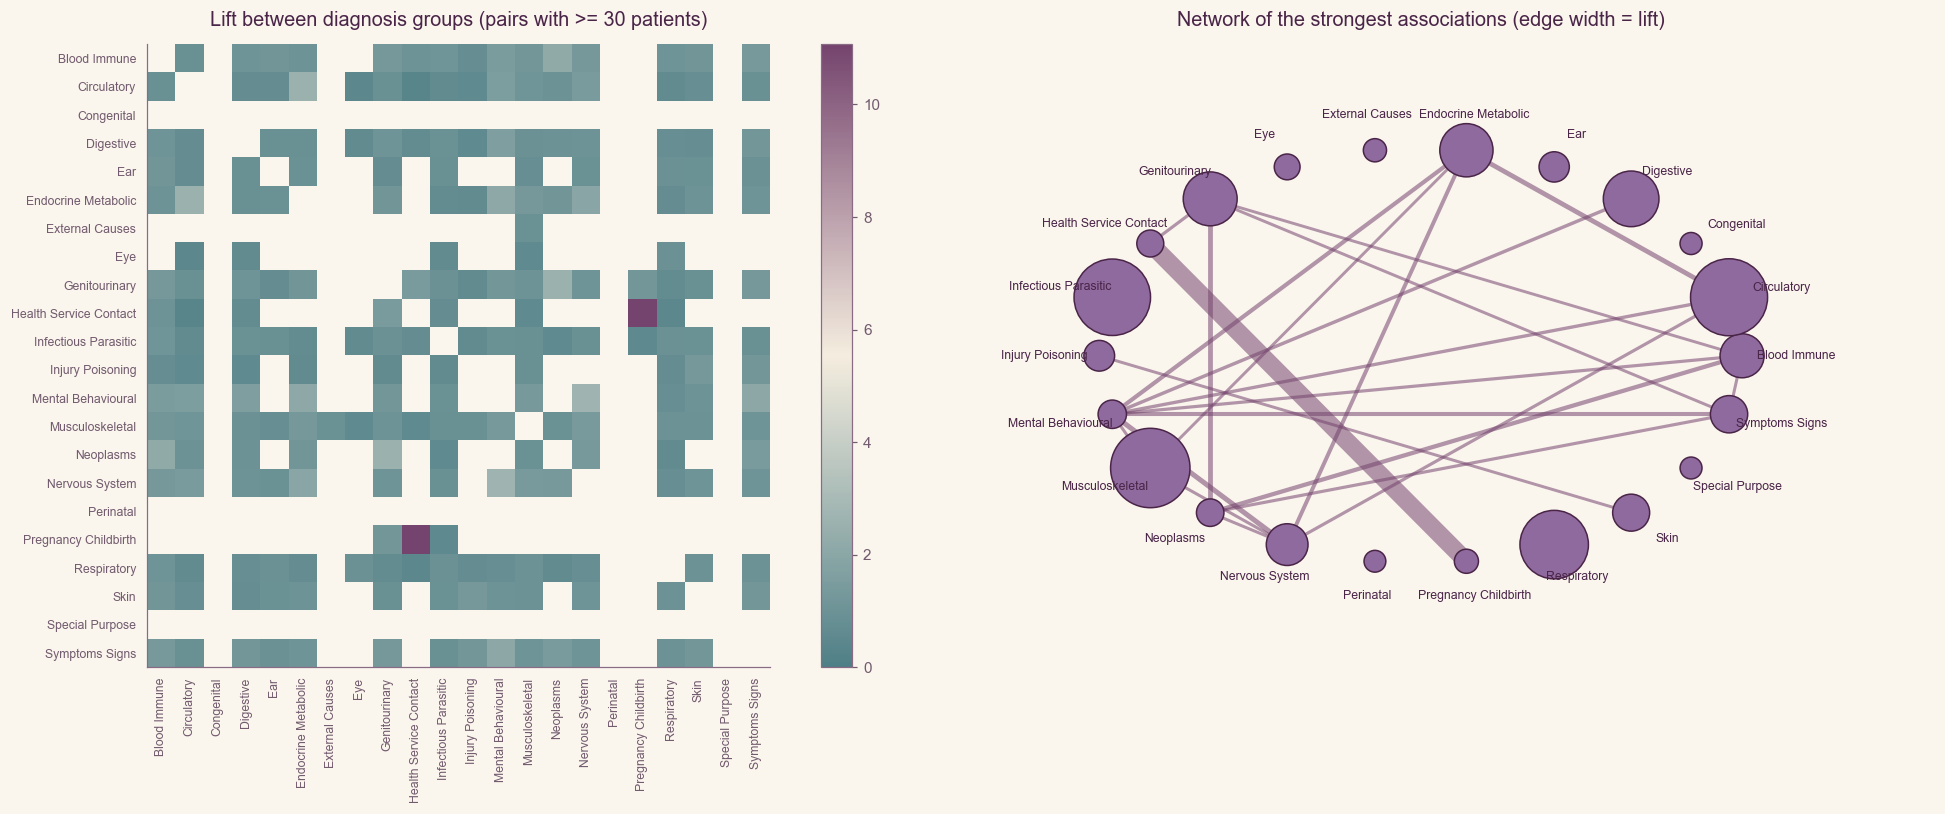

Strongest robust association (>= 100 patients, Fisher p < 0.001): Mental Behavioural + Nervous System (lift 2.7, 114 patients). Pairs below that bar are listed in the table but not headlined. Co-occurrence reflects coding and care patterns as much as biology and is not adjusted for age or sex.


In [135]:
src = 'icd10_chapters' if 'icd10_chapters' in df.columns else 'disease_category'
long = (df[['patient_id', src]].dropna().assign(ch=lambda t: t[src].astype(str).str.split(r'[,;|]'))
          .explode('ch').assign(ch=lambda t: t.ch.str.strip().str.upper()))
long = long[~long.ch.isin(INVALID_DX | {'MULTIPLE_CHAPTERS'})].drop_duplicates(['patient_id', 'ch'])
M = long.assign(v=1).pivot_table(index='patient_id', columns='ch', values='v', aggfunc='max', fill_value=0).astype(int)
n = len(M); MIN_PAIR = 30
co = M.T.values @ M.values
cnt = np.diag(co).astype(float)
cols = list(M.columns)
rows = []
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if co[i, j] >= MIN_PAIR:
            lift = co[i, j] * n / (cnt[i] * cnt[j])
            rows.append({'A': cols[i], 'B': cols[j], 'patients_both': int(co[i, j]), 'support_pct': co[i, j] / n * 100,
                         'conf_A_to_B_pct': co[i, j] / cnt[i] * 100, 'conf_B_to_A_pct': co[i, j] / cnt[j] * 100, 'lift': lift})
pairs = pd.DataFrame(rows).sort_values('lift', ascending=False).reset_index(drop=True)
from scipy import stats as _scs
def _fisher_p(r_):
    nA, nB, k_ = cnt[cols.index(r_.A)], cnt[cols.index(r_.B)], int(r_.patients_both)
    return _scs.fisher_exact([[k_, int(nA - k_)], [int(nB - k_), int(n - nA - nB + k_)]])[1]
if len(pairs):
    pairs['p_fisher'] = pairs.apply(_fisher_p, axis=1)
    pairs['robust'] = pairs.patients_both.ge(100) & pairs.p_fisher.lt(1e-3) & pairs.lift.gt(1)
_pool = pairs[pairs.robust] if (len(pairs) and pairs.robust.any()) else pairs
pair_top = _pool.iloc[0] if len(_pool) else None
print(f'{n:,} patients with at least one valid chapter · {(M.sum(axis=1) >= 2).mean():.1%} have two or more')
display(pairs.head(15).round(2))
pairs.to_csv(EXT_OUT / 'comorbidity_pairs.csv', index=False)

lift_m = pd.DataFrame(np.nan, index=cols, columns=cols)
for r in pairs.itertuples():
    lift_m.loc[r.A, r.B] = lift_m.loc[r.B, r.A] = r.lift
fig, ax = plt.subplots(1, 2, figsize=(20, 7.5))
im = ax[0].imshow(lift_m.astype(float).values, cmap=CL_DIV, vmin=0, vmax=max(2, np.nanmax(lift_m.values) if pairs.shape[0] else 2))
ax[0].set_xticks(range(len(cols))); ax[0].set_xticklabels([nice(c) for c in cols], rotation=90, fontsize=8)
ax[0].set_yticks(range(len(cols))); ax[0].set_yticklabels([nice(c) for c in cols], fontsize=8)
ax[0].set_title('Lift between diagnosis groups (pairs with >= 30 patients)'); ax[0].grid(False); plt.colorbar(im, ax=ax[0], fraction=.04)
# Network: nodes sized by patients, edges are the strongest positive associations.
edges = pairs[pairs.lift >= 1.3].head(25)
theta = np.linspace(0, 2 * np.pi, len(cols), endpoint=False); pos = {c: (np.cos(t), np.sin(t)) for c, t in zip(cols, theta)}
for r in edges.itertuples():
    ax[1].plot(*zip(pos[r.A], pos[r.B]), color=CL['mauve'], alpha=.55, lw=.6 + r.lift)
sizes = 200 + 2500 * cnt / cnt.max()
ax[1].scatter([pos[c][0] for c in cols], [pos[c][1] for c in cols], s=sizes, color=CL['orchid'], edgecolor=CL['plum'], zorder=3)
for c in cols: ax[1].text(pos[c][0] * 1.17, pos[c][1] * 1.17, nice(c), ha='center', va='center', fontsize=8)
ax[1].set_xlim(-1.6, 1.6); ax[1].set_ylim(-1.5, 1.5); ax[1].axis('off'); ax[1].set_title('Network of the strongest associations (edge width = lift)')
plt.tight_layout(); plt.show()
if pair_top is not None:
    print(f'Strongest robust association (>= 100 patients, Fisher p < 0.001): {nice(pair_top.A)} + {nice(pair_top.B)} (lift {pair_top.lift:.1f}, {int(pair_top.patients_both):,} patients). '
          'Pairs below that bar are listed in the table but not headlined. Co-occurrence reflects coding and care patterns as much as biology and is not adjusted for age or sex.')

<div id="ext-sequence" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Sequence Modeling: Next Diagnosis Group</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Question:</b> given the diagnosis group of a patient's current and previous visit days, what group is most likely at the next visit? Compared against a majority baseline, "same as last time" persistence, first- and second-order Markov chains, and a boosted model. Chronological split: training transitions finish before the test period begins.</div>

28,284 training transitions · 10,590 test transitions · 17 classes · split at 2024-05-22


,top1_acc,top3_acc,macro_F1
model,,,
majority_baseline,0.271,0.506,0.025
persistence (same as last),0.375,0.454,0.289
markov_order1,0.367,0.644,0.202
markov_order2_backoff,0.378,0.655,0.211
boosting_history,0.373,0.679,0.179


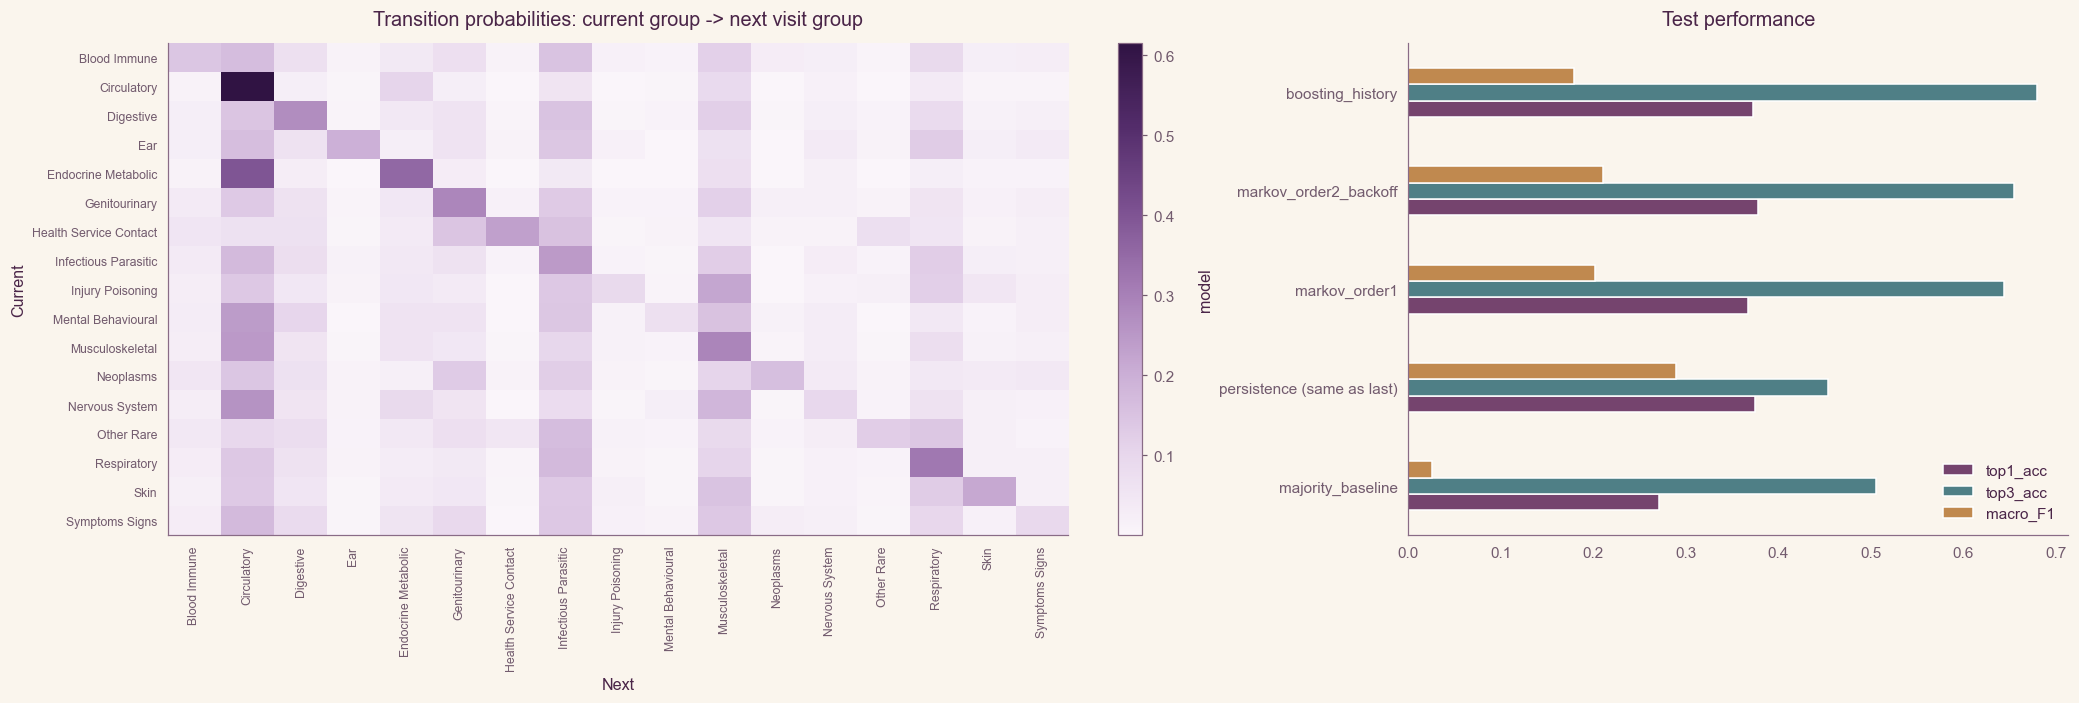

Best model: markov_order2_backoff - top-1 37.8% vs majority 27.1%; top-3 65.5%. Diagnosis groups are syntax-derived, so this is a pattern study, not a clinical predictor.


In [136]:
dx = df[df.disease_category.notna() & ~df.disease_category.astype(str).str.upper().isin(INVALID_DX)]
seq = (dx.sort_values(['patient_id', 'visit_date']).drop_duplicates(['patient_id', 'visit_date'])
         [['patient_id', 'visit_date', 'disease_category', 'age', 'gender']].rename(columns={'disease_category': 'cur'}).reset_index(drop=True))
g = seq.groupby('patient_id', sort=False)
seq['prev1'] = g.cur.shift(1); seq['nxt'] = g.cur.shift(-1)
seq['next_date'] = g.visit_date.shift(-1)
seq['gap_prev'] = (seq.visit_date - g.visit_date.shift(1)).dt.days
seq['n_prior'] = g.cumcount()
seq['female'] = seq.gender.eq('F').astype(int)
seq = seq[seq.nxt.notna()].copy()

CUT = seq.visit_date.quantile(.75)
tr_s = seq[seq.next_date < CUT].copy()          # transitions fully completed before the cut
te_s = seq[seq.visit_date >= CUT].copy()
# Rare classes are decided on training only.
cnt_tr = tr_s.nxt.value_counts()
keep = set(cnt_tr[cnt_tr >= 100].index)
for f in (tr_s, te_s):
    for c in ['cur', 'prev1', 'nxt']:
        f[c] = f[c].where(f[c].isin(keep) | f[c].isna(), 'OTHER_RARE')
classes = sorted(set(tr_s.nxt) | set(te_s.nxt)); K = len(classes); cidx = {c: i for i, c in enumerate(classes)}
print(f'{len(tr_s):,} training transitions · {len(te_s):,} test transitions · {K} classes · split at {CUT.date()}')
y_te = te_s.nxt.map(cidx).to_numpy()

def onehot(vals):
    P = np.tile(prior, (len(vals), 1)).astype(float)   # unseen groups fall back to the prior, never to class 0
    for i, v in enumerate(vals):
        if v in cidx:
            P[i] = 1e-9; P[i, cidx[v]] = 1
    return P / P.sum(1, keepdims=True)
prior = tr_s.nxt.value_counts(normalize=True).reindex(classes).fillna(0).to_numpy()
M1 = pd.crosstab(tr_s.cur, tr_s.nxt).reindex(columns=classes, fill_value=0)
M1p = (M1 + .5).div((M1 + .5).sum(axis=1), axis=0)
P_mark1 = np.vstack([M1p.loc[c].to_numpy() if c in M1p.index else prior for c in te_s.cur])
pair_counts = tr_s.groupby(['prev1', 'cur']).nxt.value_counts().unstack(fill_value=0).reindex(columns=classes, fill_value=0)
P_mark2 = P_mark1.copy()
for i, (p1, c) in enumerate(zip(te_s.prev1, te_s.cur)):
    if (p1, c) in pair_counts.index and pair_counts.loc[(p1, c)].sum() >= 20:
        v = pair_counts.loc[(p1, c)].to_numpy() + .5; P_mark2[i] = v / v.sum()
# Boosted model on categorical history plus gap, age and sex.
cat_enc = {c: i for i, c in enumerate(classes)}
def feats(f):
    return np.column_stack([f.cur.map(cat_enc), f.prev1.map(cat_enc).fillna(-1), f.gap_prev.fillna(-1), f.age.fillna(-1), f.female, f.n_prior]).astype(float)
hgb = HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15, learning_rate=.08, categorical_features=[0, 1], random_state=SEED)
Xtr_s = feats(tr_s); Xtr_s[:, 1] = np.where(Xtr_s[:, 1] < 0, K, Xtr_s[:, 1])
Xte_s = feats(te_s); Xte_s[:, 1] = np.where(Xte_s[:, 1] < 0, K, Xte_s[:, 1])
hgb.fit(Xtr_s, tr_s.nxt.map(cidx))
P_hgb = np.full((len(te_s), K), 1e-9); P_hgb[:, hgb.classes_] = hgb.predict_proba(Xte_s)

def score(name, P):
    top3 = np.argsort(-P, axis=1)[:, :3]; pred = P.argmax(1)
    return {'model': name, 'top1_acc': accuracy_score(y_te, pred), 'top3_acc': np.mean([y_te[i] in top3[i] for i in range(len(y_te))]),
            'macro_F1': f1_score(y_te, pred, average='macro', labels=range(K), zero_division=0)}
res = pd.DataFrame([score('majority_baseline', np.tile(prior, (len(te_s), 1))), score('persistence (same as last)', onehot(te_s.cur)),
                    score('markov_order1', P_mark1), score('markov_order2_backoff', P_mark2), score('boosting_history', P_hgb)]).set_index('model')
display(res.round(3)); res.to_csv(EXT_OUT / 'next_diagnosis_metrics.csv')

best_seq = res.drop('majority_baseline').top1_acc.idxmax()
T = M1p.loc[[c for c in classes if c in M1p.index]]
fig, ax = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw={'width_ratios': [1.5, 1]})
im = ax[0].imshow(T.values, cmap=CL_SEQ, aspect='auto')
ax[0].set_xticks(range(K)); ax[0].set_xticklabels([nice(c) for c in classes], rotation=90, fontsize=8)
ax[0].set_yticks(range(len(T))); ax[0].set_yticklabels([nice(c) for c in T.index], fontsize=8)
ax[0].set(title='Transition probabilities: current group -> next visit group', xlabel='Next', ylabel='Current'); ax[0].grid(False); plt.colorbar(im, ax=ax[0], fraction=.04)
res[['top1_acc', 'top3_acc', 'macro_F1']].plot(kind='barh', ax=ax[1], color=[CL['mauve'], CL['teal'], CL['amber']]); ax[1].set_title('Test performance'); ax[1].grid(False)
plt.tight_layout(); plt.show()
print(f"Best model: {best_seq} - top-1 {res.loc[best_seq,'top1_acc']:.1%} vs majority {res.loc['majority_baseline','top1_acc']:.1%}; "
      f"top-3 {res.loc[best_seq,'top3_acc']:.1%}. Diagnosis groups are syntax-derived, so this is a pattern study, not a clinical predictor.")

<div id="ext-forecast" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Volume and Cost Forecasting</h2></div>

<div style="padding:14px 20px;background:#faf5ed;border-left:3px solid #75446e;color:#4a2548;font:14px/1.7 Arial"><b>Question:</b> how many claims, and how much cost, should we expect in the coming months? Holds out the last 12 complete months and compares seasonal-naive, Holt-Winters and SARIMA forecasts (the last two need <code>statsmodels</code>). Source-coverage changes can look like trends, so treat the forecast as a baseline.</div>

23 month(s) had no usable records and were interpolated (coverage gap, not zero demand).
claims/holt_winters skipped: TypeError
cost/holt_winters skipped: TypeError


,series,method,MAE,MAPE_%
0,claims,seasonal_naive,77.07,5.58
1,claims,sarima,92.82,6.88
2,cost,seasonal_naive,2661.51,7.46
3,cost,sarima,2049.14,5.91


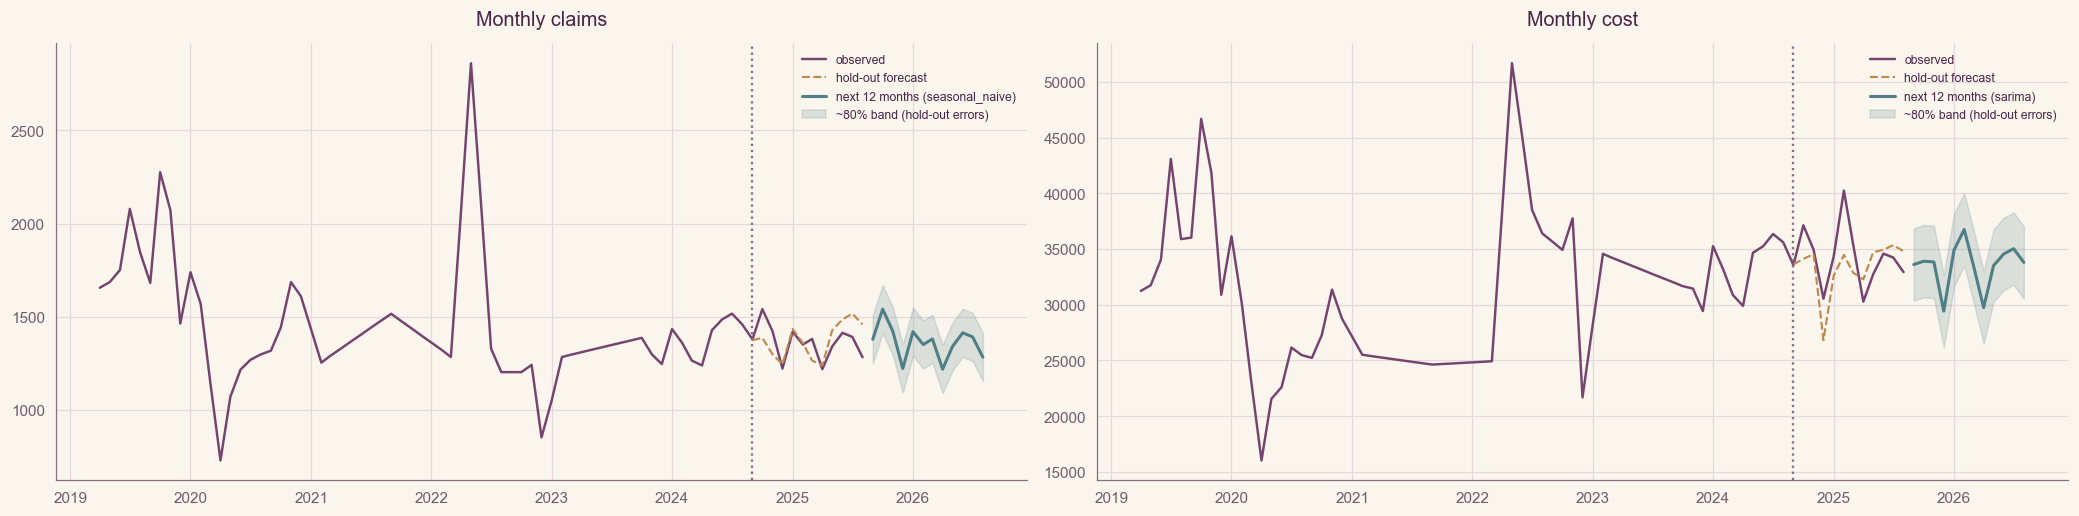

Claims: seasonal naive is the best hold-out method (MAPE 5.6%); the statistical models do not beat it. Forecasts assume source coverage stays the same.


In [139]:
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Clean & Aggregate Data
d = df.dropna(subset=['visit_date'])
last = d.visit_date.max()
if last.day < last.days_in_month:  # drop a partial final month
    d = d[d.visit_date < last.to_period('M').to_timestamp()]

monthly = pd.DataFrame(
    {
        'claims': d.groupby(d.visit_date.dt.to_period('M')).size(),
        'cost': d.groupby(d.visit_date.dt.to_period('M')).total_claim.sum(),
    }
)
monthly.index = monthly.index.to_timestamp()
monthly = monthly.asfreq('MS')

gap_months = int(monthly.claims.isna().sum())
monthly = monthly.interpolate(limit_area='inside').ffill().bfill()
if gap_months:
    print(
        f'{gap_months} month(s) had no usable records and were interpolated (coverage gap, not zero demand).'
    )

H = 12
assert len(monthly) >= 36, 'Need at least 3 years of monthly data.'


# 2. Robust Model Definitions
def seasonal_naive(train, h):
    return np.array([train.iloc[-12 + (i % 12)] for i in range(h)])


def holt_winters(train, h):
    # Scale series to avoid numerical overflow on large values (e.g. total cost)
    scale = max(float(train.mean()), 1.0)
    scaled_train = train.astype(float) / scale

    fit_kwargs = {
        'optimized': True,
        'method': 'L-BFGS-B',
        'optimizer_kwargs': {'options': {'maxiter': 2000}},
    }

    try:
        # Use initialization_method='estimated' to avoid convergence failures
        model = ExponentialSmoothing(
            scaled_train,
            trend='add',
            seasonal='add',
            seasonal_periods=12,
            damped_trend=True,
            initialization_method='estimated',
        ).fit(**fit_kwargs)
    except Exception:
        # Fallback to heuristic initialization if numerical optimization still struggles
        model = ExponentialSmoothing(
            scaled_train,
            trend='add',
            seasonal='add',
            seasonal_periods=12,
            damped_trend=True,
            initialization_method='heuristic',
        ).fit(**fit_kwargs)

    return model.forecast(h).to_numpy() * scale


def sarima(train, h):
    # Enforce MS frequency explicitly to suppress statsmodels ValueWarning
    s_train = train.copy()
    s_train.index.freq = 'MS'

    mod = SARIMAX(
        s_train,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 0, 12),
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    return mod.fit(disp=False, maxiter=200).forecast(h).to_numpy()


methods = {
    'seasonal_naive': seasonal_naive,
    'holt_winters': holt_winters,
    'sarima': sarima,
}

# 3. Hold-out Evaluation
results, fc_hold = [], {}
for series_name in ['claims', 'cost']:
    train = monthly[series_name].iloc[:-H].asfreq('MS')
    test = monthly[series_name].iloc[-H:].asfreq('MS')

    for m_name, fn in methods.items():
        try:
            f = np.maximum(0, fn(train, H))
        except Exception as e:
            print(f'{series_name}/{m_name} skipped: {type(e).__name__}')
            continue

        fc_hold[(series_name, m_name)] = f
        results.append(
            {
                'series': series_name,
                'method': m_name,
                'MAE': mean_absolute_error(test, f),
                'MAPE_%': np.mean(
                    np.abs(test.to_numpy() - f) / np.maximum(test.to_numpy(), 1)
                )
                * 100,
            }
        )

res_fc = pd.DataFrame(results)
display(res_fc.round(2))
res_fc.to_csv(EXT_OUT / 'forecast_holdout_metrics.csv', index=False)

# 4. Future Forecast & Plotting
fig, ax = plt.subplots(1, 2, figsize=(19, 4.8))
# Correct date increment for month-start frequencies
future_idx = pd.date_range(
    monthly.index[-1] + pd.DateOffset(months=1), periods=H, freq='MS'
)

fc_rows = []
for a_, series_name in zip(ax, ['claims', 'cost']):
    best_m = (
        res_fc[res_fc.series == series_name].sort_values('MAE').iloc[0].method
    )
    s = monthly[series_name].asfreq('MS')
    resid = s.iloc[-H:].to_numpy() - fc_hold[(series_name, best_m)]

    try:
        fc = np.maximum(0, methods[best_m](s, H))
    except Exception:
        fc = seasonal_naive(s, H)
        best_m = 'seasonal_naive'

    band = 1.28 * resid.std(ddof=1)

    a_.plot(s.index, s.values, color=CL['mauve'], lw=1.6, label='observed')
    a_.plot(
        s.index[-H:],
        fc_hold[(series_name, best_m)],
        color=CL['amber'],
        lw=1.4,
        ls='--',
        label='hold-out forecast',
    )
    a_.plot(
        future_idx,
        fc,
        color=CL['teal'],
        lw=2,
        label=f'next {H} months ({best_m})',
    )
    a_.fill_between(
        future_idx,
        np.maximum(0, fc - band),
        fc + band,
        color=CL['teal'],
        alpha=0.18,
        label='~80% band (hold-out errors)',
    )
    a_.axvline(s.index[-H], ls=':', color=CL['dusk'])
    a_.set_title(f'Monthly {series_name}')
    a_.legend(fontsize=8)

    fc_rows.append(
        pd.DataFrame(
            {
                'series': series_name,
                'month': future_idx,
                'forecast': fc,
                'lower_80': np.maximum(0, fc - band),
                'upper_80': fc + band,
                'method': best_m,
            }
        )
    )

plt.tight_layout()
plt.show()
pd.concat(fc_rows).to_csv(EXT_OUT / 'forecast_next_12_months.csv', index=False)

best_claims = (
    res_fc[res_fc.series == 'claims'].sort_values('MAE').iloc[0]
)
naive_claims = res_fc[
    (res_fc.series == 'claims') & (res_fc.method == 'seasonal_naive')
].iloc[0]

if best_claims.method == 'seasonal_naive':
    print(
        f"Claims: seasonal naive is the best hold-out method (MAPE {best_claims['MAPE_%']:.1f}%); the statistical models do not beat it. Forecasts assume source coverage stays the same."
    )
else:
    print(
        f"Claims: best hold-out method {best_claims.method} (MAPE {best_claims['MAPE_%']:.1f}%) vs seasonal naive {naive_claims['MAPE_%']:.1f}%. Forecasts assume source coverage stays the same."
    )

<div id="ext-summary" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / EXTENDED ML</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Extended ML · Summary</h2></div>

In [140]:
summary = []
summary.append(('Segmentation', f'{best_k} segments, silhouette {sil[best_k]:.2f}', 'Descriptive grouping, not clinical'))
summary.append(('High-cost detection', f"top-10% flag captures {hc.loc[best_name,'future_cost_captured_pct']:.0f}% of next-year cost (lift {hc.loc[best_name,'lift_top10pct']:.1f}x)", f'AP {hc.loc[best_name,"AP"]:.3f} vs prevalence {yte.mean():.3f}'))
summary.append(('Anomaly detection', f'{n_flagged:,} claims in the top-{REVIEW_RATE:.0%} review list', 'Unsupervised; needs human review'))
summary.append(('Two-stage cost', f"MAE {cost2.iloc[1].MAE:.2f} vs baseline {cost2.iloc[0].MAE:.2f}", 'Check target diagnostics table first'))
summary.append(('Survival', f"{ret_km.returned_pct.iloc[0]:.0f}% return within 30 days, {ret_km.returned_pct.iloc[-1]:.0f}% within 365", 'Censoring-aware; not readmission'))
summary.append(('Comorbidity', f"{nice(pair_top.A)} + {nice(pair_top.B)} (lift {pair_top.lift:.1f})" if pair_top is not None else 'no robust pair', 'Coding patterns, not causation'))
summary.append(('Next diagnosis', f"top-1 {res.loc[best_seq,'top1_acc']:.1%}, top-3 {res.loc[best_seq,'top3_acc']:.1%} ({best_seq})", f"majority baseline {res.loc['majority_baseline','top1_acc']:.1%}"))
summary.append(('Forecasting', f"claims MAPE {best_claims['MAPE_%']:.1f}% ({best_claims.method})", f"seasonal naive {naive_claims['MAPE_%']:.1f}%"))
summ = pd.DataFrame(summary, columns=['analysis', 'headline result', 'caveat'])
display(summ); summ.to_csv(EXT_OUT / 'extended_ml_summary.csv', index=False)

,analysis,headline result,caveat
0,Segmentation,"3 segments, silhouette 0.48","Descriptive grouping, not clinical"
1,High-cost detection,top-10% flag captures 64% of next-year cost (l...,AP 0.356 vs prevalence 0.011
2,Anomaly detection,781 claims in the top-1% review list,Unsupervised; needs human review
3,Two-stage cost,MAE 8.97 vs baseline 10.52,Check target diagnostics table first
4,Survival,"21% return within 30 days, 38% within 365",Censoring-aware; not readmission
5,Comorbidity,Mental Behavioural + Nervous System (lift 2.7),"Coding patterns, not causation"
6,Next diagnosis,"top-1 37.8%, top-3 65.5% (markov_order2_backoff)",majority baseline 27.1%
7,Forecasting,claims MAPE 5.6% (seasonal_naive),seasonal naive 5.6%


<div id="carelytics-dashboard" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / DASHBOARD</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Dashboard</h2></div>

Scroll inside the frame below: each section answers one question. The same page is saved as `outputs/dashboard/carelytics_dashboard.html` for full-screen viewing in a browser. Every figure is computed by this notebook; sections whose inputs are missing are skipped.


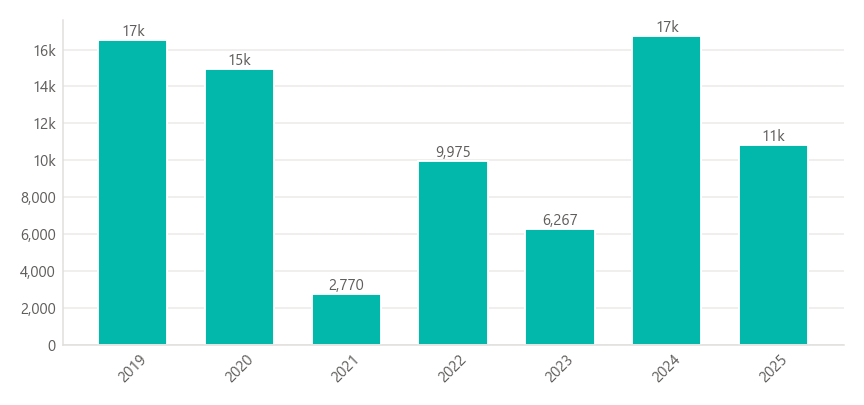
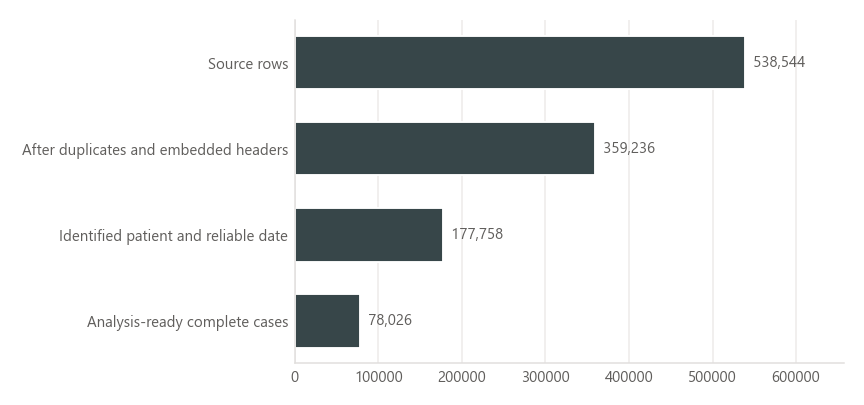
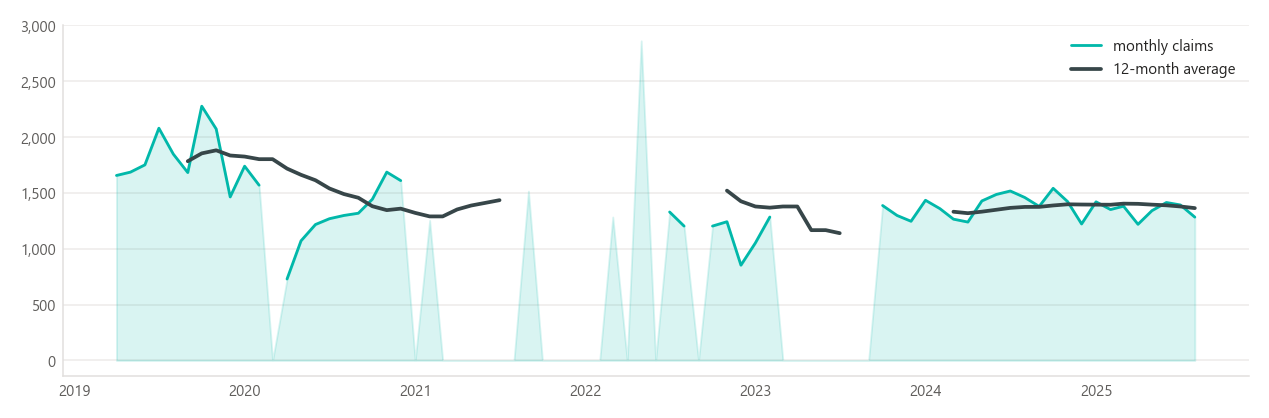
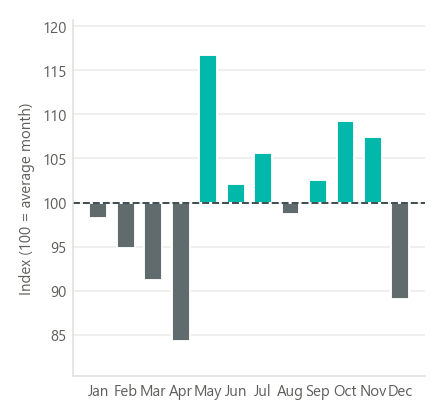
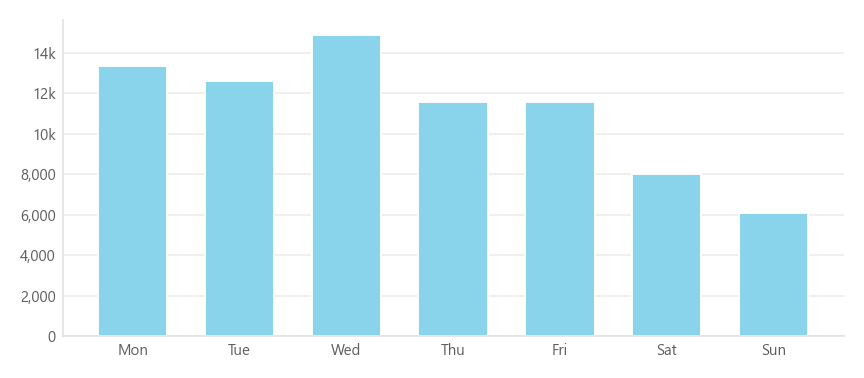
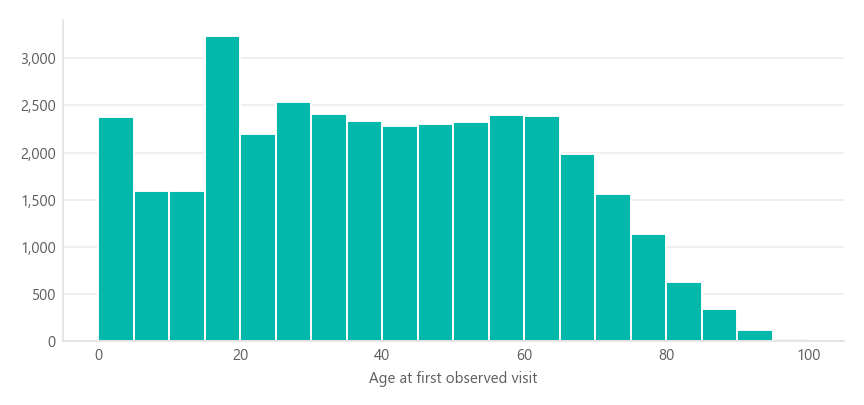
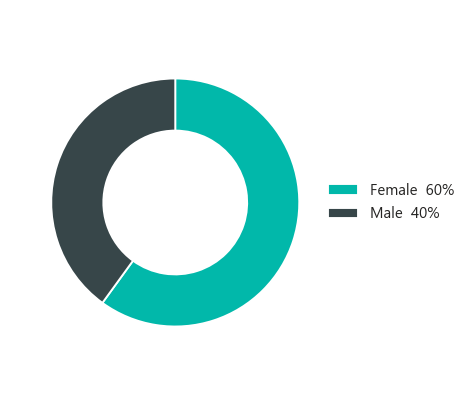
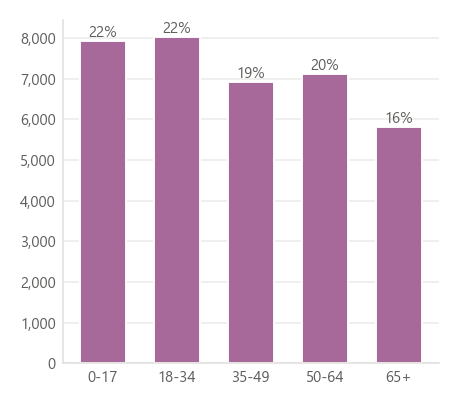
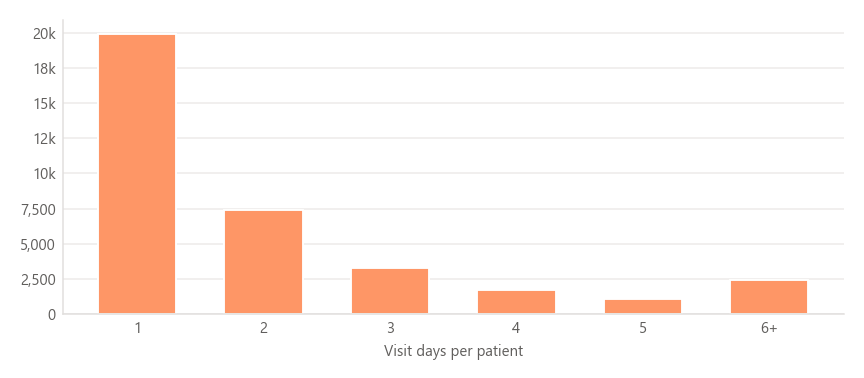
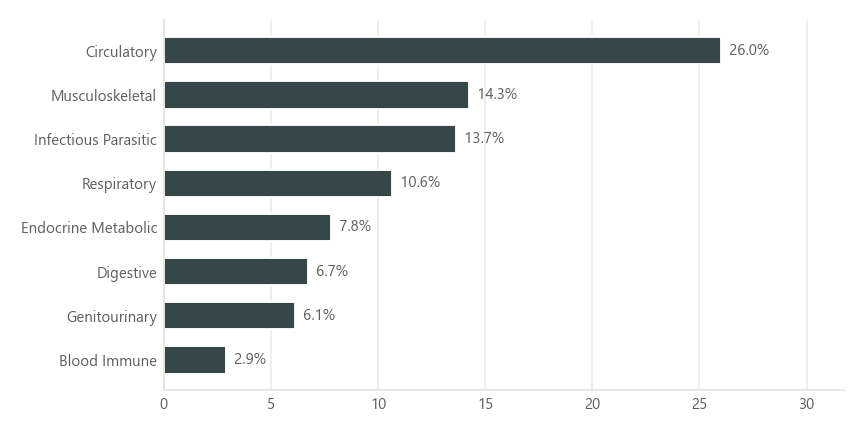
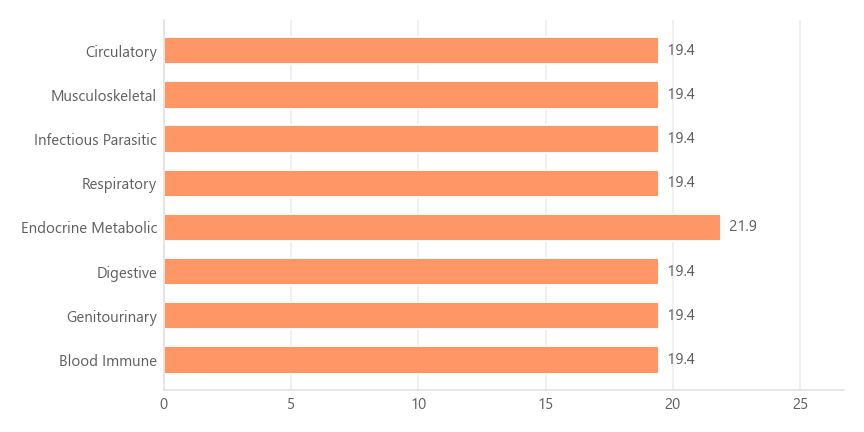
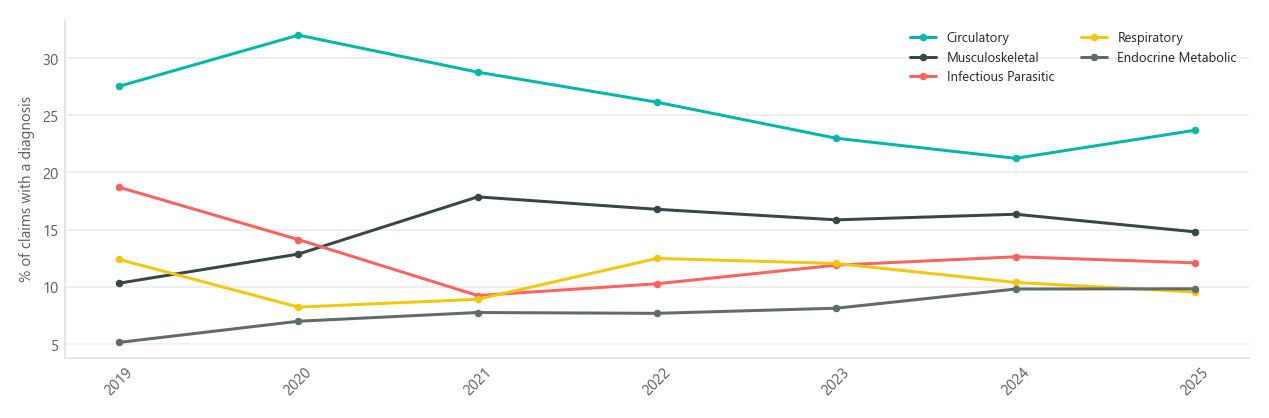
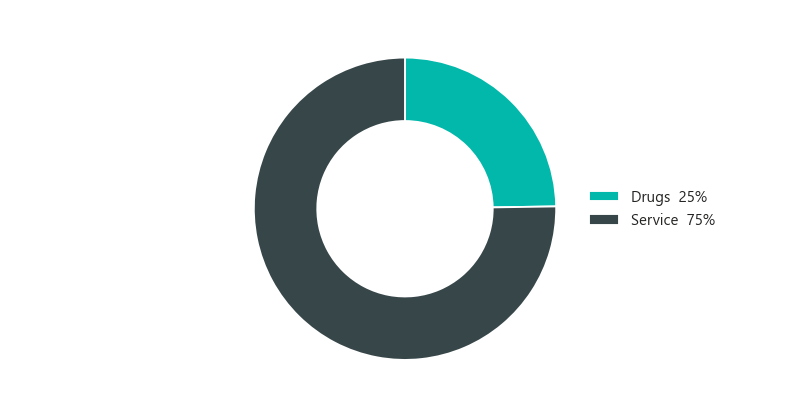
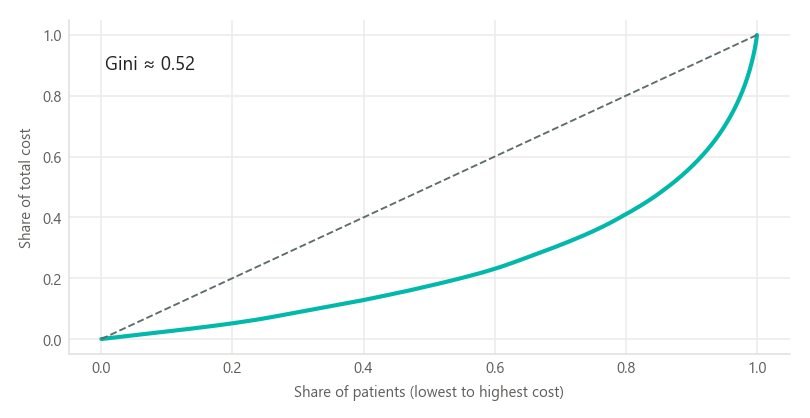
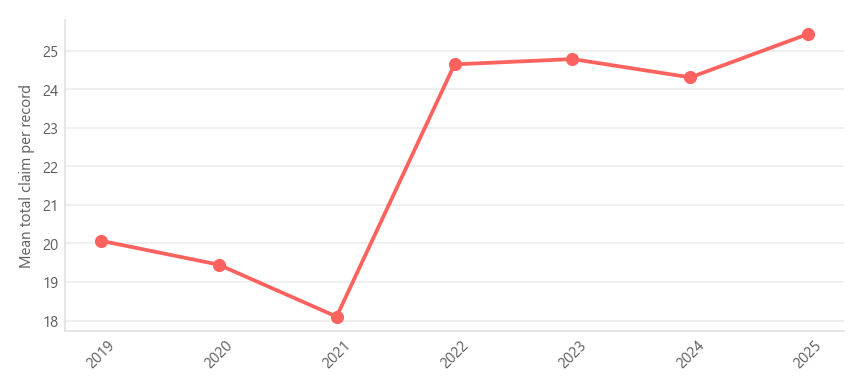
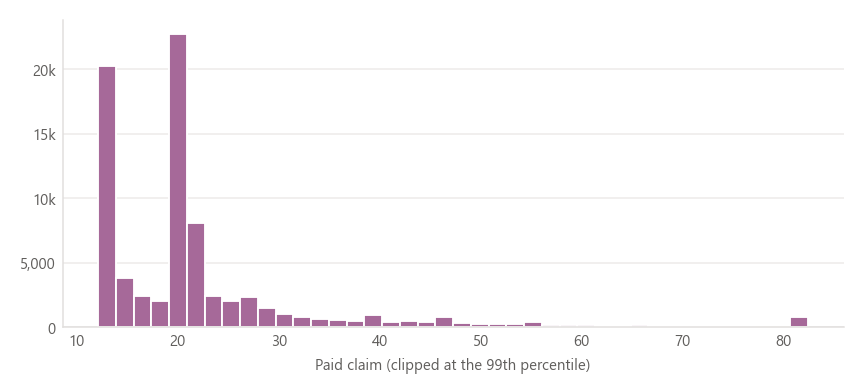
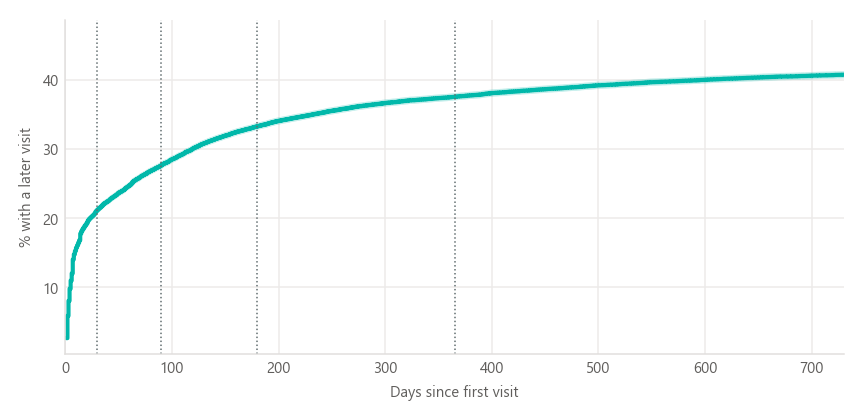
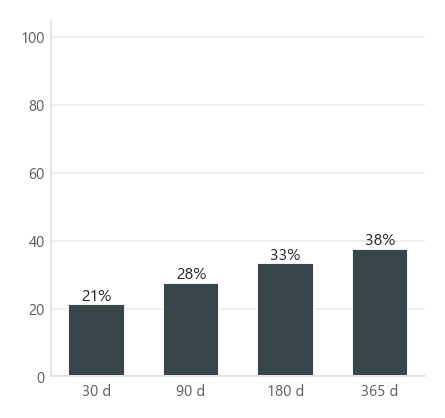
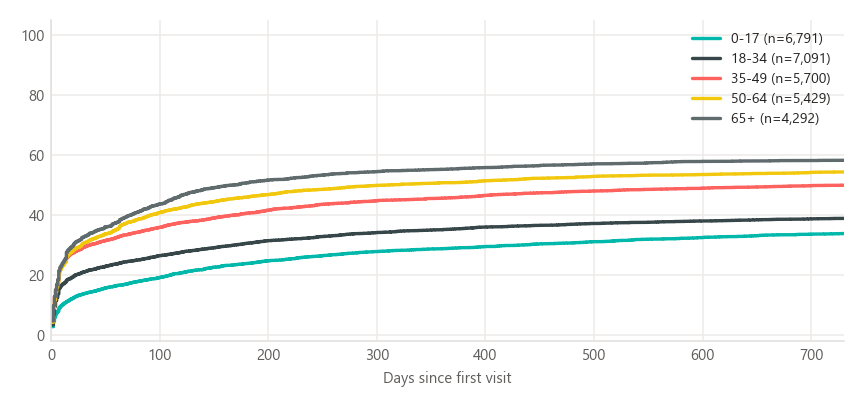
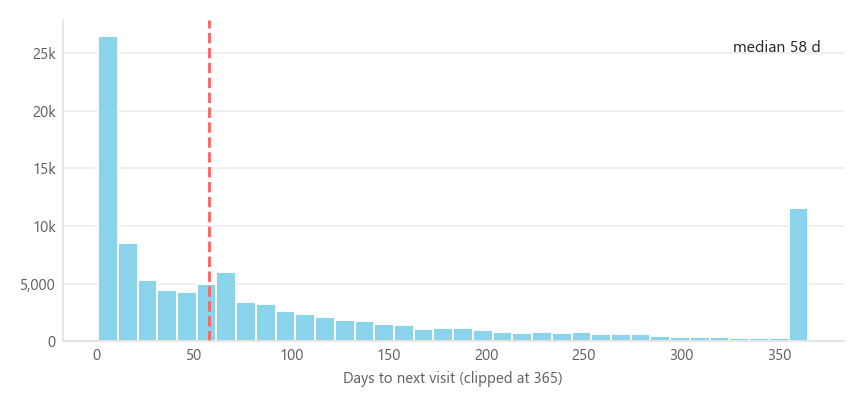
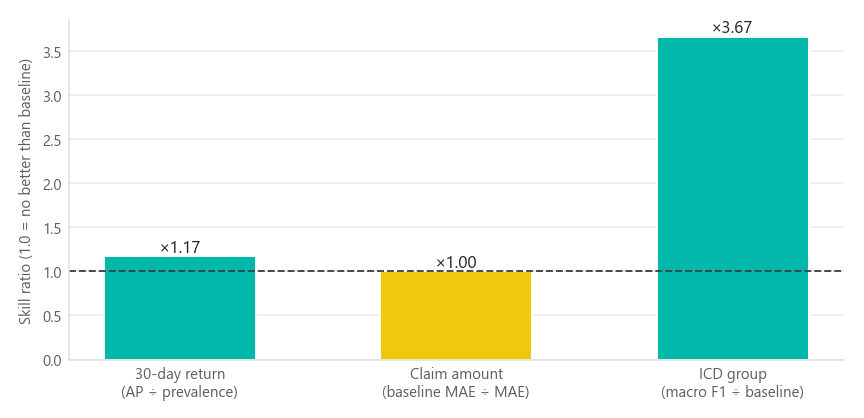
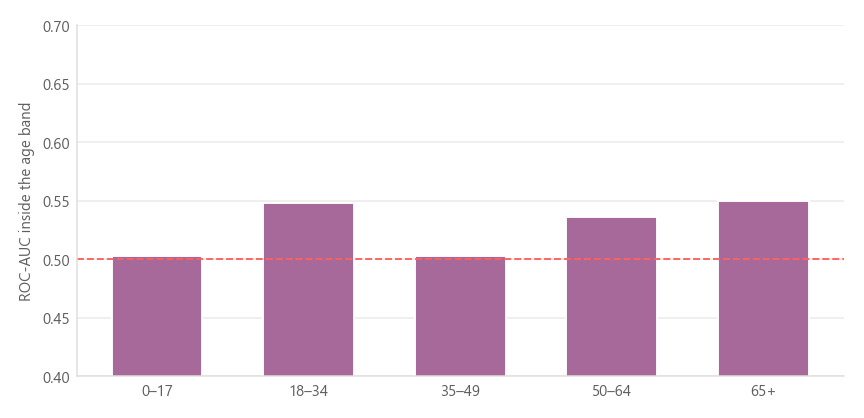
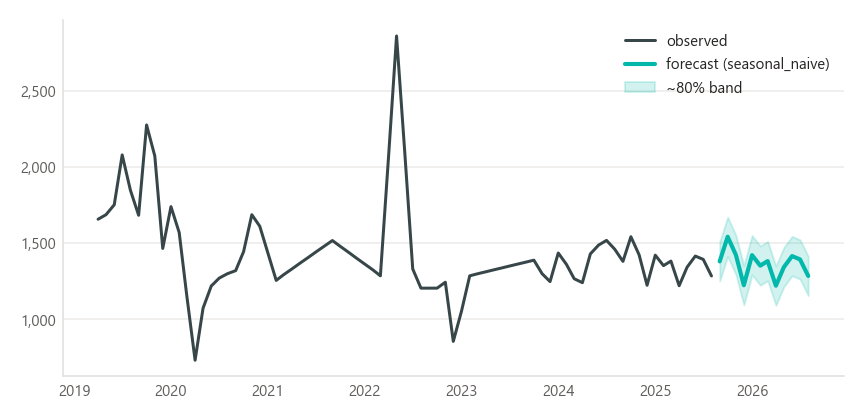
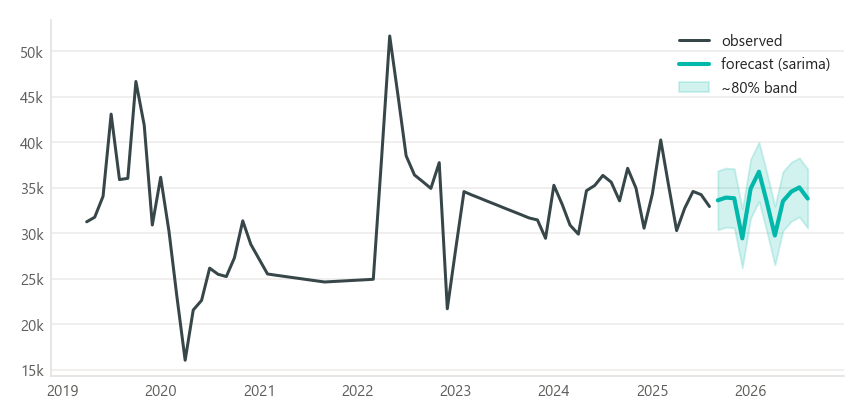
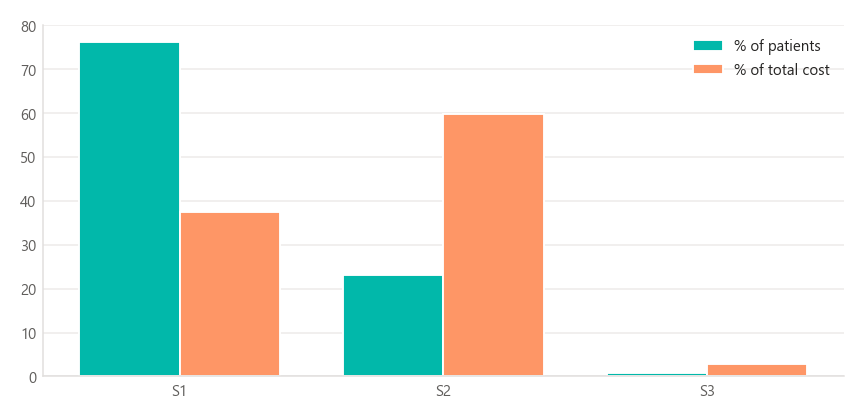
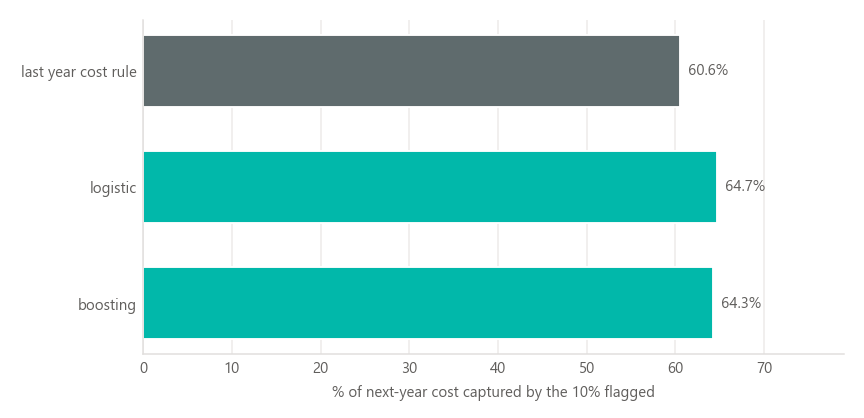
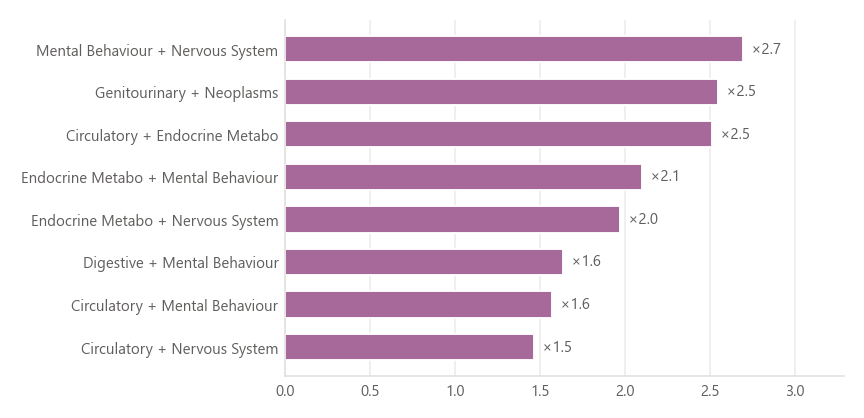
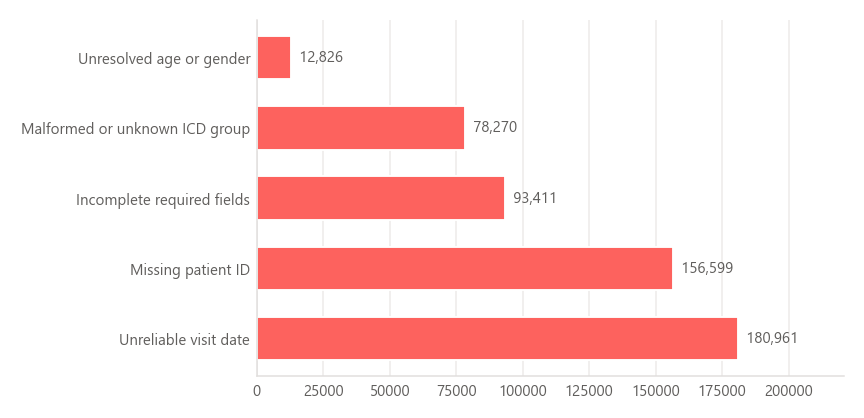
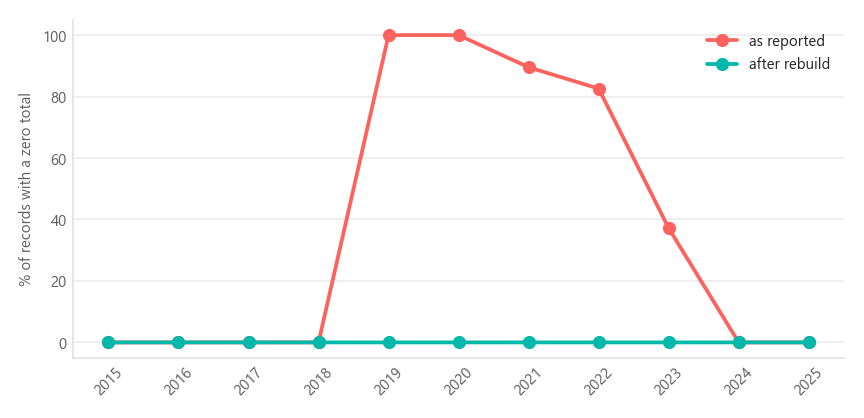
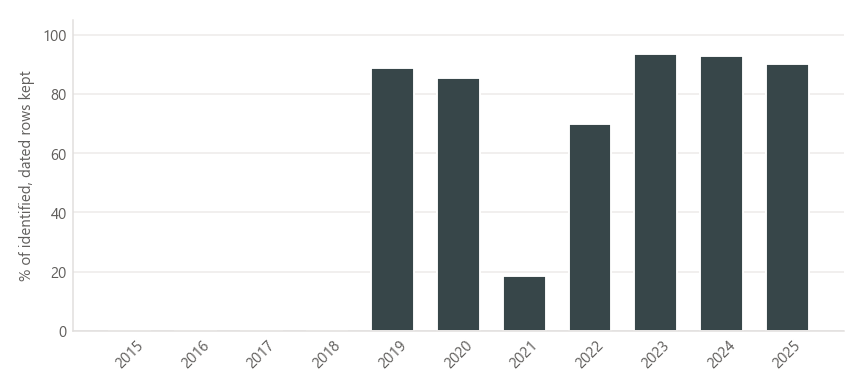

Dashboard: 10 sections · scroll inside the frame above · full-screen copy saved to C:\Users\nagat\OneDrive\Desktop\final _project\outputs\dashboard\carelytics_dashboard.html


In [141]:
# Carelytics dashboard: a scrollable, Power BI-style report built from the results computed above.
# Every figure comes from this notebook's own variables (nothing is typed in); a section whose inputs are missing is skipped.
import io, base64, html as _dhtml
from matplotlib.ticker import FuncFormatter

PB = dict(ink='#252423', mute='#605E5C', line='#E1DFDD', navy='#1B2A41', teal='#01B8AA', slate='#374649', red='#FD625E',
          gold='#F2C80F', steel='#5F6B6D', sky='#8AD4EB', orange='#FE9666', plum='#A66999')
PB_CYCLE = [PB[k] for k in ['teal', 'slate', 'red', 'gold', 'steel', 'sky', 'orange', 'plum']]
PB_RC = {'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'text.color': PB['ink'],
         'axes.labelcolor': PB['mute'], 'axes.titlecolor': PB['ink'], 'axes.edgecolor': PB['line'], 'axes.grid': False,
         'xtick.color': PB['mute'], 'ytick.color': PB['mute'], 'axes.spines.top': False, 'axes.spines.right': False,
         'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'Arial', 'DejaVu Sans'], 'legend.frameon': False,
         'axes.prop_cycle': mpl.cycler(color=PB_CYCLE)}
G = globals()
DASH_OUT = PROJECT / 'outputs' / 'dashboard'
DASH_OUT.mkdir(parents=True, exist_ok=True)

def _ld(name):
    p_ = MODEL_OUT / name
    return pd.read_csv(p_) if p_.exists() else None

def _k(v, _=None):
    v = float(v)
    return f'{v / 1e6:.1f}M' if abs(v) >= 1e6 else (f'{v / 1e3:.0f}k' if abs(v) >= 1e4 else f'{v:,.0f}')

def _clean(ax, grid='y'):
    ax.spines['left'].set_color(PB['line']); ax.spines['bottom'].set_color(PB['line'])
    ax.tick_params(labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color='#EDEBE9', lw=.8); ax.set_axisbelow(True)

def _img(draw, size=(6.0, 3.1), alt=''):
    try:
        with plt.rc_context(PB_RC):
            fig, ax = plt.subplots(figsize=size)
            draw(ax)
            fig.tight_layout()
            buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=135); plt.close(fig)
        return f'<img alt="{_dhtml.escape(alt)}" src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}"/>'
    except Exception as e:
        plt.close('all')
        return f'<div class="na">Not available: {_dhtml.escape(type(e).__name__ + ": " + str(e)[:90])}</div>'

def _card(title, body, span=1):
    return f'<div class="card s{span}"><div class="t">{_dhtml.escape(title)}</div>{body}</div>'

def _kpi(label, value, note='', color=None):
    return (f'<div class="kpi" style="--c:{color or PB["teal"]}"><div class="l">{_dhtml.escape(str(label))}</div>'
            f'<div class="v">{_dhtml.escape(str(value))}</div><div class="n">{_dhtml.escape(str(note))}</div></div>')

def _tile(label, headline, sub, lines, tone, verdict):
    col = {'good': PB['teal'], 'mixed': PB['gold'], 'poor': PB['red']}[tone]
    body = ''.join(f'<div class="ln">{_dhtml.escape(x)}</div>' for x in lines)
    return (f'<div class="kpi tall" style="--c:{col}"><div class="l">{_dhtml.escape(label)}</div><div class="v">{_dhtml.escape(headline)}</div>'
            f'<div class="n">{_dhtml.escape(sub)}</div>{body}<span class="badge" style="background:{col}">{_dhtml.escape(verdict)}</span></div>')

def _hbar(ax, labels, values, color, fmt='{:,.0f}'):
    y_ = np.arange(len(labels))[::-1]
    ax.barh(y_, values, color=color, height=.62)
    ax.set_yticks(y_); ax.set_yticklabels(labels, fontsize=8)
    for yy, v in zip(y_, values): ax.text(v, yy, '  ' + fmt.format(v), va='center', fontsize=8, color=PB['mute'])
    ax.set_xlim(0, max(max(values), 1e-9) * 1.22); _clean(ax, 'x')

def _donut(ax, labels, values):
    values = np.asarray(values, float)
    ax.pie(values, colors=PB_CYCLE[:len(values)], startangle=90, counterclock=False, wedgeprops=dict(width=.42, edgecolor='white'))
    ax.legend([f'{l}  {v / values.sum():.0%}' for l, v in zip(labels, values)], loc='center left', bbox_to_anchor=(.95, .5), fontsize=8)
    ax.set_aspect('equal')

# ------------------------------------------------------------------ data
D = df.copy()
D['year'] = D.visit_date.dt.year
paid = D.loc[D.total_claim.gt(0), 'total_claim']
by_pat = D.sort_values('visit_date').drop_duplicates('patient_id')
n_days = len(D.drop_duplicates(['patient_id', 'visit_date']))
mon = D.groupby(D.visit_date.dt.to_period('M')).size(); mon.index = mon.index.to_timestamp(); mon = mon.asfreq('MS')
known = D[~D.disease_category.isin(['UNKNOWN', 'UNMAPPED'])]
ret30 = None
try: ret30 = float(G['ret_km'].loc[G['ret_km'].days.eq(30), 'returned_pct'].iloc[0])
except Exception: pass
SECTIONS = []

# ------------------------------------------------------------------ 1 overview
kp = ''.join([
    _kpi('Claim records', f'{len(D):,}', 'analysis-ready'),
    _kpi('Patients', f'{D.patient_id.nunique():,}', 'identified', PB['slate']),
    _kpi('Patient-days', f'{n_days:,}', 'distinct visit days', PB['sky']),
    _kpi('Period', f'{D.visit_date.min():%b %Y} – {D.visit_date.max():%b %Y}', 'reliable visit dates', PB['gold']),
    _kpi('Total claimed', _k(D.total_claim.sum()), 'source units', PB['orange']),
    _kpi('Median paid claim', f'{paid.median():,.1f}', f'{len(paid) / len(D):.0%} of records above zero', PB['plum']),
    _kpi('Later visit within 30 days', f'{ret30:.1f}%' if ret30 is not None else 'n/a', 'Kaplan–Meier, first visits', PB['red']),
    _kpi('Source rows kept', f'{len(D) / len(raw):.1%}', f'{len(D):,} of {len(raw):,}', PB['steel'])])
yr = D.groupby('year').size()
def d_year(ax):
    b = ax.bar(yr.index.astype(str), yr.values, color=PB['teal'], width=.65)
    for r_, v in zip(b, yr.values): ax.text(r_.get_x() + r_.get_width() / 2, v, _k(v), ha='center', va='bottom', fontsize=8, color=PB['mute'])
    ax.yaxis.set_major_formatter(FuncFormatter(_k)); ax.tick_params(axis='x', rotation=45); _clean(ax)
def d_funnel(ax):
    st = G['stages']; _hbar(ax, [s_[0] for s_ in st], [s_[1] for s_ in st], PB['slate'])
SECTIONS.append(('overview', 'Overview', 'Overview', 'Headline figures for the analysis dataset',
                 f'<div class="grid">{kp}</div><div class="grid">' + _card('Claim records per year', _img(d_year, (6.4, 3.0)), 2)
                 + _card('From source file to analysis dataset', _img(d_funnel, (6.4, 3.0)), 2) + '</div>'))

# ------------------------------------------------------------------ 2 volume
def d_monthly(ax):
    ax.fill_between(mon.index, mon.fillna(0).values, color=PB['teal'], alpha=.15)
    ax.plot(mon.index, mon.values, color=PB['teal'], lw=1.5, label='monthly claims')
    ax.plot(mon.index, mon.rolling(12, min_periods=6).mean(), color=PB['slate'], lw=2, label='12-month average')
    ax.yaxis.set_major_formatter(FuncFormatter(_k)); ax.legend(fontsize=8); _clean(ax)
mm = mon.dropna().groupby(mon.dropna().index.month).mean()
def d_season(ax):
    idx = mm / mm.mean() * 100
    ax.bar([calendar.month_abbr[m_] for m_ in idx.index], idx.values - 100, bottom=100, color=[PB['teal'] if v >= 100 else PB['steel'] for v in idx.values], width=.65)
    ax.axhline(100, color=PB['slate'], lw=1, ls='--'); ax.set_ylim(min(idx.min() - 4, 96), max(idx.max() + 4, 104))
    ax.set_ylabel('Index (100 = average month)', fontsize=8); ax.tick_params(axis='x', labelsize=7); _clean(ax)
wd = D.visit_date.dt.dayofweek.value_counts().reindex(range(7), fill_value=0)
def d_weekday(ax):
    ax.bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], wd.values, color=PB['sky'], width=.65)
    ax.yaxis.set_major_formatter(FuncFormatter(_k)); _clean(ax)
SECTIONS.append(('volume', 'Volume', 'Volume and seasonality', 'How many claims arrive, and when',
                 '<div class="grid">' + _card('Monthly claim records', _img(d_monthly, (9.4, 3.1)), 3) + _card('Seasonality index', _img(d_season, (3.3, 3.1)), 1)
                 + _card('Claims by weekday', _img(d_weekday, (6.4, 2.8)), 2)
                 + _card('Read this as', '<div class="note">Yearly and monthly counts reflect <b>source coverage</b> as well as demand: years with many undated or unidentified rows look smaller. See the data-quality section.</div>', 2) + '</div>'))

# ------------------------------------------------------------------ 3 patients
def d_age(ax):
    ax.hist(by_pat.age.dropna(), bins=range(0, 101, 5), color=PB['teal'], edgecolor='white'); ax.set_xlabel('Age at first observed visit', fontsize=8); ax.yaxis.set_major_formatter(FuncFormatter(_k)); _clean(ax)
gc = by_pat.gender.value_counts()
def d_gender(ax): _donut(ax, [{'F': 'Female', 'M': 'Male'}.get(x, nice(x)) for x in gc.index], gc.values)
ag = pd.cut(by_pat.age, AGE_BINS, labels=AGE_LABELS, right=False).value_counts().reindex(AGE_LABELS)
def d_agegrp(ax):
    b = ax.bar(AGE_LABELS, ag.values, color=PB['plum'], width=.62)
    for r_, v in zip(b, ag.values): ax.text(r_.get_x() + r_.get_width() / 2, v, f'{v / ag.sum():.0%}', ha='center', va='bottom', fontsize=8, color=PB['mute'])
    ax.yaxis.set_major_formatter(FuncFormatter(_k)); _clean(ax)
vpp = D.groupby('patient_id').visit_date.nunique().clip(upper=6).value_counts().sort_index()
def d_vpp(ax):
    ax.bar([str(i_) if i_ < 6 else '6+' for i_ in vpp.index], vpp.values, color=PB['orange'], width=.62)
    ax.set_xlabel('Visit days per patient', fontsize=8); ax.yaxis.set_major_formatter(FuncFormatter(_k)); _clean(ax)
SECTIONS.append(('patients', 'Patients', 'Patients', 'Who the identified patients are',
                 '<div class="grid">' + _card('Age distribution', _img(d_age, (6.4, 3.0)), 2) + _card('Gender', _img(d_gender, (3.4, 3.0)), 1)
                 + _card('Age group', _img(d_agegrp, (3.4, 3.0)), 1) + _card('Visit days per patient', _img(d_vpp, (6.4, 2.8)), 2)
                 + _card('Note', f'<div class="note">Age is known for {by_pat.age.notna().mean():.0%} of these patients. Gender and age come from the first observed record.</div>', 2) + '</div>'))

# ------------------------------------------------------------------ 4 diagnoses
topc = known.disease_category.value_counts().head(8)
def d_topdx(ax): _hbar(ax, [nice(x)[:30] for x in topc.index], topc.values / len(known) * 100, PB['slate'], '{:.1f}%')
medc = known[known.total_claim.gt(0)].groupby('disease_category').total_claim.median().reindex(topc.index)
def d_meddx(ax): _hbar(ax, [nice(x)[:30] for x in medc.index], medc.fillna(0).values, PB['orange'], '{:,.1f}')
top5 = topc.index[:5]
def d_dxyear(ax):
    ct = pd.crosstab(known.year, known.disease_category)
    ct = ct[ct.sum(axis=1) >= 200]
    sh = (ct.div(ct.sum(axis=1), axis=0) * 100)[list(top5)]
    for c_ in sh.columns: ax.plot(sh.index, sh[c_], marker='o', ms=3, lw=1.6, label=nice(c_)[:22])
    ax.set_xticks(sh.index); ax.tick_params(axis='x', rotation=45); ax.set_ylabel('% of claims with a diagnosis', fontsize=8); ax.legend(fontsize=7, ncol=2); _clean(ax)
SECTIONS.append(('diagnoses', 'Diagnoses', 'Diagnoses', 'ICD chapter of the first listed code (syntax-based, not clinically validated)',
                 '<div class="grid">' + _card('Most frequent ICD chapters', _img(d_topdx, (6.4, 3.2)), 2) + _card('Median paid claim by chapter', _img(d_meddx, (6.4, 3.2)), 2)
                 + _card('Top-5 chapter share by year', _img(d_dxyear, (9.4, 3.1)), 3)
                 + _card('Note', f'<div class="note">{known.shape[0] / len(D):.0%} of records carry a known chapter; {D.multi_chapter.mean():.0%} list codes from more than one chapter.</div>', 1) + '</div>'))

# ------------------------------------------------------------------ 5 cost
ccols = [c_ for c_ in comp_cols if c_ in D.columns and D[c_].nunique() > 1 and D[c_].sum() > 0]
def d_mix(ax): _donut(ax, [nice(c_.replace('_amount', '')) for c_ in ccols], [D[c_].sum() for c_ in ccols])
pc = D.groupby('patient_id').total_claim.sum().sort_values()
def d_lorenz(ax):
    cum = pc.cumsum() / max(pc.sum(), 1e-9); xx = np.arange(1, len(pc) + 1) / len(pc); gini = 1 - 2 * float(cum.mean())
    ax.plot(np.r_[0, xx], np.r_[0, cum.values], color=PB['teal'], lw=2.2); ax.plot([0, 1], [0, 1], ls='--', color=PB['steel'], lw=1)
    ax.text(.05, .85, f'Gini ≈ {gini:.2f}', fontsize=10, color=PB['ink'], transform=ax.transAxes)
    ax.set_xlabel('Share of patients (lowest to highest cost)', fontsize=8); ax.set_ylabel('Share of total cost', fontsize=8); _clean(ax, 'both')
my = D.groupby('year').total_claim.mean()
def d_meanyr(ax):
    ax.plot(my.index, my.values, marker='o', color=PB['red'], lw=2); ax.set_xticks(my.index); ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel('Mean total claim per record', fontsize=8); _clean(ax)
def d_paid(ax):
    ax.hist(paid.clip(upper=paid.quantile(.99)), bins=40, color=PB['plum'], edgecolor='white'); ax.set_xlabel('Paid claim (clipped at the 99th percentile)', fontsize=8)
    ax.yaxis.set_major_formatter(FuncFormatter(_k)); _clean(ax)
SECTIONS.append(('cost', 'Cost', 'Cost', 'Source units; totals reported as zero while components were positive were rebuilt (flagged upstream)',
                 '<div class="grid">' + _card('Cost by component', _img(d_mix, (6.0, 3.1)), 2) + _card('Cost concentration (Lorenz curve)', _img(d_lorenz, (6.0, 3.1)), 2)
                 + _card('Mean total claim per record by year', _img(d_meanyr, (6.4, 2.9)), 2) + _card('Paid-claim distribution', _img(d_paid, (6.4, 2.9)), 2) + '</div>'))

# ------------------------------------------------------------------ 6 return and retention
secret = ''
if 'overall' in G and 'ret_km' in G:
    ov = G['overall']; rk = G['ret_km']
    def d_km(ax):
        ax.step(ov.t, (1 - ov.S) * 100, where='post', color=PB['teal'], lw=2.2)
        ax.fill_between(ov.t, (1 - ov.hi) * 100, (1 - ov.lo) * 100, step='post', color=PB['teal'], alpha=.2)
        for h_ in rk.days: ax.axvline(h_, ls=':', color=PB['steel'], lw=.8)
        ax.set_xlim(0, 730); ax.set_xlabel('Days since first visit', fontsize=8); ax.set_ylabel('% with a later visit', fontsize=8); _clean(ax, 'both')
    def d_rkbar(ax):
        b = ax.bar([f'{int(h_)} d' for h_ in rk.days], rk.returned_pct, color=PB['slate'], width=.6)
        for r_, v in zip(b, rk.returned_pct): ax.text(r_.get_x() + r_.get_width() / 2, v, f'{v:.0f}%', ha='center', va='bottom', fontsize=8.5)
        ax.set_ylim(0, 105); _clean(ax)
    def d_kmage(ax):
        fr = G['first']
        for i_, g_ in enumerate([x for x in AGE_LABELS if (fr.age_group == x).sum() > 30]):
            s_ = fr[fr.age_group == g_]; c_ = G['km_curve'](s_.time, s_.event)
            ax.step(c_.t, (1 - c_.S) * 100, where='post', lw=1.8, label=f'{g_} (n={len(s_):,})')
        ax.set_xlim(0, 730); ax.legend(fontsize=7.5); ax.set_xlabel('Days since first visit', fontsize=8); _clean(ax, 'both')
    gaps = G['episodes'].days_to_next_visit.dropna()
    def d_gap(ax):
        ax.hist(gaps.clip(upper=365), bins=36, color=PB['sky'], edgecolor='white'); ax.axvline(gaps.median(), color=PB['red'], ls='--')
        ax.text(.97, .9, f'median {gaps.median():.0f} d', transform=ax.transAxes, ha='right', fontsize=8.5); ax.set_xlabel('Days to next visit (clipped at 365)', fontsize=8)
        ax.yaxis.set_major_formatter(FuncFormatter(_k)); _clean(ax)
    secret = ('<div class="grid">' + _card('Probability of a later visit (Kaplan–Meier)', _img(d_km, (6.4, 3.1)), 2)
              + _card('Later visit by horizon', _img(d_rkbar, (3.3, 3.1)), 1) + _card('By age group', _img(d_kmage, (6.4, 3.0)), 2)
              + _card('Gap between visits', _img(d_gap, (6.4, 3.0)), 2) + '</div>')
    SECTIONS.append(('returns', 'Returns', 'Return behaviour', 'Observed later visit days (not inpatient readmission); censoring-aware', secret))

# ------------------------------------------------------------------ 7 models
ret_t, cst_t, dx_t = _ld('test_metrics.csv'), _ld('cost_test_metrics.csv'), _ld('diagnosis_test_metrics.csv')
if all(v is not None for v in (ret_t, cst_t, dx_t)):
    r_base_ = ret_t.loc[ret_t.model.eq('flag_everyone_baseline')].iloc[0]; r_mod_ = ret_t.loc[ret_t.model.str.endswith('_calibrated')].iloc[0]
    c_mod_ = cst_t.iloc[0]; c_base_ = cst_t.loc[cst_t.model.eq('median_baseline')].iloc[0]
    d_mod_ = dx_t.iloc[0]; d_base_ = dx_t.loc[dx_t.model.eq('most_frequent_baseline')].iloc[0]
    auc_, ap_, prev_ = float(r_mod_.ROC_AUC), float(r_mod_.AP), float(r_mod_.prevalence)
    c_gain_ = 1 - float(c_mod_.MAE) / float(c_base_.MAE)
    tiles = ''.join([
        _tile('Observed 30-day return', f'AUC {auc_:.3f}', 'ROC-AUC on the locked test period',
              [f'Average precision {ap_:.3f} vs prevalence {prev_:.3f}', f'Flags {float(r_mod_.flagged_fraction):.0%} of patient-days, lift ×{float(r_mod_.lift):.2f}'],
              'poor' if auc_ < .6 else ('mixed' if auc_ < .7 else 'good'), 'Limited signal' if auc_ < .6 else ('Modest signal' if auc_ < .7 else 'Useful signal')),
        _tile('Daily claim amount', f'MAE {float(c_mod_.MAE):,.2f}', 'source units, locked test period',
              [f'Median baseline {float(c_base_.MAE):,.2f} ({c_gain_:+.0%})', f'R² {float(c_mod_.R2):.3f}'],
              'poor' if c_gain_ < 0 else ('mixed' if c_gain_ < .05 else 'good'), 'Worse than baseline' if c_gain_ < 0 else ('Marginal gain' if c_gain_ < .05 else 'Better than baseline')),
        _tile('ICD group', f'F1 {float(d_mod_.macro_F1):.3f}', 'macro F1, locked test period',
              [f'Majority baseline {float(d_base_.macro_F1):.3f}', f'Accuracy {float(d_mod_.accuracy):.1%} vs {float(d_base_.accuracy):.1%}'],
              'good' if (d_mod_.macro_F1 > d_base_.macro_F1 and d_mod_.accuracy > d_base_.accuracy) else ('mixed' if d_mod_.macro_F1 > d_base_.macro_F1 else 'poor'),
              'Better than baseline' if (d_mod_.macro_F1 > d_base_.macro_F1 and d_mod_.accuracy > d_base_.accuracy) else ('Mixed result' if d_mod_.macro_F1 > d_base_.macro_F1 else 'Worse than baseline'))])
    skill = {'30-day return\n(AP ÷ prevalence)': ap_ / prev_, 'Claim amount\n(baseline MAE ÷ MAE)': float(c_base_.MAE) / max(float(c_mod_.MAE), 1e-9),
             'ICD group\n(macro F1 ÷ baseline)': float(d_mod_.macro_F1) / max(float(d_base_.macro_F1), 1e-9)}
    def d_skill(ax):
        b = ax.bar(list(skill), list(skill.values()), color=[PB['teal'] if v > 1.05 else (PB['gold'] if v >= 1 else PB['red']) for v in skill.values()], width=.55)
        for r_, v in zip(b, skill.values()): ax.text(r_.get_x() + r_.get_width() / 2, v, f'×{v:.2f}', ha='center', va='bottom', fontsize=9)
        ax.axhline(1, color=PB['slate'], ls='--', lw=1); ax.set_ylabel('Skill ratio (1.0 = no better than baseline)', fontsize=8); ax.tick_params(axis='x', labelsize=8); _clean(ax)
    sg = _ld('subgroup_metrics.csv')
    def d_sub(ax):
        s_ = sg[sg.dimension.eq('age_band')]
        ax.bar(s_.group.astype(str), s_.ROC_AUC, color=PB['plum'], width=.6); ax.axhline(.5, color=PB['red'], ls='--', lw=1)
        ax.set_ylim(.4, .7); ax.set_ylabel('ROC-AUC inside the age band', fontsize=8); _clean(ax)
    if 'hc' in G and 'last_year_cost_rule' in G['hc'].index:
        _hcm = G['hc']; _bn = _hcm.loc[['logistic', 'boosting']].AP.idxmax(); _cap, _rule = float(_hcm.loc[_bn, 'future_cost_captured_pct']), float(_hcm.loc['last_year_cost_rule', 'future_cost_captured_pct'])
        tiles += _tile('High-cost patients', f'{_cap:.0f}% captured', 'next-year cost in the 10% flagged, test snapshot',
                       [f'Best model: {_bn}', f'Rule "rank by last-year cost": {_rule:.0f}%'], 'good' if _cap > _rule * 1.1 else ('mixed' if _cap >= _rule else 'poor'),
                       'Beats the simple rule' if _cap > _rule * 1.1 else ('Close to the rule' if _cap >= _rule else 'Worse than the rule'))
    mod_cards = '<div class="grid">' + tiles + '</div><div class="grid">' + _card('Model skill versus the simple baseline', _img(d_skill, (6.4, 3.1)), 2)
    if sg is not None and (sg.dimension == 'age_band').any(): mod_cards += _card('30-day return: ranking ability inside age bands', _img(d_sub, (6.4, 3.1)), 2)
    mod_cards += '</div>'
    SECTIONS.append(('models', 'Models', 'Predictive models', 'Research benchmarks on a locked, later test period — not validated for operational or clinical use', mod_cards))

# ------------------------------------------------------------------ 8 forecast
if 'monthly' in G and 'fc_rows' in G and len(G['fc_rows']) == 2:
    def _fc(series_name, fc_df):
        def draw(ax):
            s_ = G['monthly'][series_name]
            ax.plot(s_.index, s_.values, color=PB['slate'], lw=1.6, label='observed')
            ax.plot(fc_df.month, fc_df.forecast, color=PB['teal'], lw=2.2, label=f'forecast ({fc_df.method.iloc[0]})')
            ax.fill_between(fc_df.month, fc_df.lower_80, fc_df.upper_80, color=PB['teal'], alpha=.18, label='~80% band')
            ax.yaxis.set_major_formatter(FuncFormatter(_k)); ax.legend(fontsize=8); _clean(ax)
        return draw
    SECTIONS.append(('forecast', 'Forecast', 'Next 12 months', 'Hold-out-validated forecasts; they assume source coverage stays the same',
                     '<div class="grid">' + _card('Monthly claim records', _img(_fc('claims', G['fc_rows'][0]), (6.4, 3.1)), 2) + _card('Monthly total claimed', _img(_fc('cost', G['fc_rows'][1]), (6.4, 3.1)), 2) + '</div>'))

# ------------------------------------------------------------------ 9 risk and structure
risk = ''
if 'profile' in G:
    pf = G['profile']
    def d_seg(ax):
        xs = np.arange(len(pf)); w = .38
        ax.bar(xs - w / 2, pf.patients_pct, w, color=PB['teal'], label='% of patients'); ax.bar(xs + w / 2, pf.cost_share_pct, w, color=PB['orange'], label='% of total cost')
        ax.set_xticks(xs); ax.set_xticklabels(pf.index); ax.legend(fontsize=8); _clean(ax)
    risk += _card('Patient segments: who generates the cost', _img(d_seg, (6.4, 3.1)), 2)
if 'hc' in G:
    hcm = G['hc']
    def d_hc(ax):
        names = [n_ for n_ in hcm.index if n_ != 'prevalence_baseline']
        vals = hcm.loc[names, 'future_cost_captured_pct'].values
        _hbar(ax, [n_.replace('_', ' ') for n_ in names], vals, [PB['steel'] if 'rule' in n_ else PB['teal'] for n_ in names], '{:.1f}%')
        ax.set_xlabel('% of next-year cost captured by the 10% flagged', fontsize=8)
    risk += _card('High-cost detection versus a simple rule', _img(d_hc, (6.4, 3.1)), 2)
if 'pairs' in G and len(G['pairs']):
    pr = G['pairs']; pr = (pr[pr.robust] if ('robust' in pr and pr.robust.any()) else pr).head(8)
    def d_pairs(ax): _hbar(ax, [f'{nice(a_)[:16]} + {nice(b_)[:16]}' for a_, b_ in zip(pr.A, pr.B)], pr.lift.values, PB['plum'], '×{:.1f}')
    risk += _card('Diagnosis pairs that occur together (lift)', _img(d_pairs, (6.4, 3.1)), 2)
if 'n_flagged' in G:
    risk += _card('Claims for review', f'<div class="bignum">{G["n_flagged"]:,}</div><div class="note">claims form the top-{G["REVIEW_RATE"]:.0%} anomaly review list out of {G["n_paid_claims"]:,} paid claims. This is a ranking for human review, not a finding of error.</div>', 2)
if risk: SECTIONS.append(('risk', 'Risk', 'Risk and structure', 'Segments, high-cost patients, comorbidity and review list', '<div class="grid">' + risk + '</div>'))

# ------------------------------------------------------------------ 10 data quality
dq = ''
if 'reason_counts' in G:
    rc_ = G['reason_counts']
    def d_reason(ax): _hbar(ax, list(rc_.index), rc_.values, PB['red'])
    dq += _card('Why records were excluded (a row can have several reasons)', _img(d_reason, (6.4, 3.1)), 2)
if 'integrity' in G:
    ig = G['integrity']
    def d_zero(ax):
        ax.plot(ig.index, ig.reported_total_zero_pct, marker='o', color=PB['red'], lw=2, label='as reported'); ax.plot(ig.index, ig.final_total_zero_pct, marker='o', color=PB['teal'], lw=2, label='after rebuild')
        ax.set_xticks(ig.index); ax.tick_params(axis='x', rotation=45); ax.set_ylabel('% of records with a zero total', fontsize=8); ax.legend(fontsize=8); _clean(ax)
    dq += _card('total_claim recorded as zero, before and after the rebuild', _img(d_zero, (6.4, 3.1)), 2)
if 'kept_by_year' in G:
    byy = G['kept_by_year']
    def d_kept(ax):
        ax.bar(byy.index.astype(str), byy.kept_pct, color=PB['slate'], width=.65); ax.set_ylim(0, 105); ax.tick_params(axis='x', rotation=45); ax.set_ylabel('% of identified, dated rows kept', fontsize=8); _clean(ax)
    dq += _card('Share of rows kept by year', _img(d_kept, (6.4, 2.9)), 2)
dq += _card('How to read this dashboard', '<div class="note">Counts describe the complete-case analysis dataset, which keeps only a part of the source file. Model results are research benchmarks. Rerun the notebook to refresh every figure.</div>', 2)
SECTIONS.append(('quality', 'Data quality', 'Data quality', 'What the analysis kept, and what it could not', '<div class="grid">' + dq + '</div>'))

# ------------------------------------------------------------------ assemble
CSS = """
.cld{font-family:'Segoe UI',Arial,sans-serif;background:#EAEAEA;border:1px solid #C8C6C4;border-radius:6px;overflow:hidden;color:#252423}
.cld *{box-sizing:border-box}
.cld .scroll{max-height:900px;overflow-y:auto;scroll-behavior:smooth}
.cld.full{overflow:visible;border:0;border-radius:0}.cld.full .scroll{max-height:none;overflow:visible}
.cld .head{position:sticky;top:0;z-index:5;background:#1B2A41;color:#fff;padding:12px 22px;display:flex;align-items:center;gap:6px;flex-wrap:wrap;box-shadow:0 2px 6px rgba(0,0,0,.25)}
.cld .brand{font-size:18px;font-weight:600;letter-spacing:.3px;margin-right:14px}.cld .brand b{color:#01B8AA}
.cld .head a{color:#C7D1E0;text-decoration:none;font-size:12px;padding:5px 10px;border-radius:3px;cursor:pointer}
.cld .head a:hover{background:#2C3E5E;color:#fff}
.cld .meta{margin-left:auto;font-size:11px;color:#9FB0C8}
.cld .sec{padding:20px 22px 8px}
.cld .sec h3{margin:0;font-size:17px;font-weight:600;border-left:4px solid #01B8AA;padding-left:10px}
.cld .sec p{margin:3px 0 0 14px;font-size:12px;color:#605E5C}
.cld .grid{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:12px;padding:10px 22px 4px}
.cld .card{background:#fff;border:1px solid #E1DFDD;border-radius:4px;padding:10px 12px 8px;box-shadow:0 1px 2px rgba(0,0,0,.07)}
.cld .card .t{font-size:12px;font-weight:600;margin-bottom:6px}
.cld .card img{width:100%;height:auto;display:block}
.cld .s1{grid-column:span 1}.cld .s2{grid-column:span 2}.cld .s3{grid-column:span 3}.cld .s4{grid-column:span 4}
.cld .kpi{background:#fff;border:1px solid #E1DFDD;border-top:4px solid var(--c);border-radius:4px;padding:12px 14px;box-shadow:0 1px 2px rgba(0,0,0,.07)}
.cld .kpi .l{font-size:11px;text-transform:uppercase;letter-spacing:.8px;color:#605E5C}
.cld .kpi .v{font-size:26px;font-weight:600;margin:4px 0 2px;line-height:1.15}
.cld .kpi .n{font-size:11px;color:#605E5C}
.cld .kpi.tall .ln{font-size:12px;margin-top:5px;color:#3B3A39}
.cld .badge{display:inline-block;margin-top:10px;padding:3px 11px;border-radius:999px;color:#252423;font-size:11px;font-weight:600}
.cld .note{font-size:12.5px;line-height:1.6;color:#3B3A39;padding:4px 2px}
.cld .bignum{font-size:42px;font-weight:600;color:#FD625E;padding:6px 2px 0}
.cld .na{font-size:12px;color:#A19F9D;padding:30px 6px;text-align:center}
.cld .foot{padding:14px 22px 22px;font-size:11px;color:#605E5C}
@media(max-width:900px){.cld .grid{grid-template-columns:repeat(2,minmax(0,1fr))}.cld .s3,.cld .s4{grid-column:span 2}}
@media(max-width:560px){.cld .grid{grid-template-columns:1fr}.cld .s2,.cld .s3,.cld .s4{grid-column:span 1}}
"""
nav = ''.join(f'<a href="#cld-{i_}" onclick="var e=document.getElementById(\'cld-{i_}\');if(e){{e.scrollIntoView({{behavior:\'smooth\',block:\'start\'}});}}return false;">{_dhtml.escape(l_)}</a>' for i_, l_, *_ in SECTIONS)
body = ''.join(f'<div class="sec" id="cld-{i_}"><h3>{_dhtml.escape(t_)}</h3><p>{_dhtml.escape(s_)}</p></div>{b_}' for i_, _l, t_, s_, b_ in SECTIONS)
def _page(cls=''):
    return (f'<div class="cld {cls}"><div class="head"><span class="brand"><b>Care</b>lytics</span>{nav}'
            f'<span class="meta">{D.visit_date.min():%b %Y} – {D.visit_date.max():%b %Y} · {D.patient_id.nunique():,} patients</span></div>'
            f'<div class="scroll">{body}<div class="foot">Generated by this notebook from the analysis dataset and saved model results. Findings describe the selected subset and are not clinical or operational guidance.</div></div></div>')
dashboard_html = f'<style>{CSS}</style>' + _page()
(DASH_OUT / 'carelytics_dashboard.html').write_text('<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Carelytics dashboard</title>'
                                                    f'<style>body{{margin:0;background:#EAEAEA}}{CSS}</style></head><body>{_page("full")}</body></html>', encoding='utf-8')
display(HTML(dashboard_html))
print(f'Dashboard: {len(SECTIONS)} sections · scroll inside the frame above · full-screen copy saved to {DASH_OUT / "carelytics_dashboard.html"}')

<div id="carelytics-conclusions" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Conclusions and Next Steps</h2></div>

<div id="conclusions" style="padding:26px 30px;background:#faf5ed;border-left:4px solid #75446e;color:#382d38;font:14px/1.75 Arial">
<h2 style="font:30px Georgia;color:#4a2548;margin:0 0 10px">What this study supports &mdash; and what it does not</h2>
<p><b>Supported.</b> Descriptive findings about the analysis dataset (volume, patients, diagnoses, cost, return behaviour), produced by documented, auditable cleaning. The only value created rather than cleaned is <code>total_claim</code> where the source recorded 0 although its components were positive; those rows are flagged. Statistical tests are reported with Holm-adjusted p-values <em>and</em> effect-size labels, so a significant but negligible difference is called what it is.</p>
<p><b>Not supported.</b> Operational or clinical use of any model. The scorecard compares every model with a simple baseline and states the verdict from the numbers; when a model does not beat its baseline (flag-everyone, median amount, most frequent group, last-year cost, persistence, seasonal naive) that is the finding. Readmission claims, causal claims, and conclusions about the whole source file are also unsupported, because the analysis dataset keeps only the rows that are identified, reliably dated and complete.</p>
<p><b>Next steps, in order.</b></p>
<ol>
<li>Ask the data owner why <code>total_claim</code> was recorded as 0 for much of 2019&ndash;2022, whether total = sum of the five components, and what currency and billing rules apply.</li>
<li>Recover patient IDs and visit dates at source: most source rows have no usable patient ID or date, which limits every patient-level result.</li>
<li>Validate ICD codes against an official release and confirm why more claims list several codes after 2021.</li>
<li>Add predictors with real signal (provider, ward, payer, prior diagnoses and prior costs as of the index date). Age and visit counts alone barely rank patients.</li>
<li>Validate any model on a future period and with clinicians before it informs a decision.</li>
</ol></div>


<div id="carelytics-appendix" style="background:#F2E6D7;border-top:1px solid #9B7B79;border-bottom:1px solid #D5C4C9;padding:24px 28px;margin:28px 0 18px;color:#4A2548;"><div style="font-family:Arial,sans-serif;font-size:10px;letter-spacing:3px;margin-bottom:10px;">CARELYTICS / RESEARCH NOTEBOOK</div><h2 style="font-family:Georgia,serif;font-weight:400;font-size:30px;line-height:1.2;color:#4A2548;margin:0;">Appendix: Data Dictionary, Files and Reproducibility</h2></div>

In [145]:
# Data dictionary for the final analysis dataset (df). Descriptions follow the cleaning code in this notebook.
described = {
    'source_row_id': 'Row number in the source CSV (header = row 1); links back to the audit files.',
    'source_year': 'Year label from the source file or sheet.', 'source_month': 'Month label normalized to full English month names.',
    'source_sheet': 'Source sheet or file part the row was loaded from.', 'load_order': 'Order in which the row was loaded.',
    'patient_id': 'Anonymized patient identifier.', 'visit_date': 'Reliable visit date (conflicts with source year/month were excluded).',
    'discharge_date': 'Discharge date as supplied; never imputed.', 'age': 'Age in years; invalid values were removed, earlier observations may fill gaps (see age_imputed).',
    'age_at_visit': 'Inherited from the source; confirm its definition with the data owner.', 'age_group': 'Age band derived from age.',
    'gender': 'F or M after normalization; conflicting patients are set to Unknown and excluded.', 'diagnosis_text': 'Free-text diagnosis as supplied.',
    'diagnosis_clean': 'Trimmed, upper-cased diagnosis text.', 'icd10': 'Syntactically valid ICD-10 codes, comma separated.',
    'icd10_codes': 'Same as icd10; kept for clarity in downstream tables.', 'icd10_chapter': 'ICD chapter group of the first code.',
    'icd10_chapters': 'All chapter groups found in the record.', 'disease_category': 'ICD chapter of the first listed code. Syntax based, not clinically validated.',
    'disease_categories_all': 'All chapter groups, comma separated.', 'target_disease_fine': 'Fine diagnosis label rebuilt from ICD codes.',
    'target_disease_coarse': 'Coarse diagnosis label (chapter group).', 'drugs_amount': 'Drug charges, source units.',
    'investigation_amount': 'Investigation (tests) charges, source units.', 'outpatient_amount': 'Outpatient charges, source units.',
    'inpatient_amount': 'Inpatient charges, source units.', 'service_amount': 'Service charges, source units.',
    'total_claim': 'Total claim amount, source units; negative values removed. Rebuilt from the five components where the source total was 0 or blank (see total_claim_rebuilt).', 'length_of_stay': 'Days between visit and discharge when both dates are reliable.',
    'total_visits': 'Distinct observed visit days of the patient (retrospective, not a predictor).', 'visits_this_year': 'Distinct observed visit days in that calendar year.',
    'visit_number': 'Sequence number of the observed visit day for the patient.', 'year': 'Calendar year of visit_date.', 'month': 'Calendar month (1–12) of visit_date.',
    'age_imputed': 'True when age was carried forward from an earlier reliable observation.', 'age_conflict': 'True when a patient has conflicting ages.', 'total_claim_rebuilt': 'True when total_claim was rebuilt as the sum of its components.', 'multi_chapter': 'True when the claim lists ICD codes from more than one chapter.'}
dictionary = pd.DataFrame({'column': df.columns, 'type': df.dtypes.astype(str).values, 'non_missing': df.notna().sum().values,
                           'distinct': df.nunique().values,
                           'example': [str(df[c].dropna().iloc[0])[:30] if df[c].notna().any() else '' for c in df.columns],
                           'description': [described.get(c, 'See the cleaning section of this notebook.') for c in df.columns]})
cl_table(dictionary, caption=f'{len(df.columns)} columns · {len(df):,} rows · {int(df[REQUIRED_FIELDS].isna().sum().sum())} missing cells in required fields (discharge date and stay length may be blank).')


column,type,non_missing,distinct,example,description
source_row_id,int64,78026,78026,153547,Row number in the source CSV (header = row 1); links back to the audit files.
source_year,Int64,78026,7,2024,Year label from the source file or sheet.
source_month,string,78026,12,March,Month label normalized to full English month names.
source_sheet,string,78026,26,March 2024,Source sheet or file part the row was loaded from.
load_order,int64,78026,55,102,Order in which the row was loaded.
patient_id,string,78026,35808,000078299e35de5f,Anonymized patient identifier.
visit_date,datetime64[ns],78026,1630,2024-03-07 00:00:00,Reliable visit date (conflicts with source year/month were excluded).
discharge_date,datetime64[ns],78026,1631,2024-03-07 00:00:00,Discharge date as supplied; never imputed.
age,float64,78026,104,26.0,"Age in years; invalid values were removed, earlier observations may fill gaps (see age_imputed)."
age_at_visit,float64,78026,104,26.0,Inherited from the source; confirm its definition with the data owner.


In [146]:
# Output files created by this notebook, with size and last-modified time.
import datetime as _dt
rows = []
for folder in [f_ for f_ in [OUT, MODEL_OUT, globals().get("EXT_OUT"), globals().get("DASH_OUT")] if f_ is not None]:
    for path in sorted(folder.glob('*')):
        if path.is_file():
            rows.append({'folder': folder.relative_to(PROJECT).as_posix(), 'file': path.name,
                         'size_kb': f'{path.stat().st_size / 1024:,.1f}',
                         'modified': _dt.datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')})
cl_table(pd.DataFrame(rows), caption=f'Saved next to the data in {PROJECT}.')


folder,file,size_kb,modified
cleaning_outputs,analysis_exclusions.csv,"9,862.0",2026-11-07 10:45
cleaning_outputs,cleaned_data.csv,"26,591.0",2026-11-07 10:45
cleaning_outputs,cleaned_records.csv,"246,680.0",2026-11-07 10:47
cleaning_outputs,cleaning_policy.md,3.3,2026-11-07 10:47
cleaning_outputs,cleaning_summary.json,1.6,2026-11-07 10:47
cleaning_outputs,observed_patient_days.csv,"14,684.8",2026-11-07 10:47
cleaning_outputs,quality_before_after.csv,2.4,2026-11-07 10:47
cleaning_outputs,records_for_review.csv,"40,197.4",2026-11-07 10:47
cleaning_outputs,removed_embedded_headers.csv,10.8,2026-11-07 10:47
cleaning_outputs,removed_exact_duplicates.csv,"40,727.4",2026-11-07 10:47


In [147]:
# Reproducibility footer: environment, source fingerprint and run time.
import platform, datetime as _dt
from importlib.metadata import version as _version
env = {}
for name in ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'statsmodels', 'tabulate', 'lifelines']:
    try: env[name] = _version(name)
    except Exception: pass
cl_takeaways('Reproducibility', [
    f'Source file: {strong(SOURCE.name)} · {len(raw):,} rows · SHA-256 {strong(source_hash[:16] + "…")}',
    f'Python {strong(platform.python_version())} · ' + ' · '.join(f'{k} {v}' for k, v in env.items()),
    f'Random seed {strong(SEED)} for every model · notebook rendered {strong(_dt.datetime.now().strftime("%Y-%m-%d %H:%M"))}'],
    caveat='Re-running on the same source file with these versions reproduces the audit files and model metrics.')
